In [2]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import os
from ast import literal_eval
from collections import Counter
import math
import numpy as np
import seaborn as sns

In [3]:
username = os.path.expanduser('~')
username

'/home/ehdgus7279'

In [4]:
benchmarks = [
    # High-sharing Apps
    'bfs',
    'gemm',
    'lu',
    'spmv',
    'mm3',
    'mm2',
    'matrixmultiplication',
    'syr2k',
    'gups',    
    'mis',
    'matrixtranspose',
    'stencil2d',
    'gaussian',
    'im2col',
    'vgg16',

    # Low-sharing Apps
    'fdtd2d',
    'fastwalshtransform',
    'jacobi1d',
    'relu',
    'color',
    'convolution2d',
    'sssp',
    'fir',
    'fft',
    'bitonicsort',
    'pagerank',
]

In [5]:
num_chiplets = 36
ns = 0.000000001
chip_cols = [str(i) for i in range(36)]

In [6]:
base_dir=f'{username}/mgvm/results/memory-traces'
date = "20260221-223953"
expanded_dir = f"{base_dir}/{date}/expanded"
trace_dir = f"{base_dir}/{date}"
print(f"{base_dir}/{date}")

/home/ehdgus7279/mgvm/results/memory-traces/20260221-223953


In [7]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import os

def plot_hotspot_distribution(df, result_dir=".", benchmark="workload"):
    """
    주소(addr)별 access_count가 포함된 데이터프레임을 받아
    고품질의 Hotspot (Rank vs Access Count) 분포 차트를 생성합니다.
    (df는 이미 access_count 기준으로 내림차순 정렬되어 있다고 가정합니다)
    """
    
    # ---------------------------------------------------------
    # 1. 전역 스타일 및 고해상도(논문용) 설정
    # ---------------------------------------------------------
    plt.rcParams['figure.dpi'] = 300           # 화면 출력 해상도
    plt.rcParams['savefig.dpi'] = 300          # 저장 해상도
    plt.rcParams['font.family'] = 'sans-serif' # 깔끔한 폰트
    plt.rcParams['axes.axisbelow'] = True      # 그리드를 데이터 뒤로

    # X축: Rank (1위부터 N위까지), Y축: Access Count
    x_ranks = np.arange(1, len(df) + 1)
    y_accesses = df['access_count'].values

    # =========================================================
    # 2. 메인 차트 생성 (Figure 크기 및 여백 설정)
    # =========================================================
    fig, ax = plt.subplots(figsize=(8, 5))

    # 선 그래프 및 영역 채우기 (세련된 진한 파란색 계열 사용)
    line_color = '#1f4e79'
    fill_color = '#4a90e2'
    
    ax.plot(x_ranks, y_accesses, color=line_color, linewidth=2.5, zorder=3)
    ax.fill_between(x_ranks, y_accesses, color=fill_color, alpha=0.3, zorder=2)

    # =========================================================
    # 3. 축 스케일 및 스타일링
    # =========================================================
    # Y축과 X축 모두 로그 스케일로 설정하여 꼬리(Tail) 분포를 명확히 보여줌
    # 데이터 분포에 따라 xscale은 'linear'로 변경하셔도 좋습니다.
    ax.set_yscale('linear')
    ax.set_xscale('linear')
    
    # 테두리 정리 (위, 오른쪽 테두리 제거로 모던한 느낌 연출)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#8c8c8c')
    ax.spines['bottom'].set_color('#8c8c8c')
    
    # 그리드 설정 (로그 스케일에 맞게 주요(Major) 및 보조(Minor) 그리드 추가)
    ax.grid(True, which='major', axis='y', linestyle='-', color='#e0e0e0', linewidth=1)
    ax.grid(True, which='minor', axis='y', linestyle=':', color='#f0f0f0', linewidth=0.5)
    ax.grid(True, which='major', axis='x', linestyle='--', color='#e0e0e0', linewidth=0.7)

    # 축 여백 제거
    ax.margins(x=0)

    # =========================================================
    # 4. 라벨 및 타이틀 설정
    # =========================================================
    ax.set_title(f'Cache Line Access Distribution {benchmark}', fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel('Cache Line Rank (Linear Scale)', fontsize=12, fontweight='bold', color='#333333')
    ax.set_ylabel('Access Count (Linear Scale)', fontsize=12, fontweight='bold', color='#333333')

    # Y축 눈금 포맷터 (10^0, 10^1 대신 1, 10, 100 등 직관적인 숫자로 표기)
    formatter = ticker.FuncFormatter(lambda y, _: f"{int(y):,}")
    ax.yaxis.set_major_formatter(formatter)

    # ---------------------------------------------------------
    # 5. 저장 및 리소스 해제
    # ---------------------------------------------------------
    if not os.path.isdir(result_dir):
        os.makedirs(result_dir, exist_ok=True)
        
    save_path = os.path.join(result_dir, f"{benchmark}_addr_access_count_ratio.png")
    fig.tight_layout()
    fig.savefig(save_path, bbox_inches='tight')
    plt.show()  # 주피터 환경 등에서 확인용
    plt.close(fig)

    print(f"Save fig at: {save_path}")

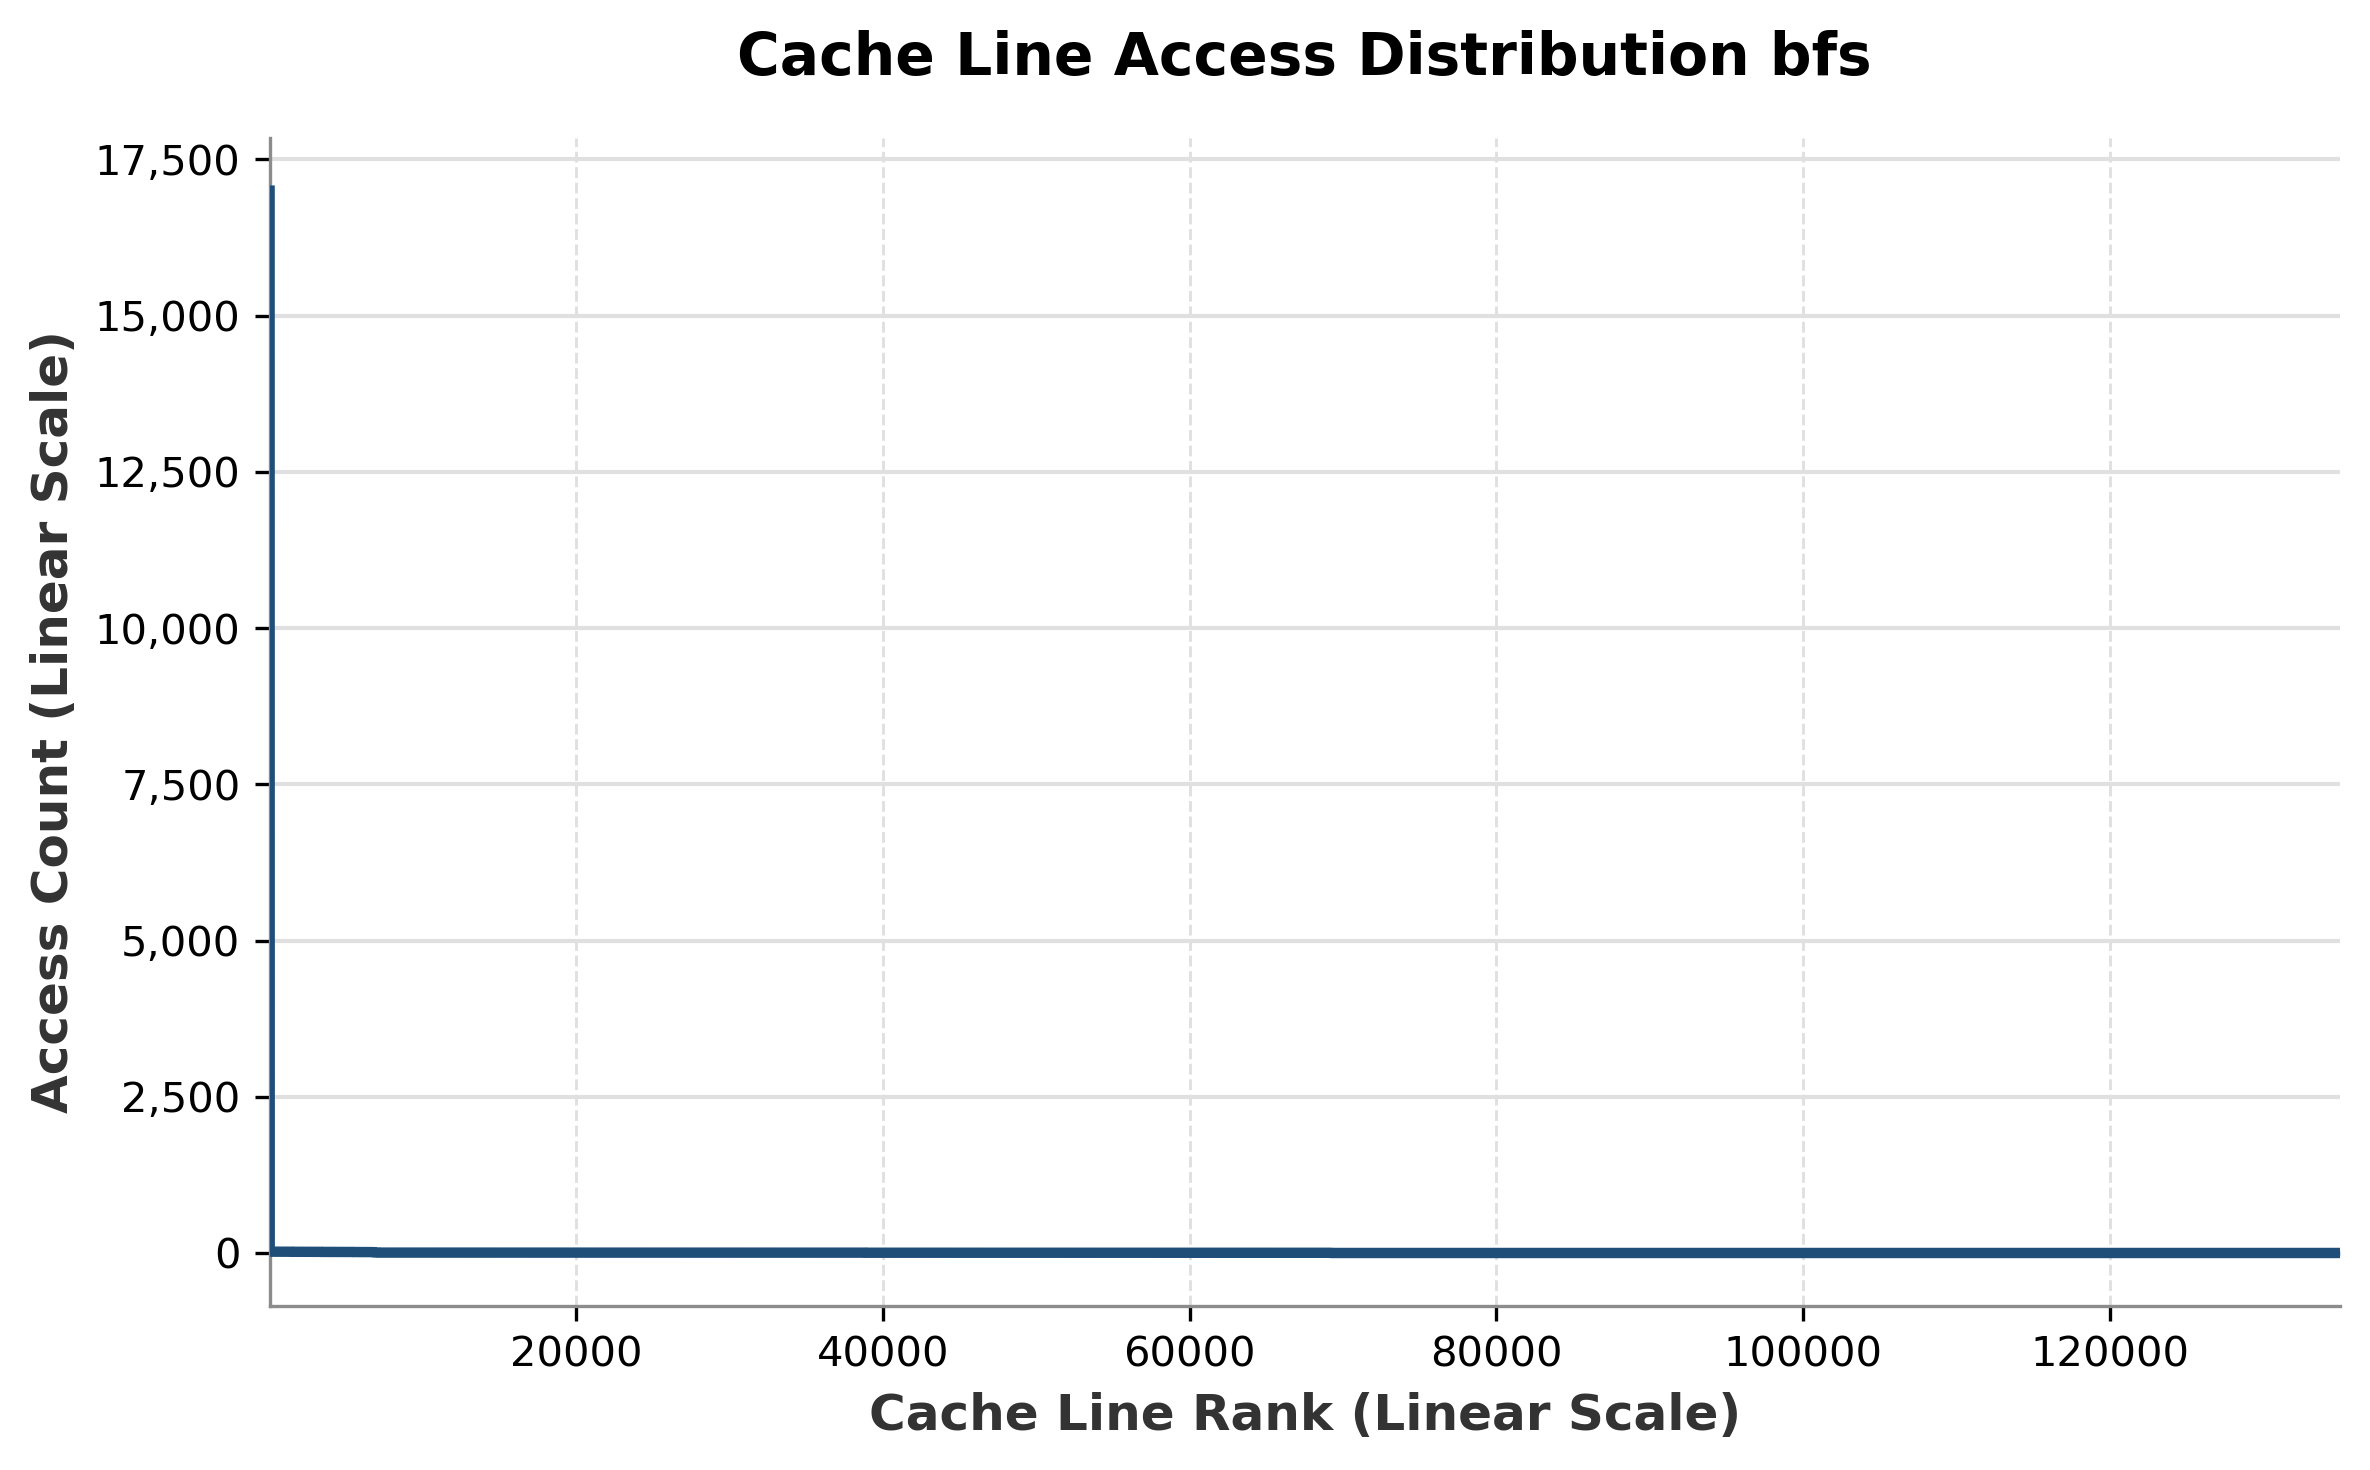

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/bfs_addr_access_count_ratio.png


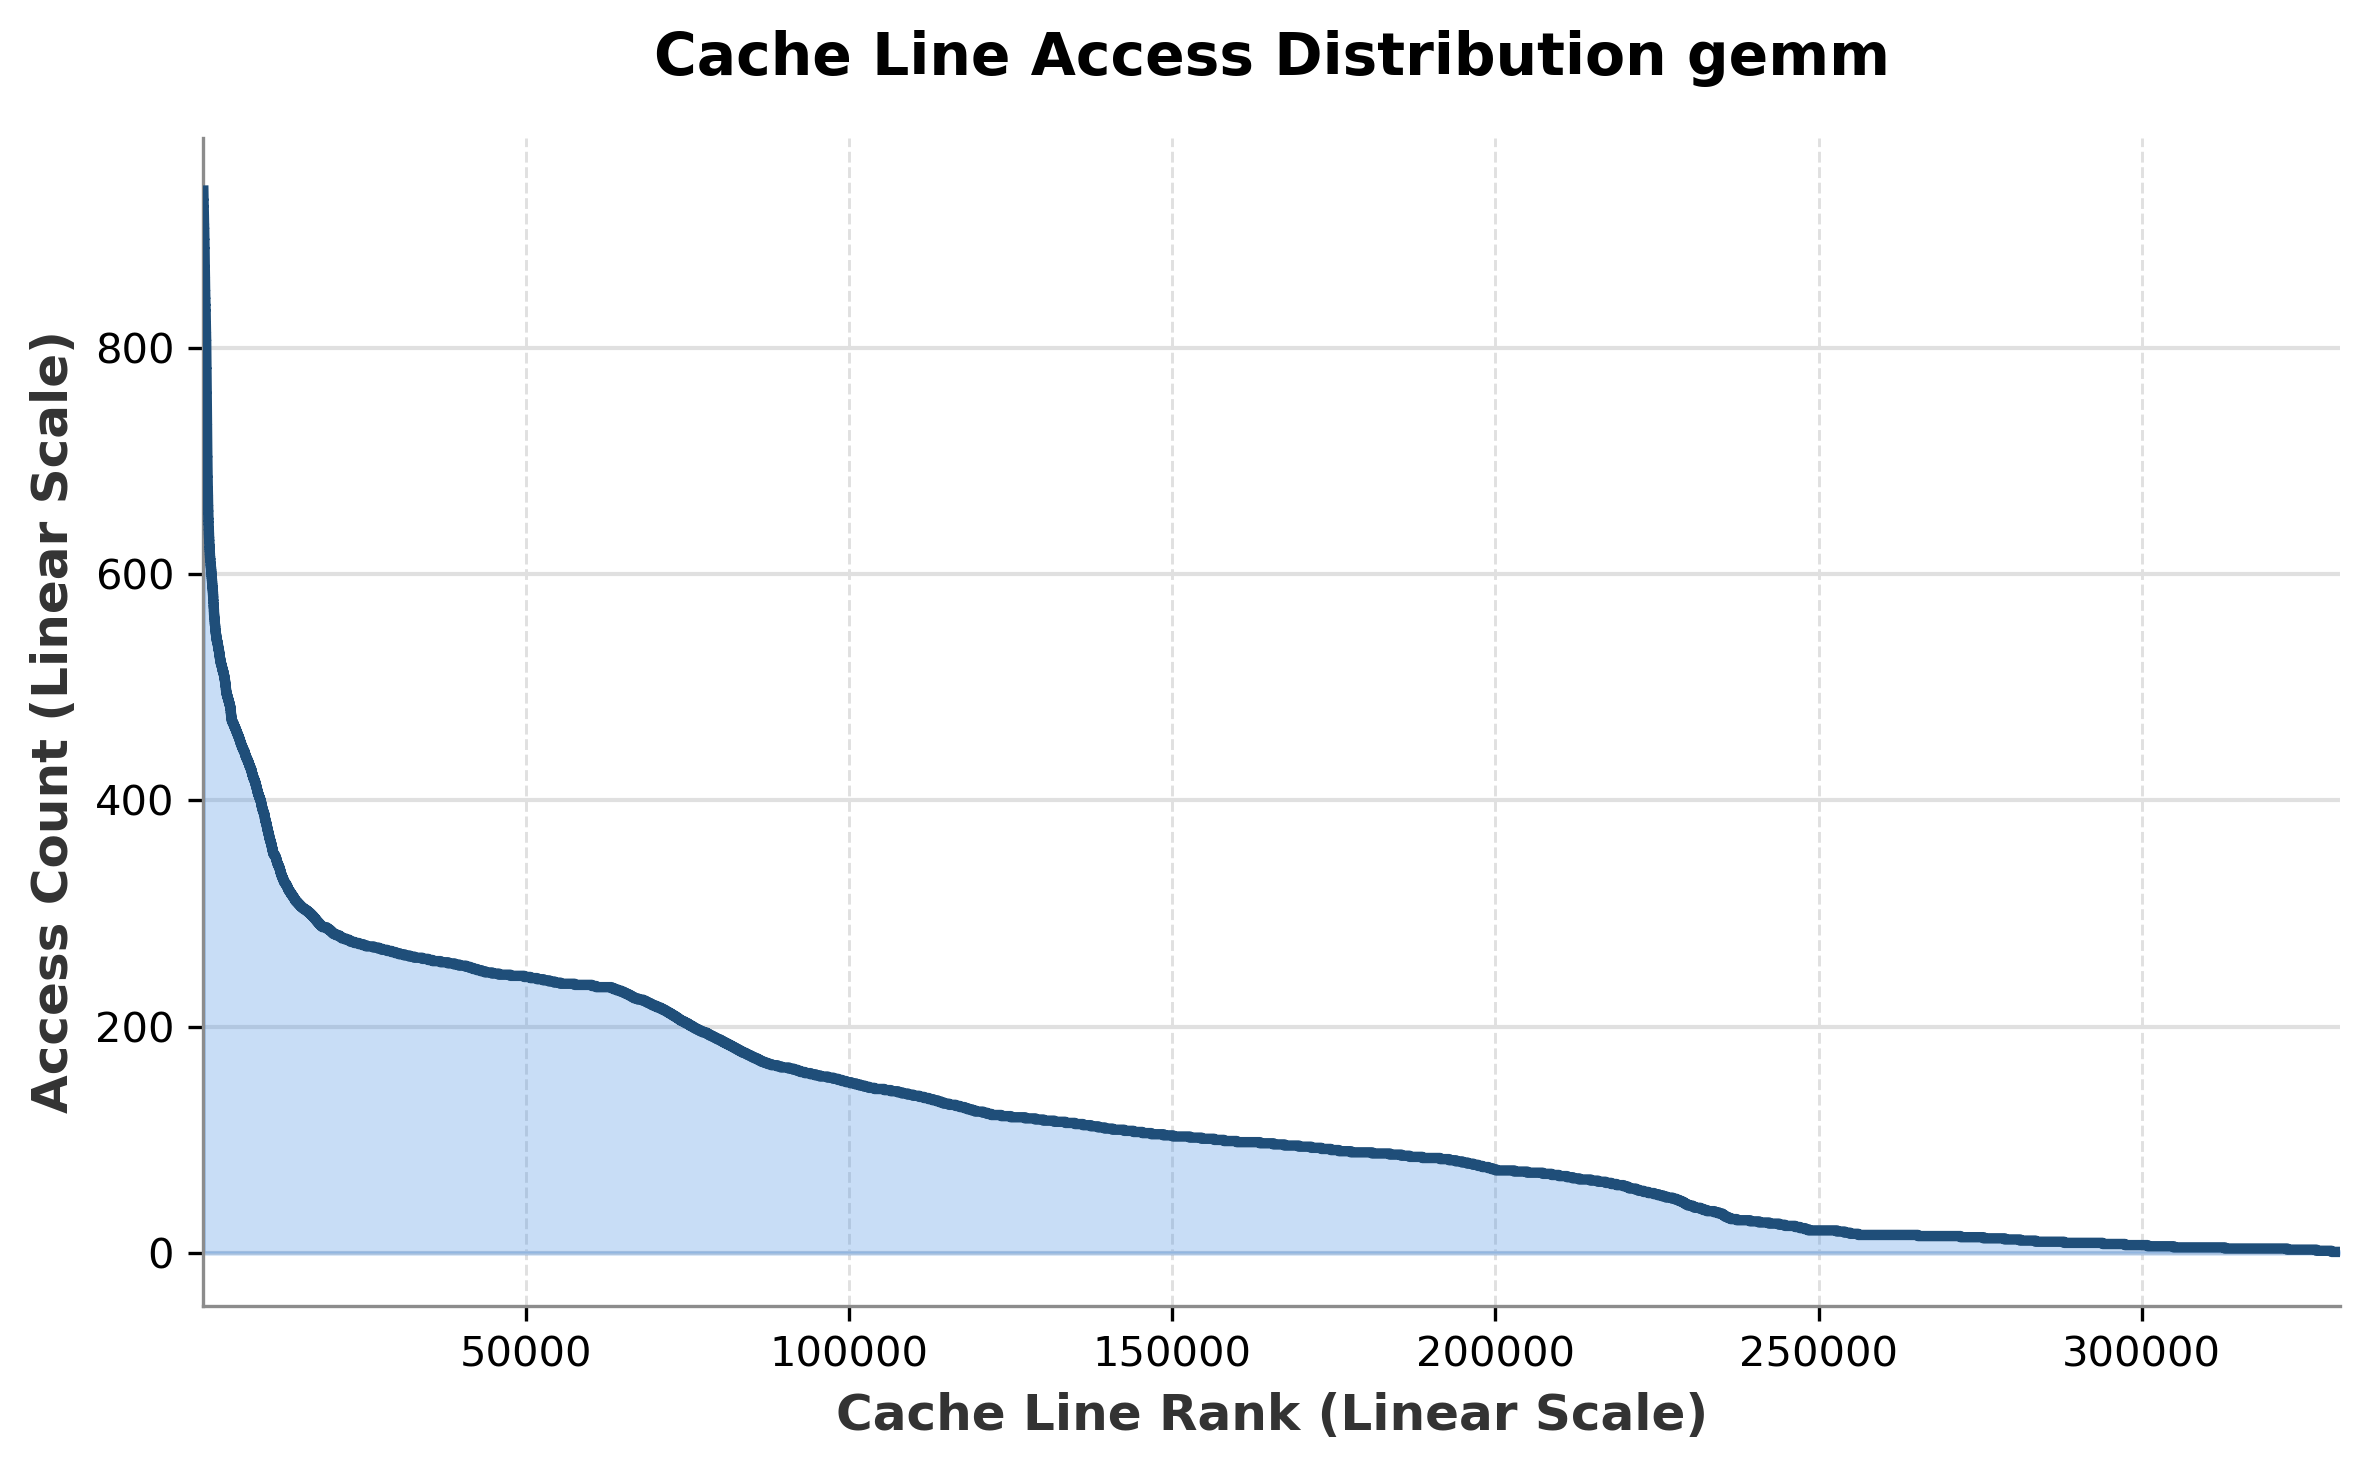

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/gemm_addr_access_count_ratio.png


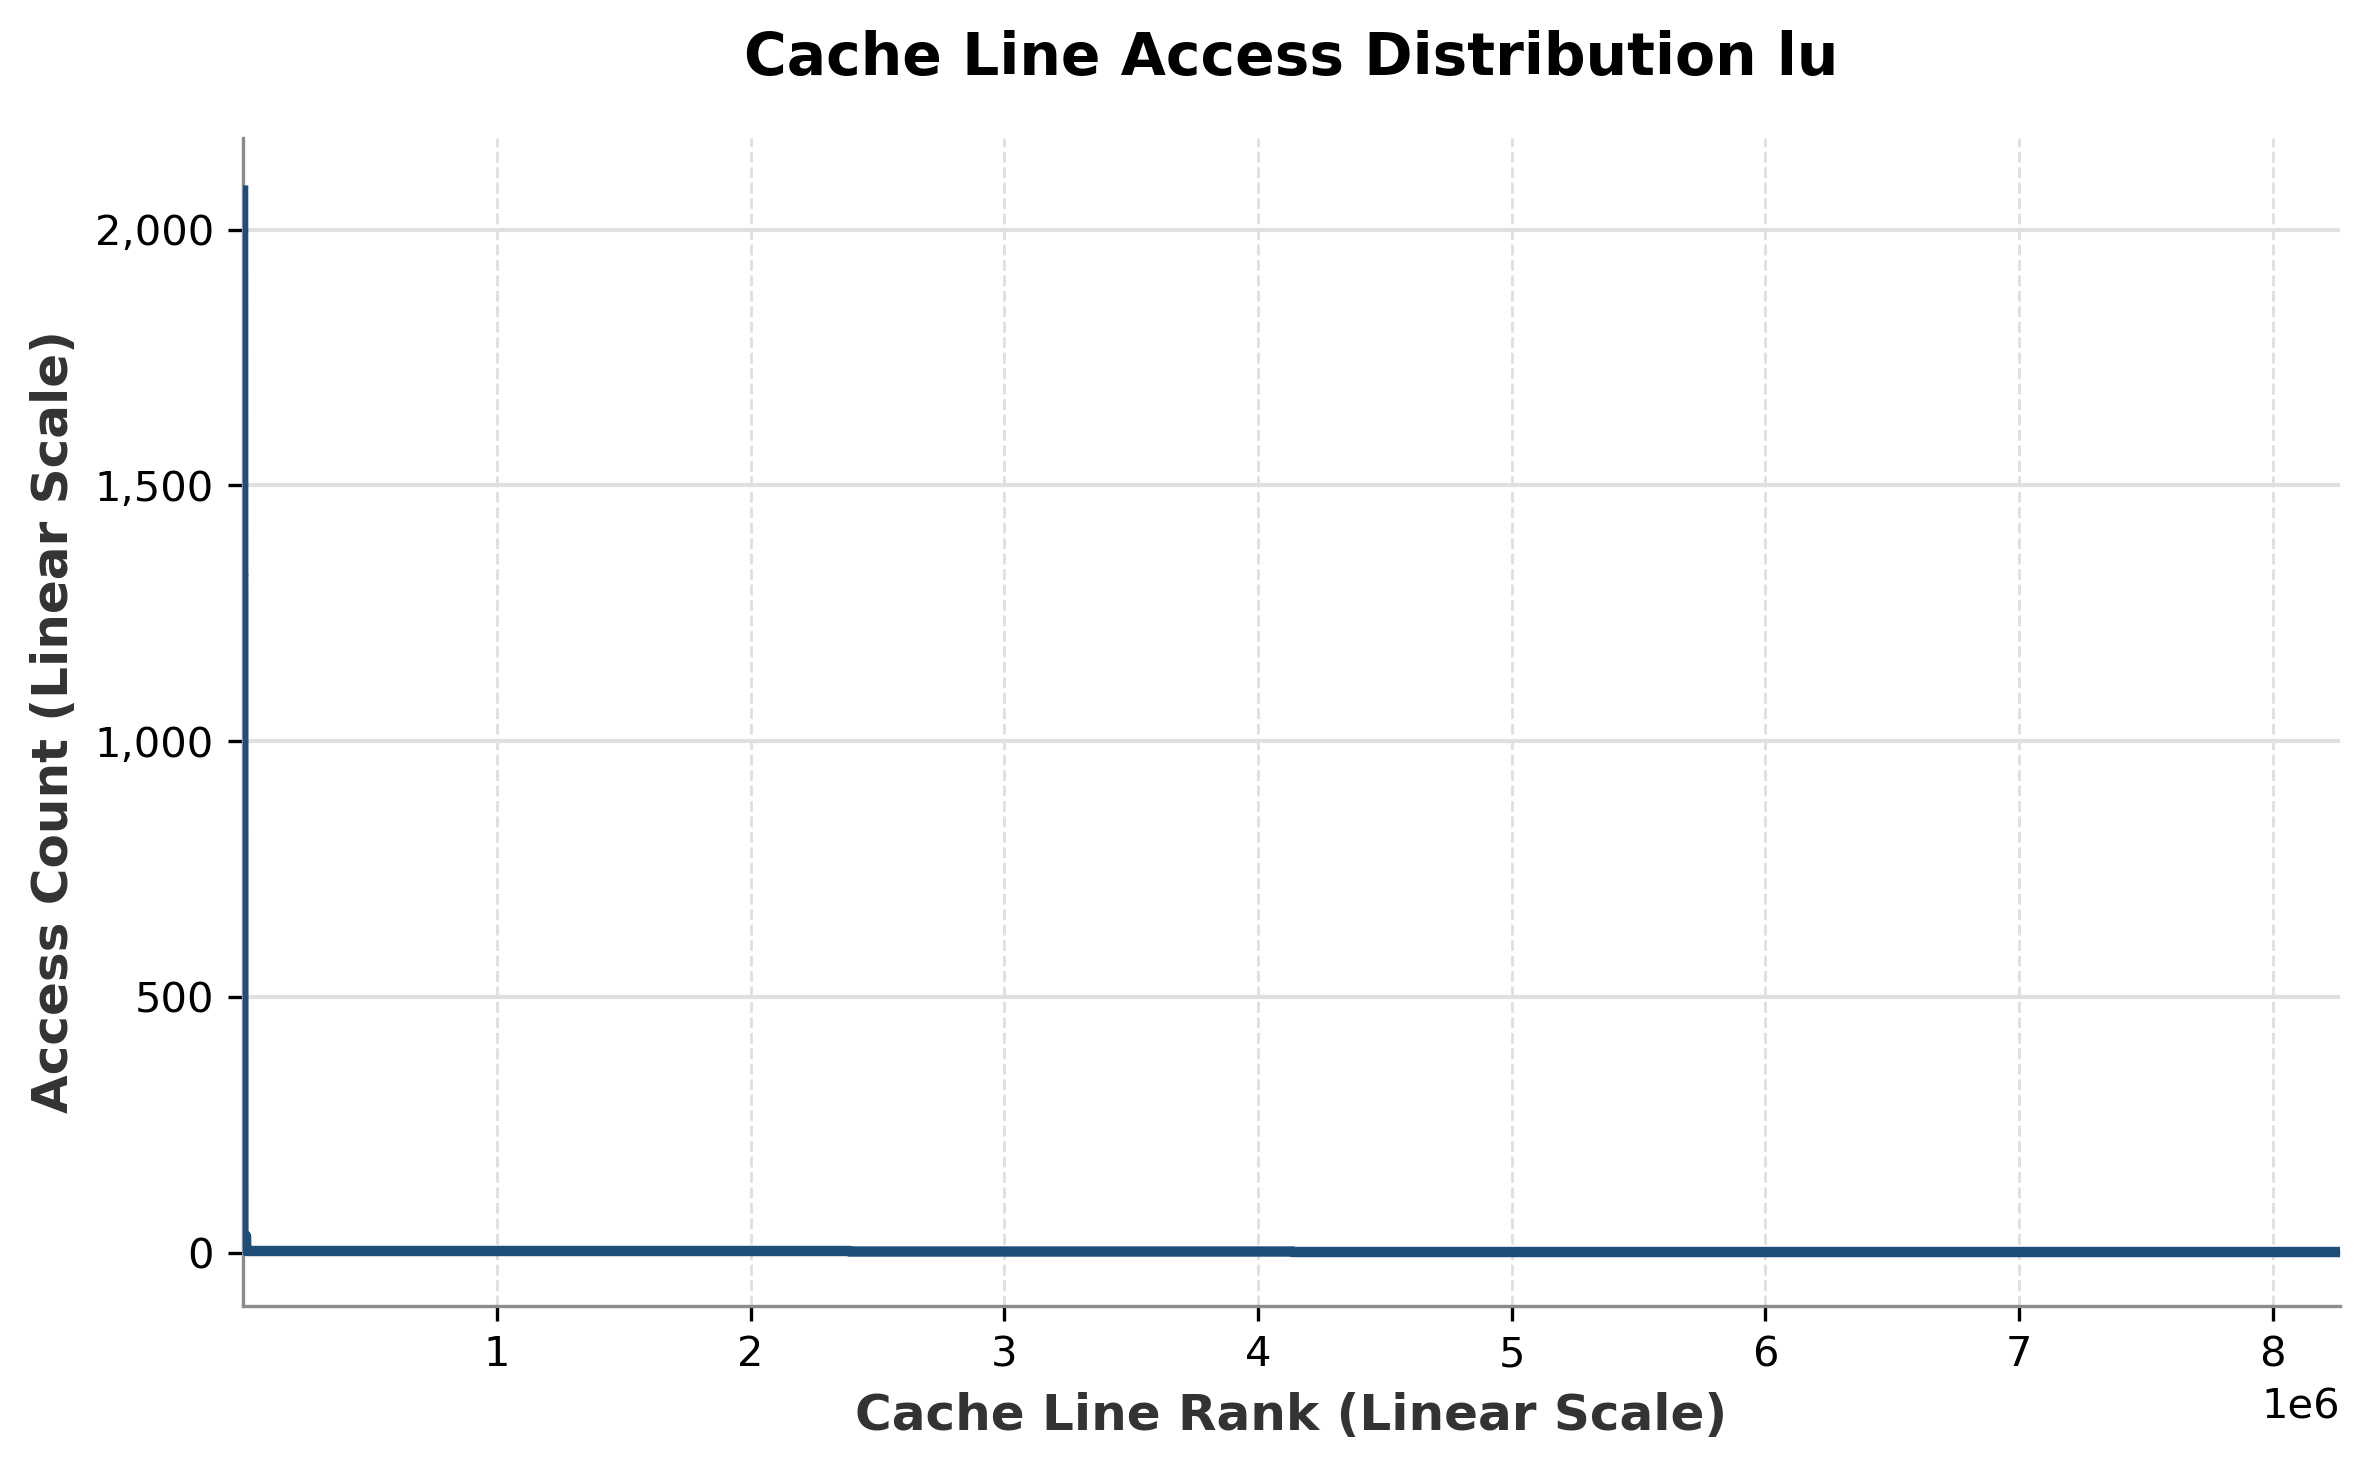

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/lu_addr_access_count_ratio.png


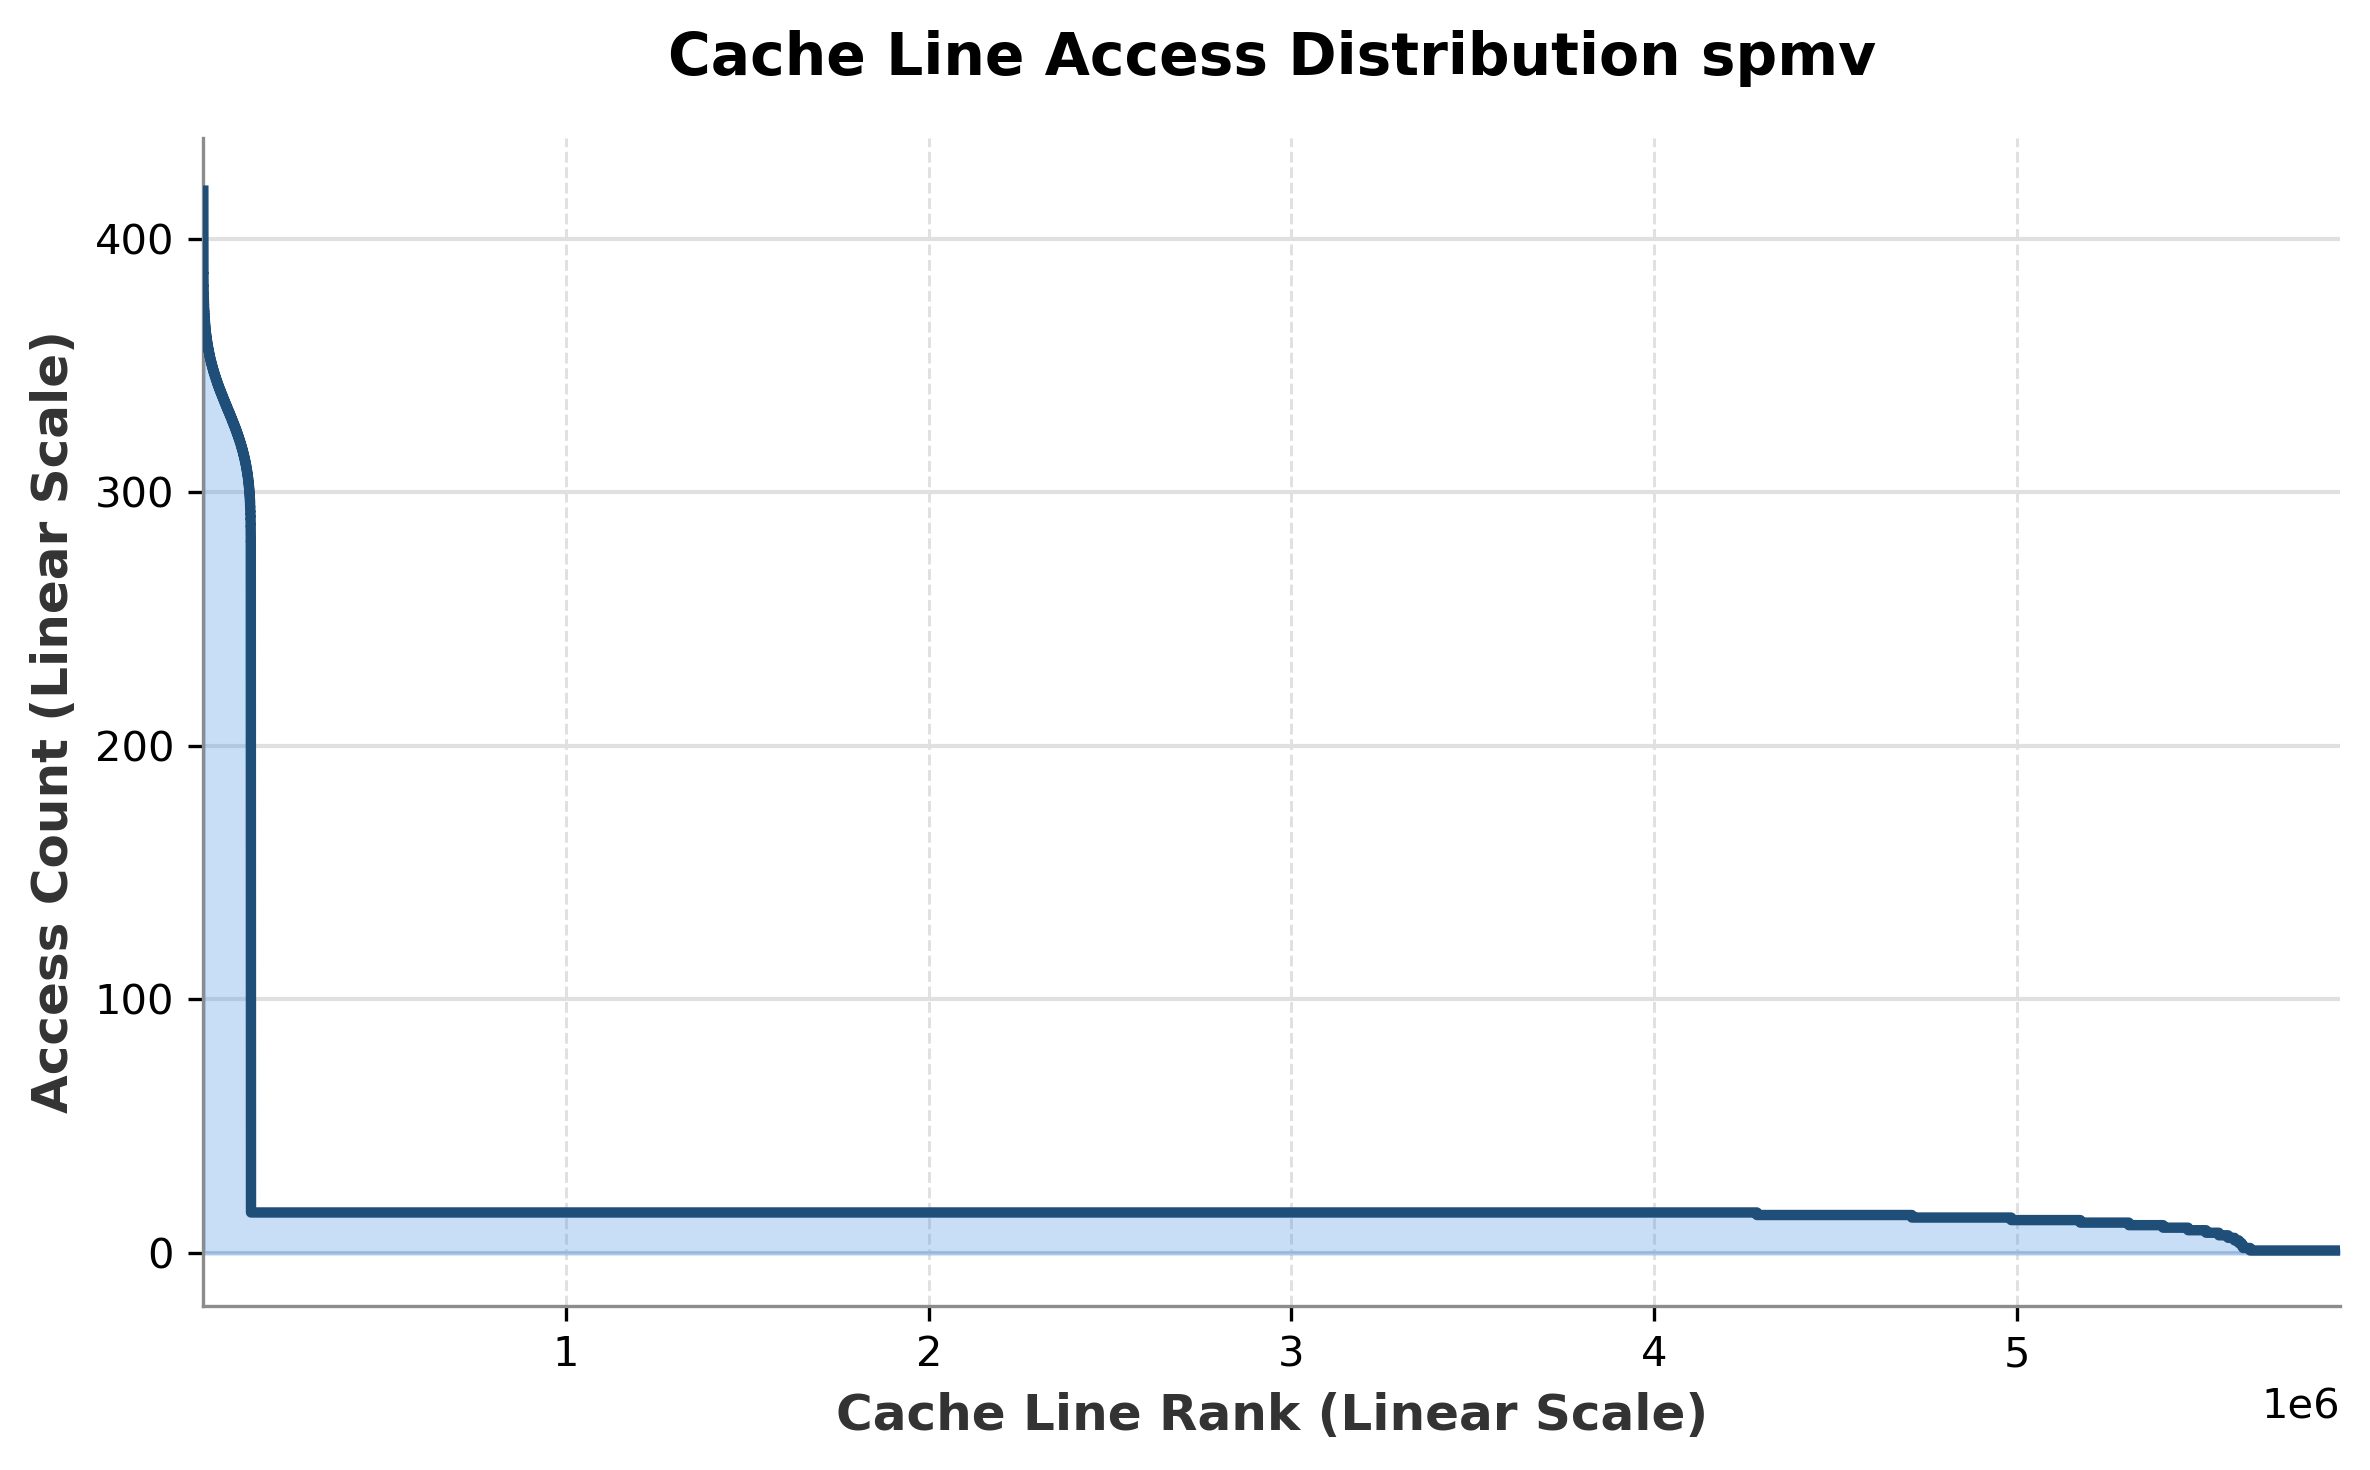

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/spmv_addr_access_count_ratio.png


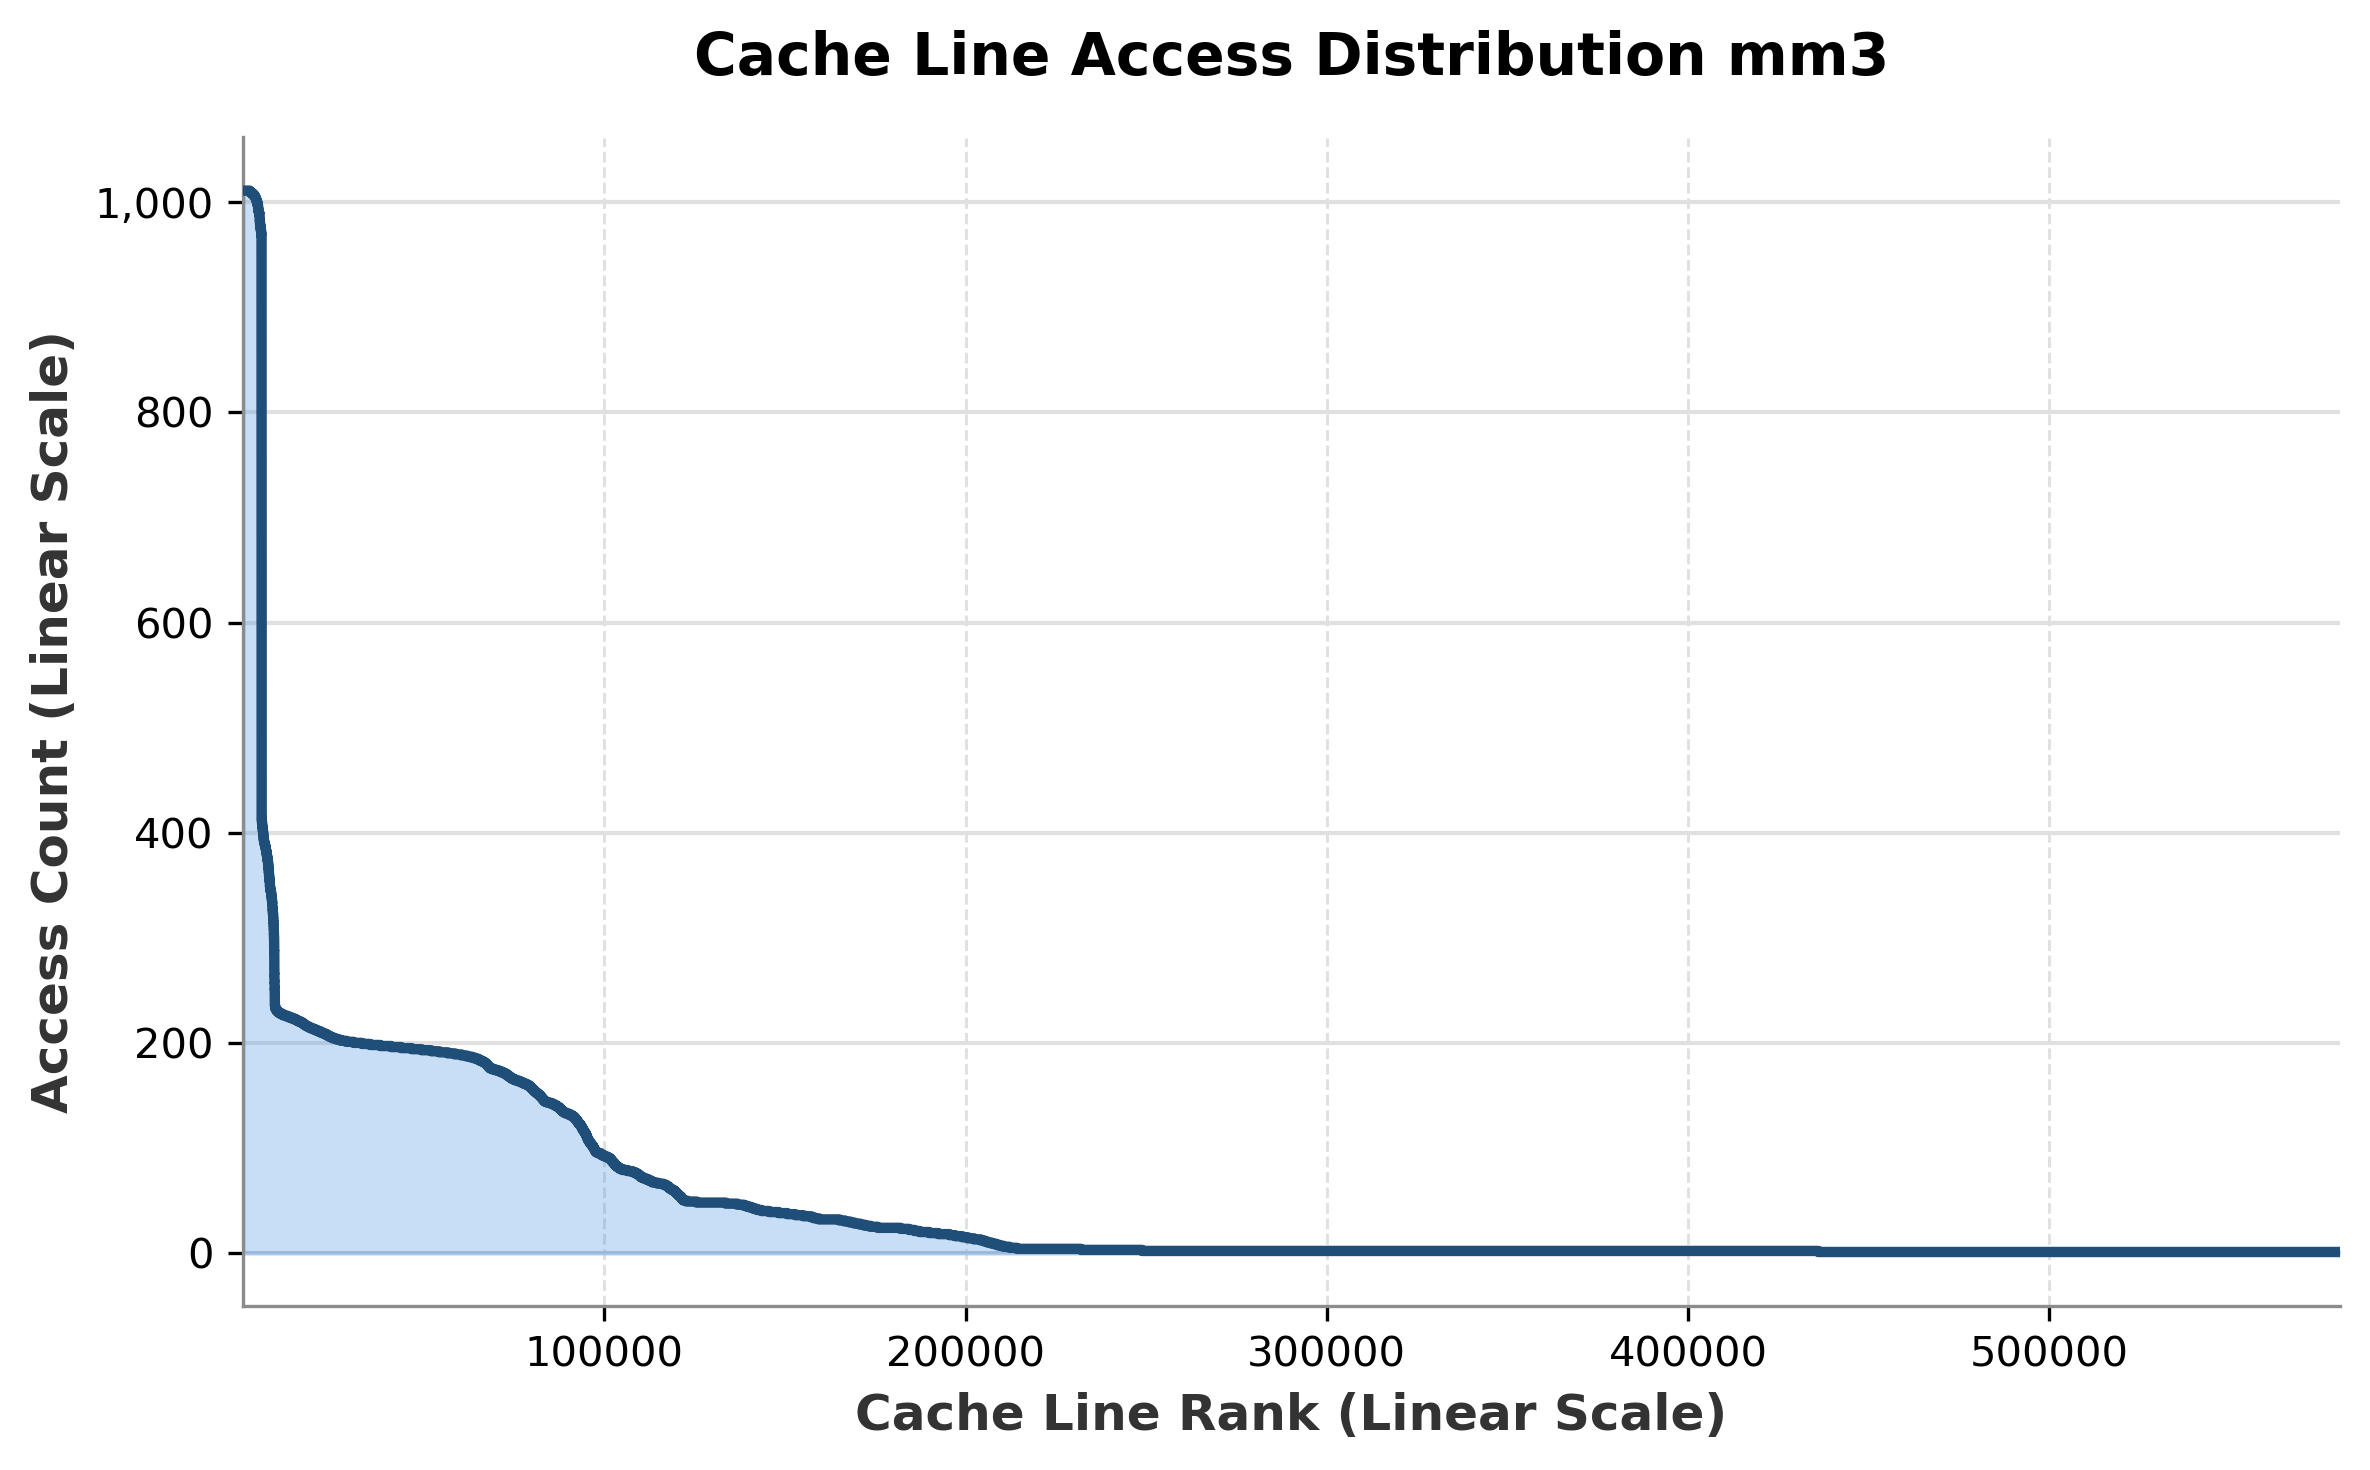

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/mm3_addr_access_count_ratio.png


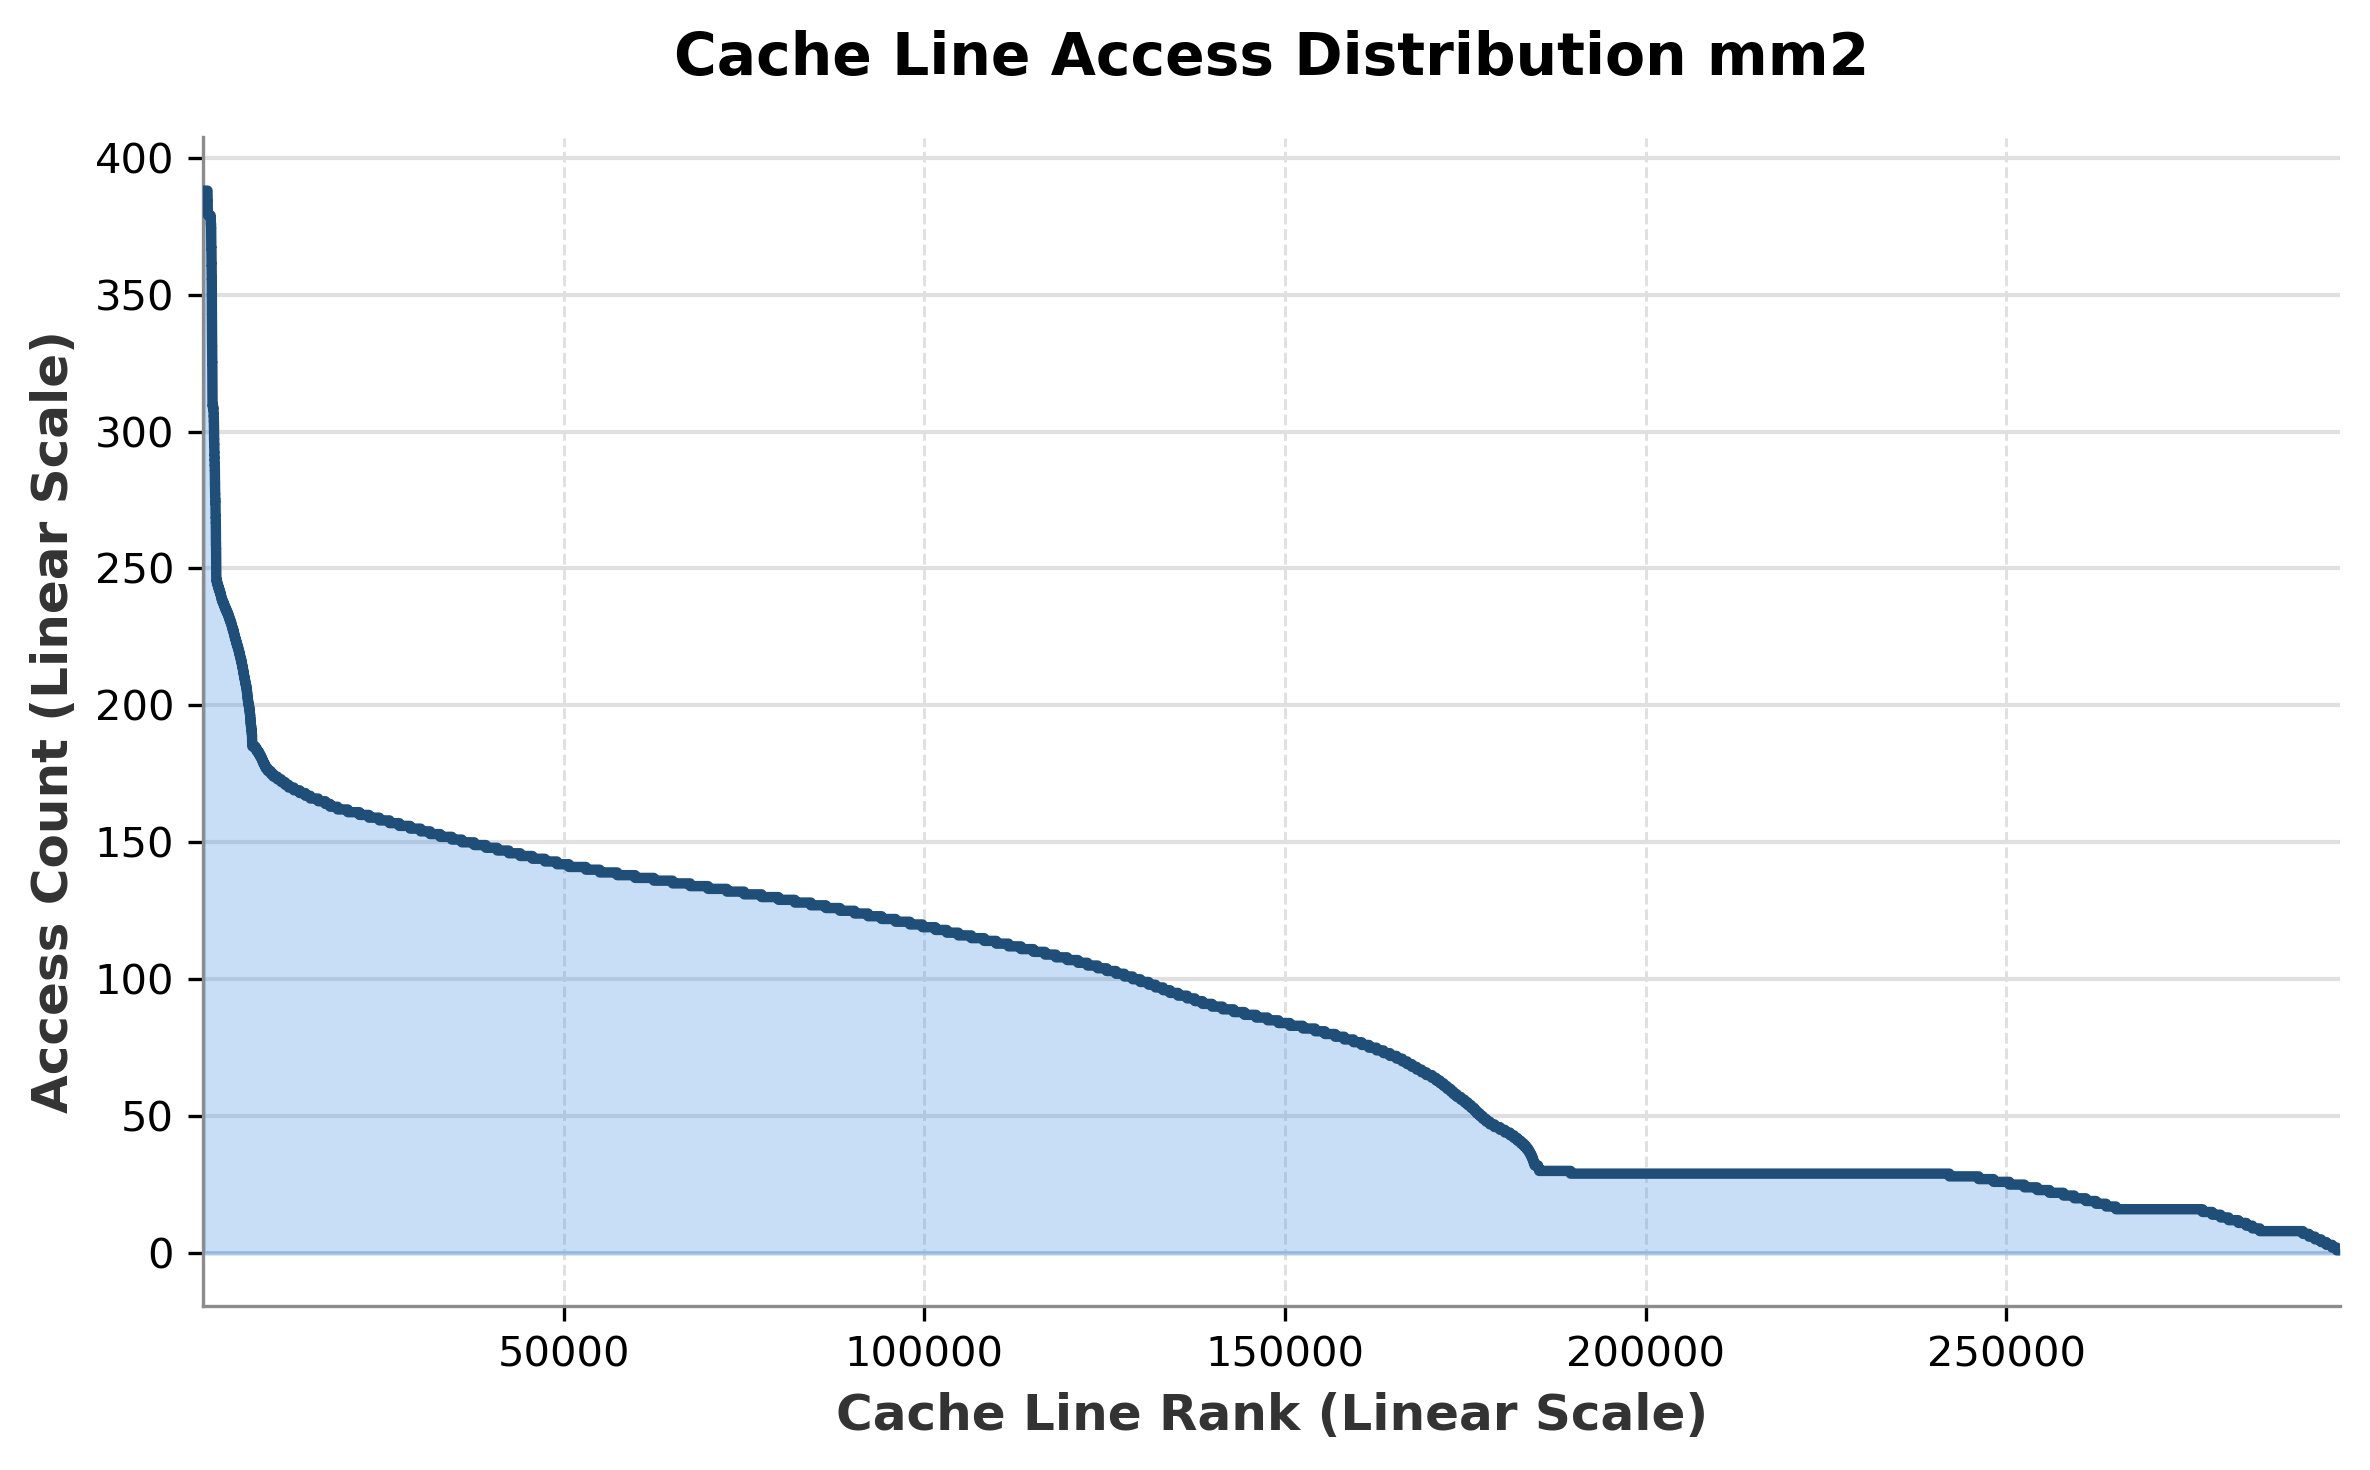

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/mm2_addr_access_count_ratio.png


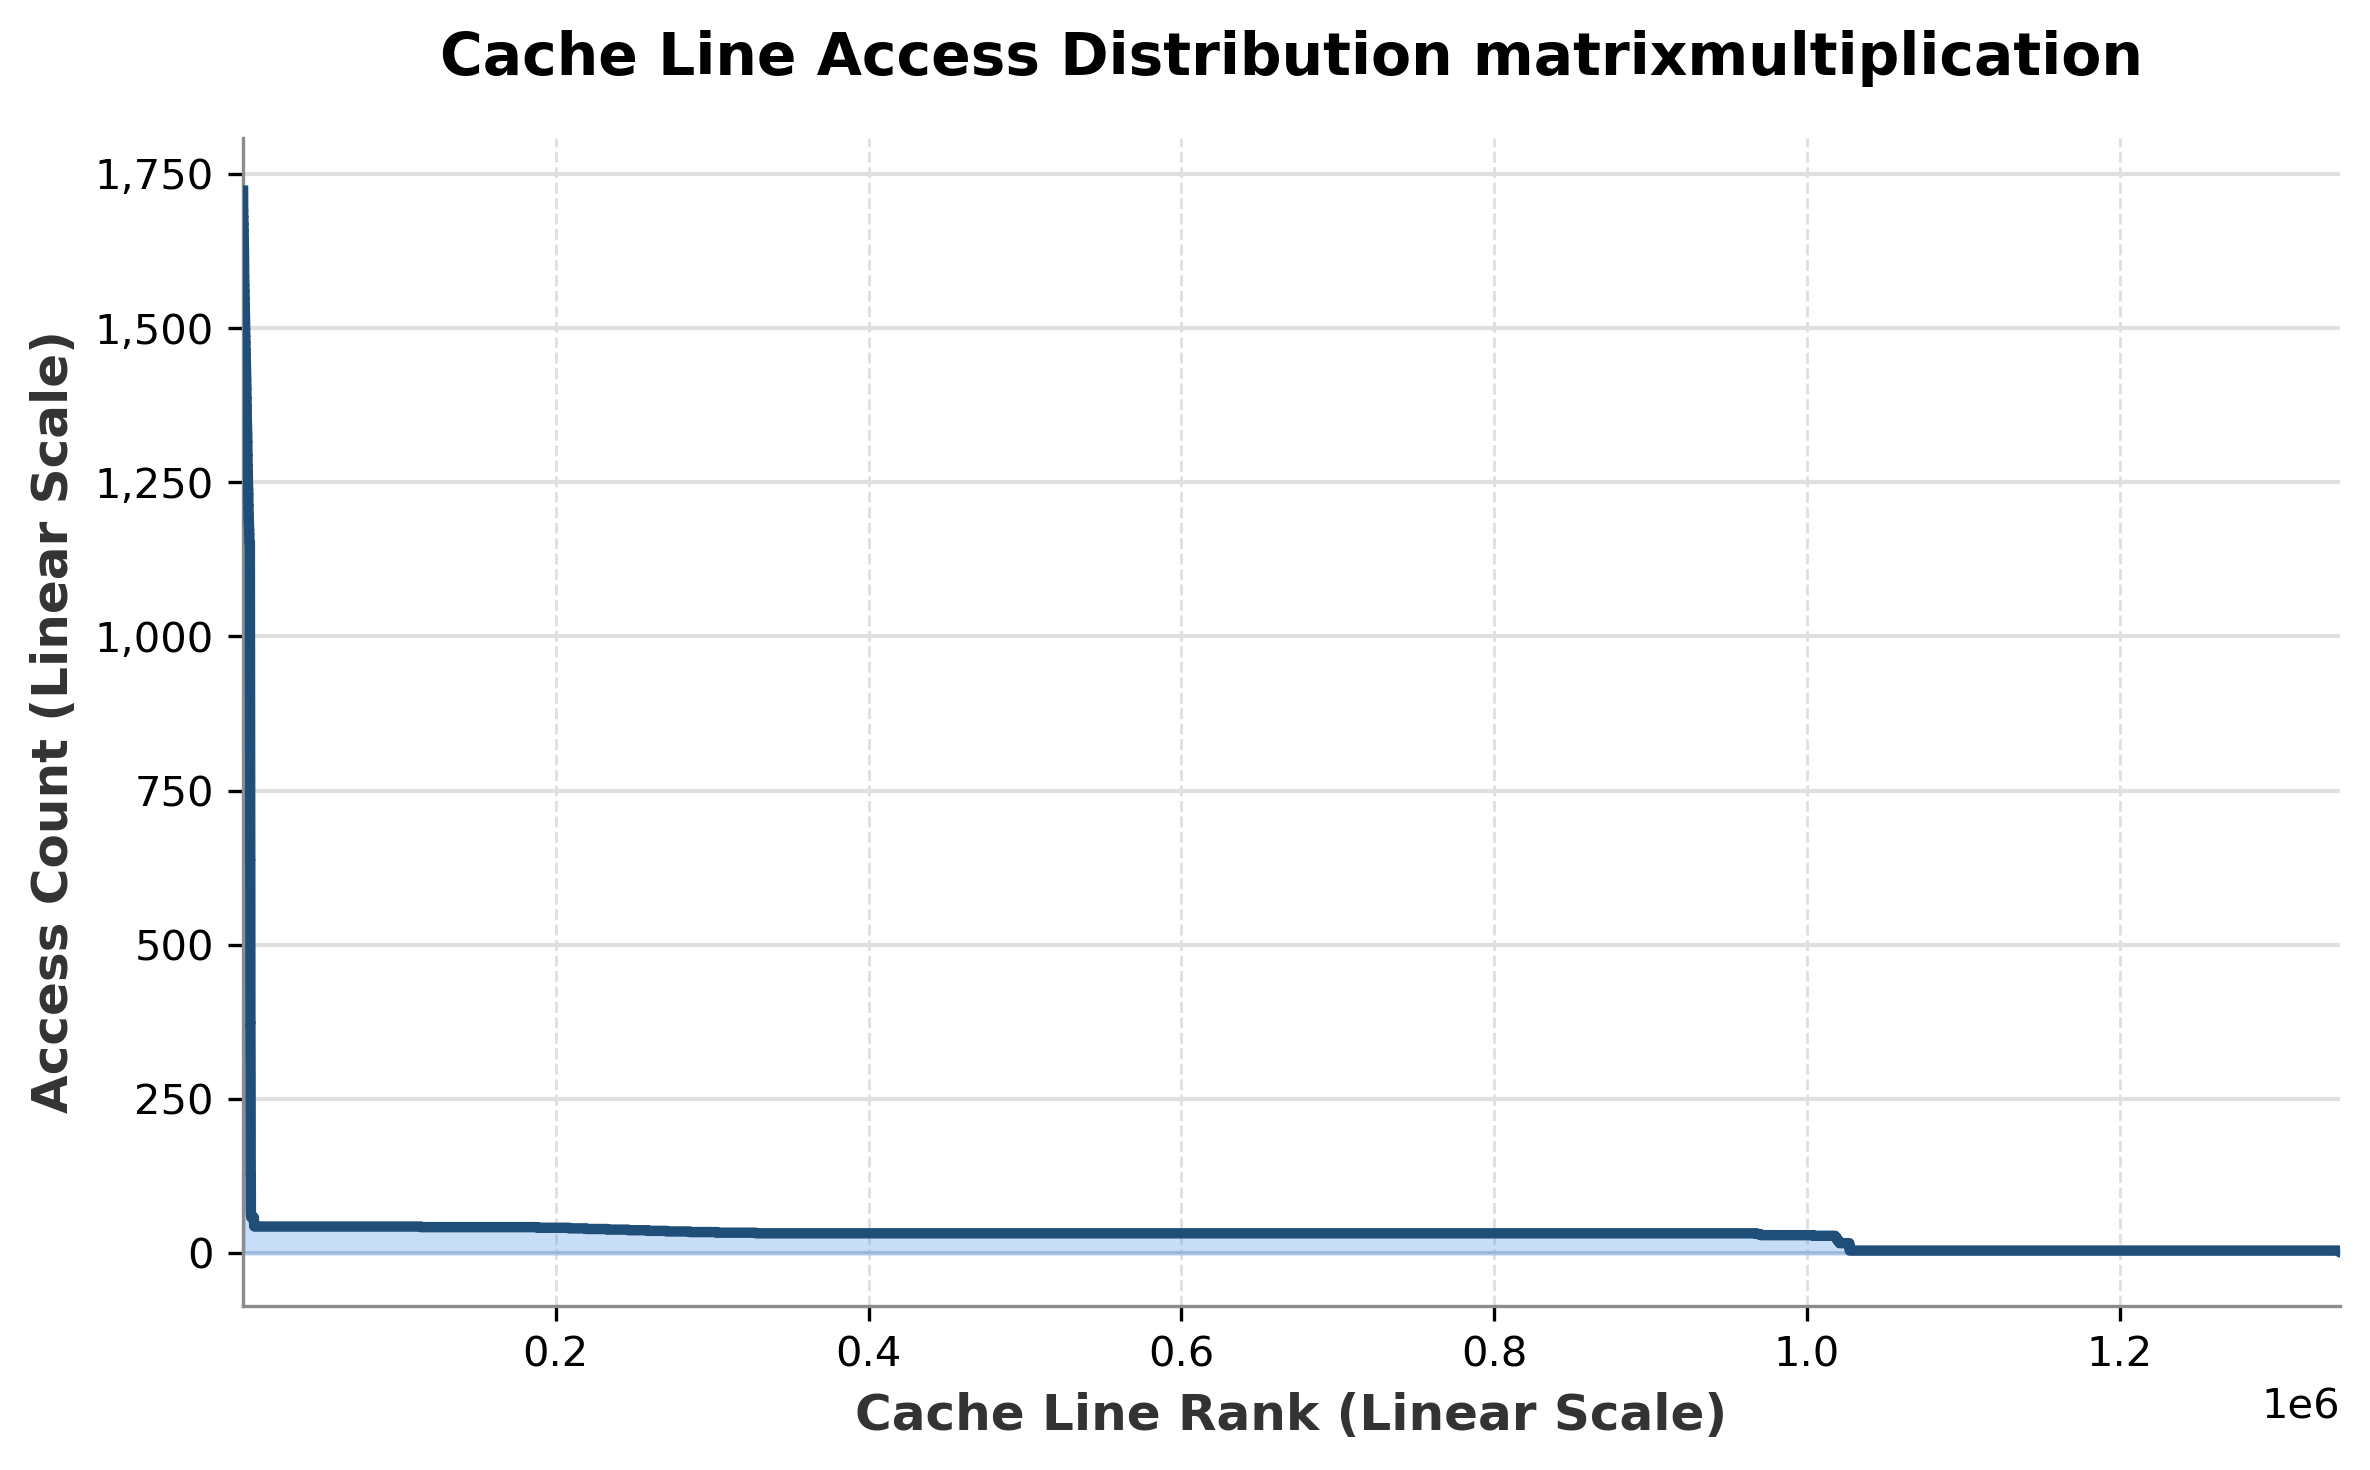

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/matrixmultiplication_addr_access_count_ratio.png


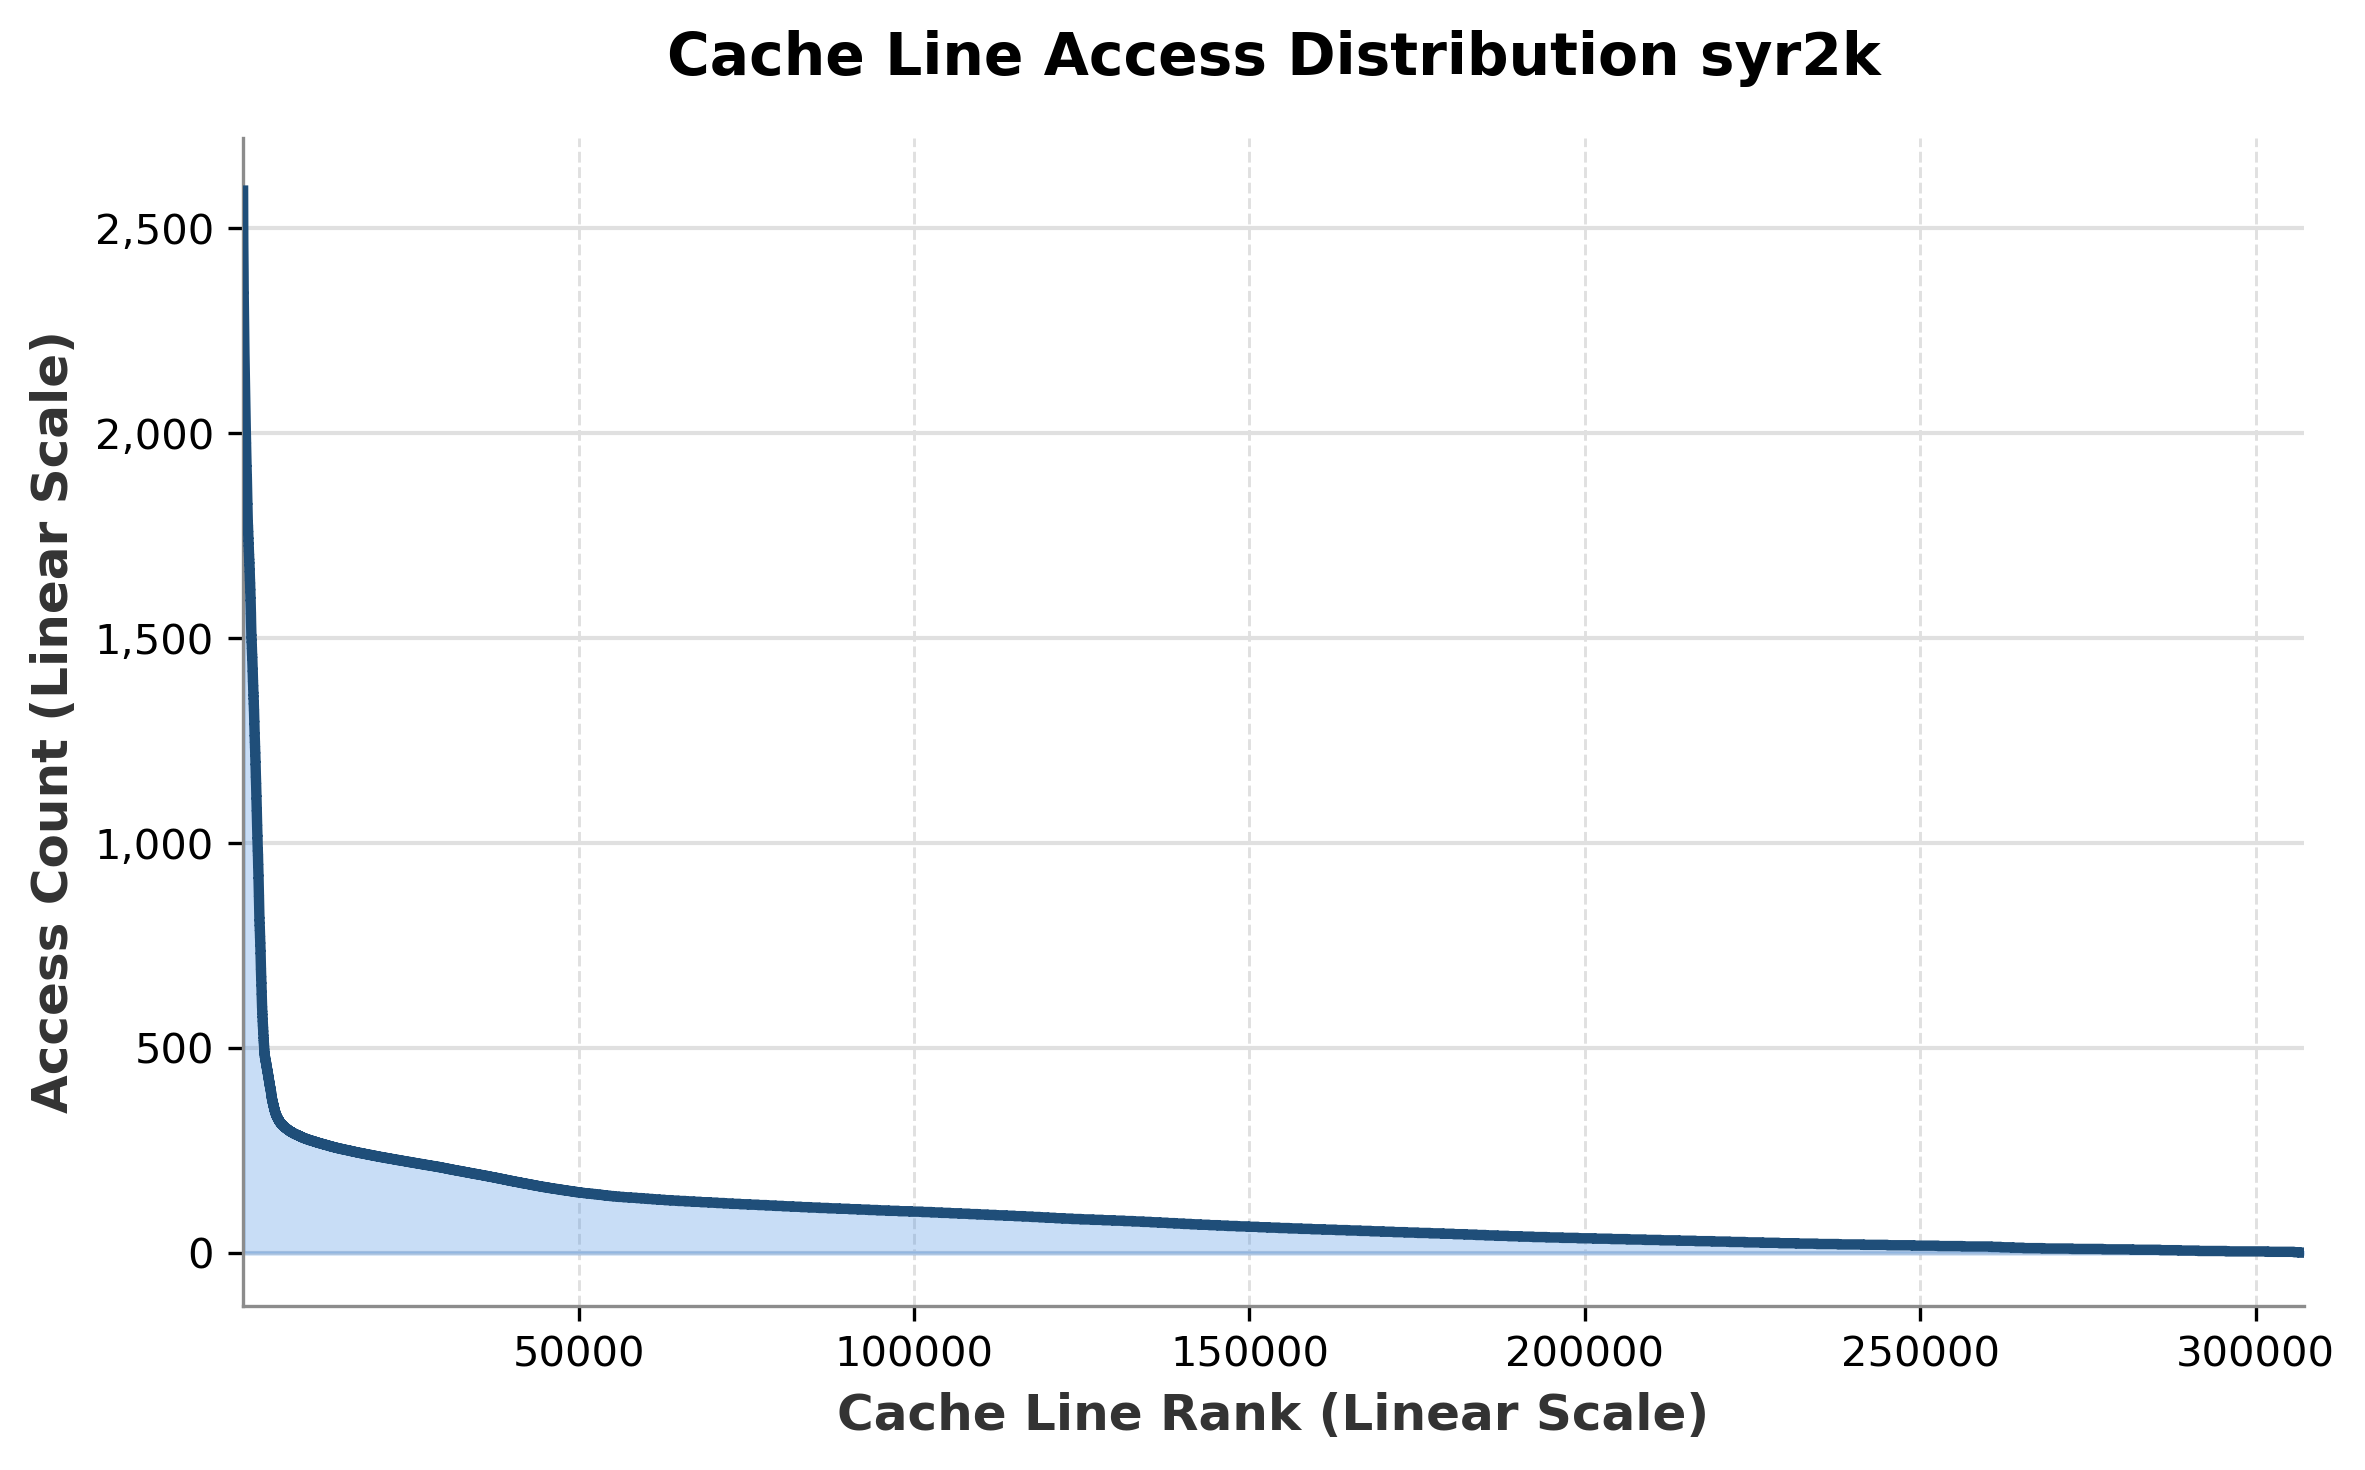

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/syr2k_addr_access_count_ratio.png
No /home/ehdgus7279/mgvm/results/memory-traces/20260221-223953/expanded/gups_mesh_6x6_memory_trace.csv, skip


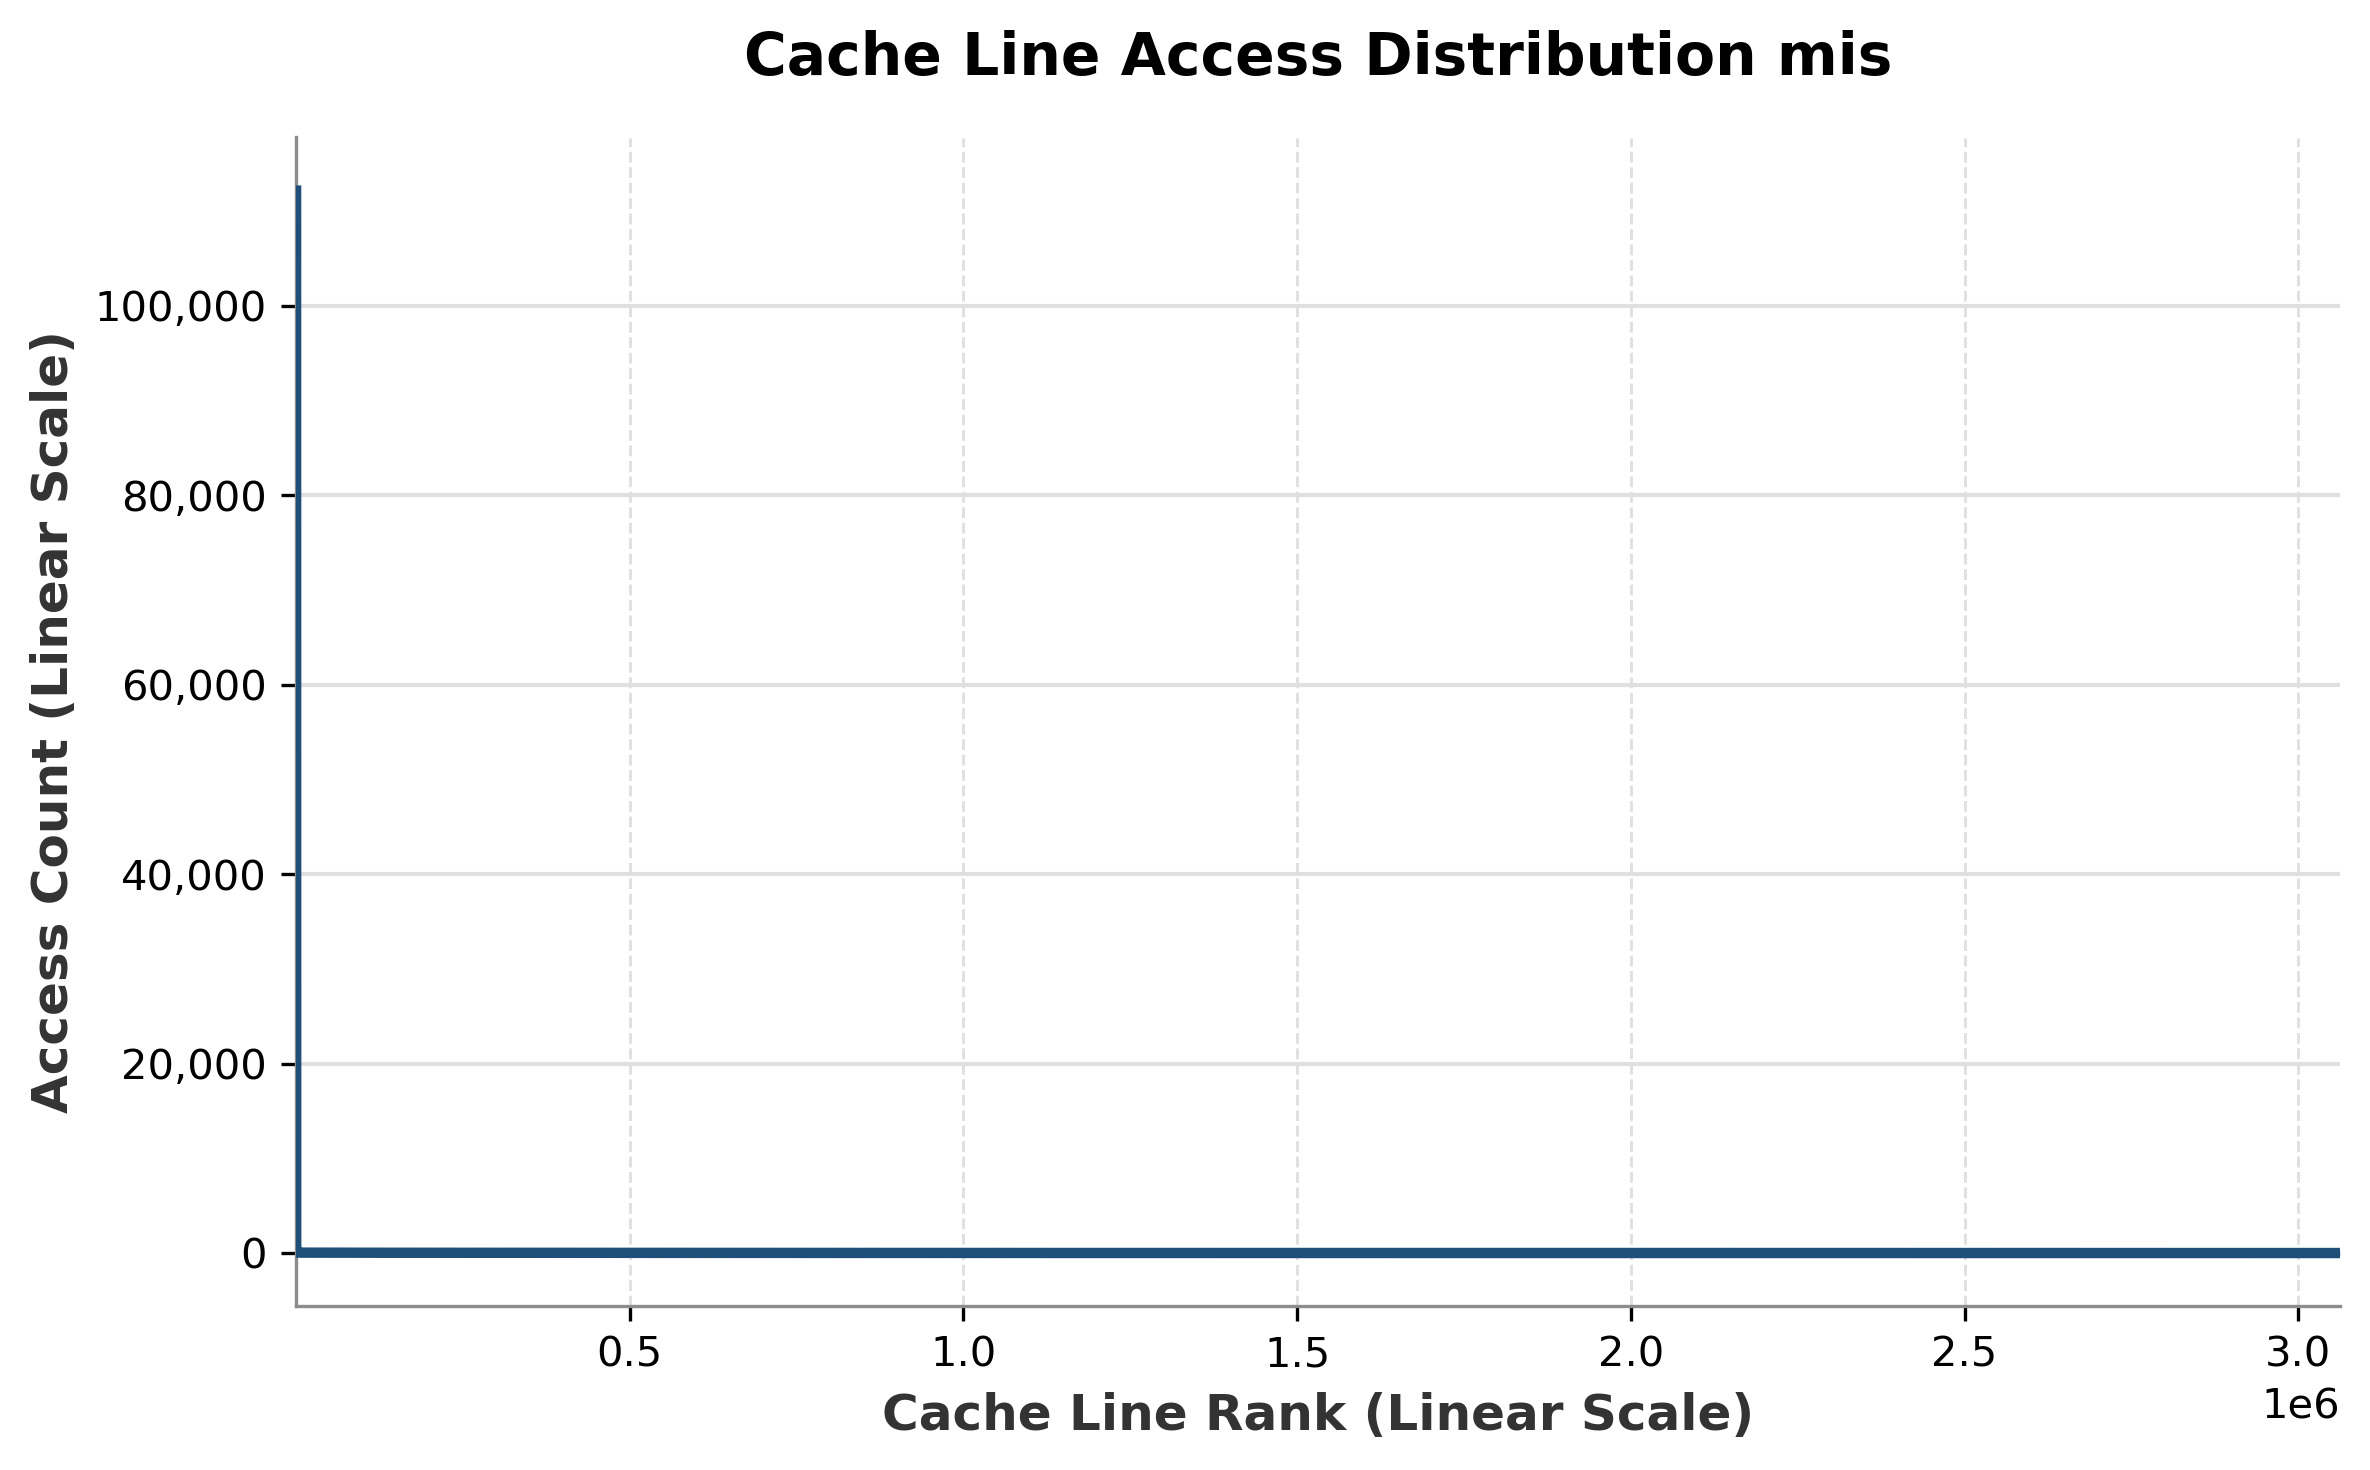

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/mis_addr_access_count_ratio.png


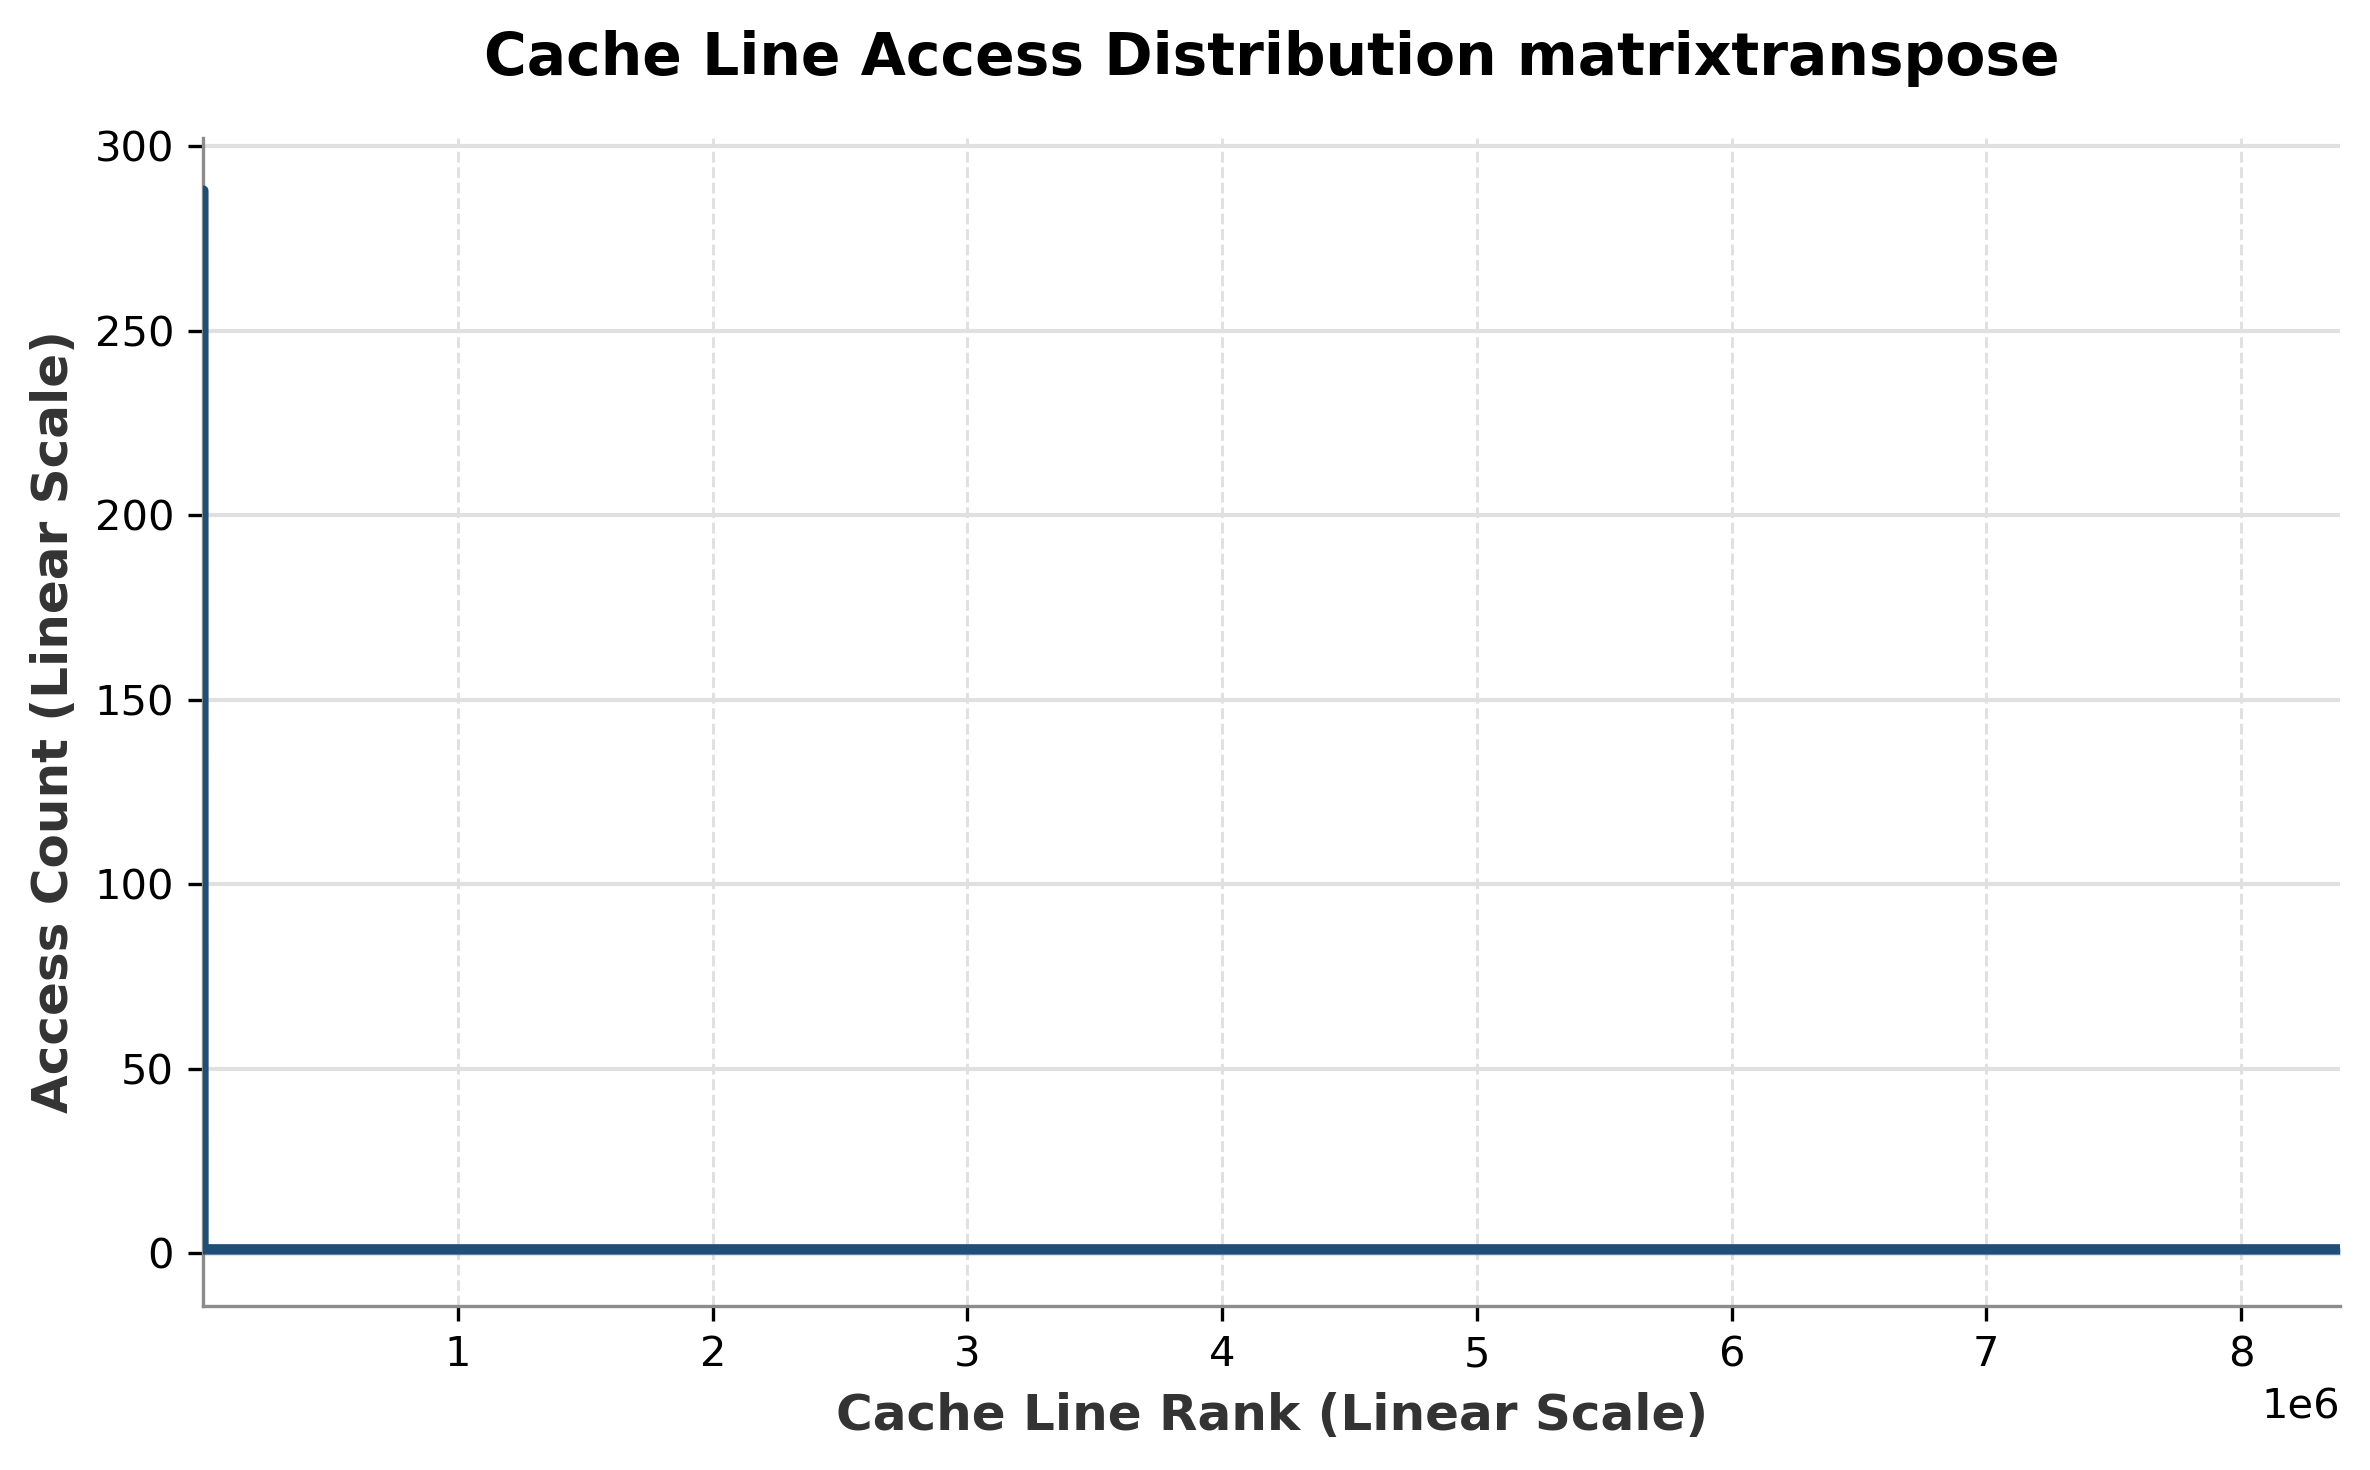

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/matrixtranspose_addr_access_count_ratio.png


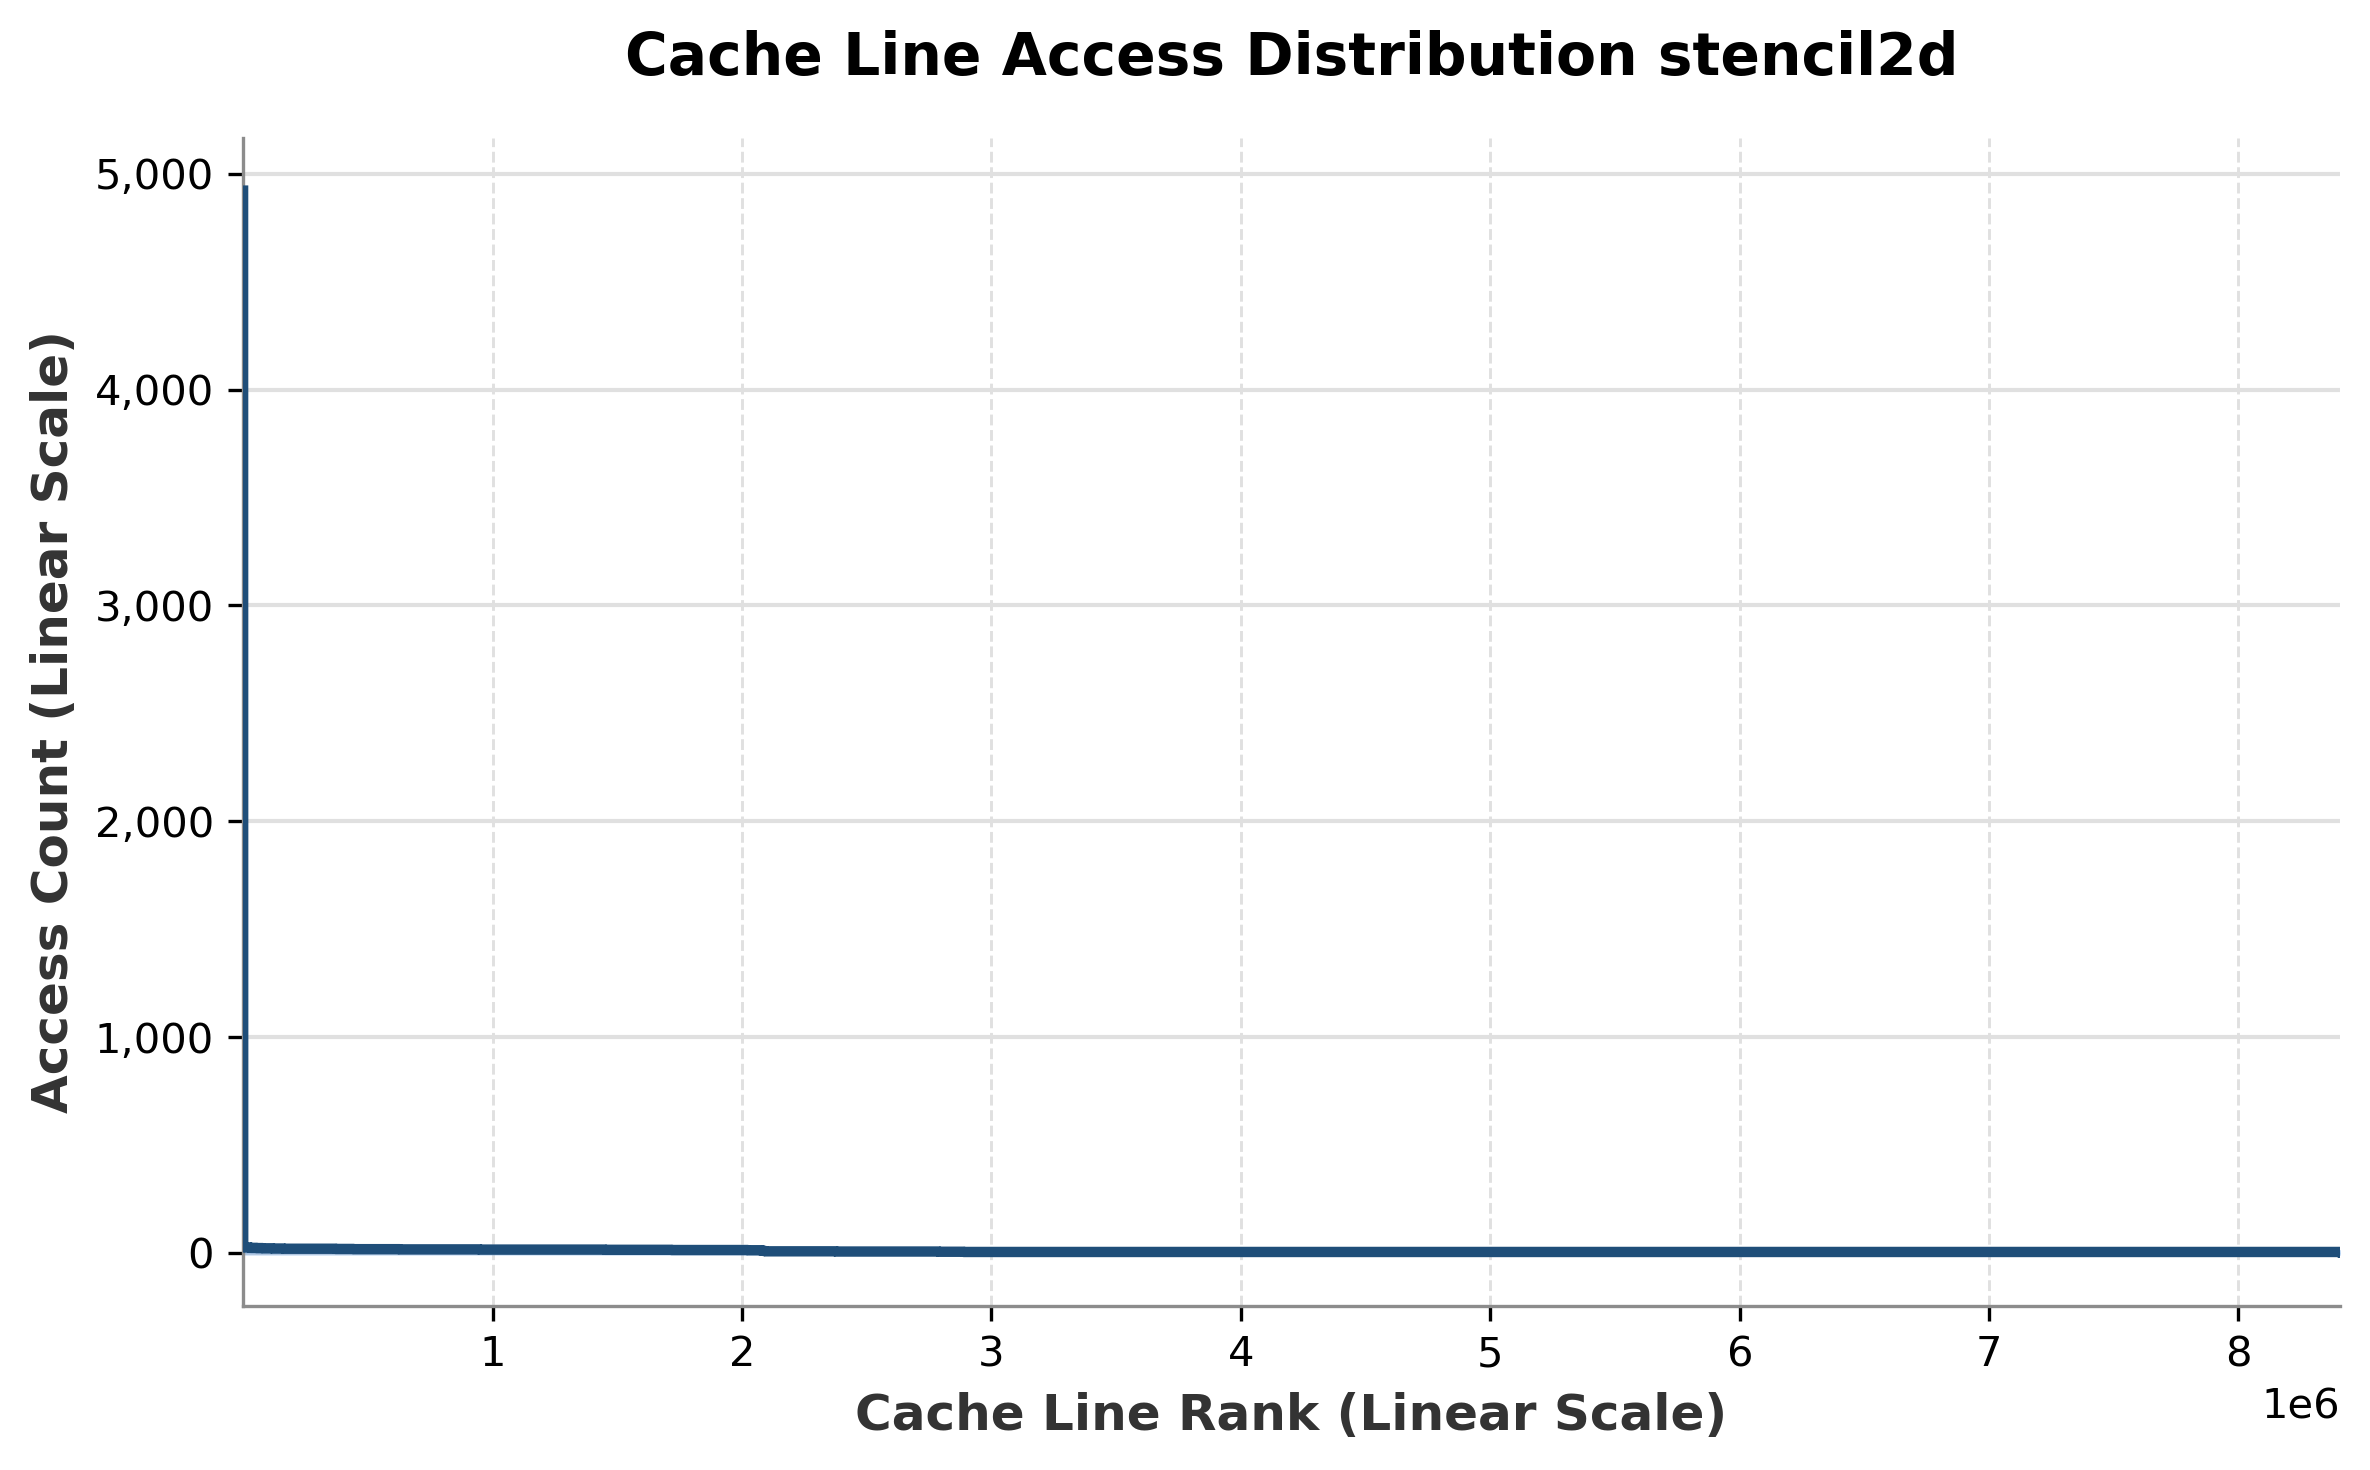

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/stencil2d_addr_access_count_ratio.png


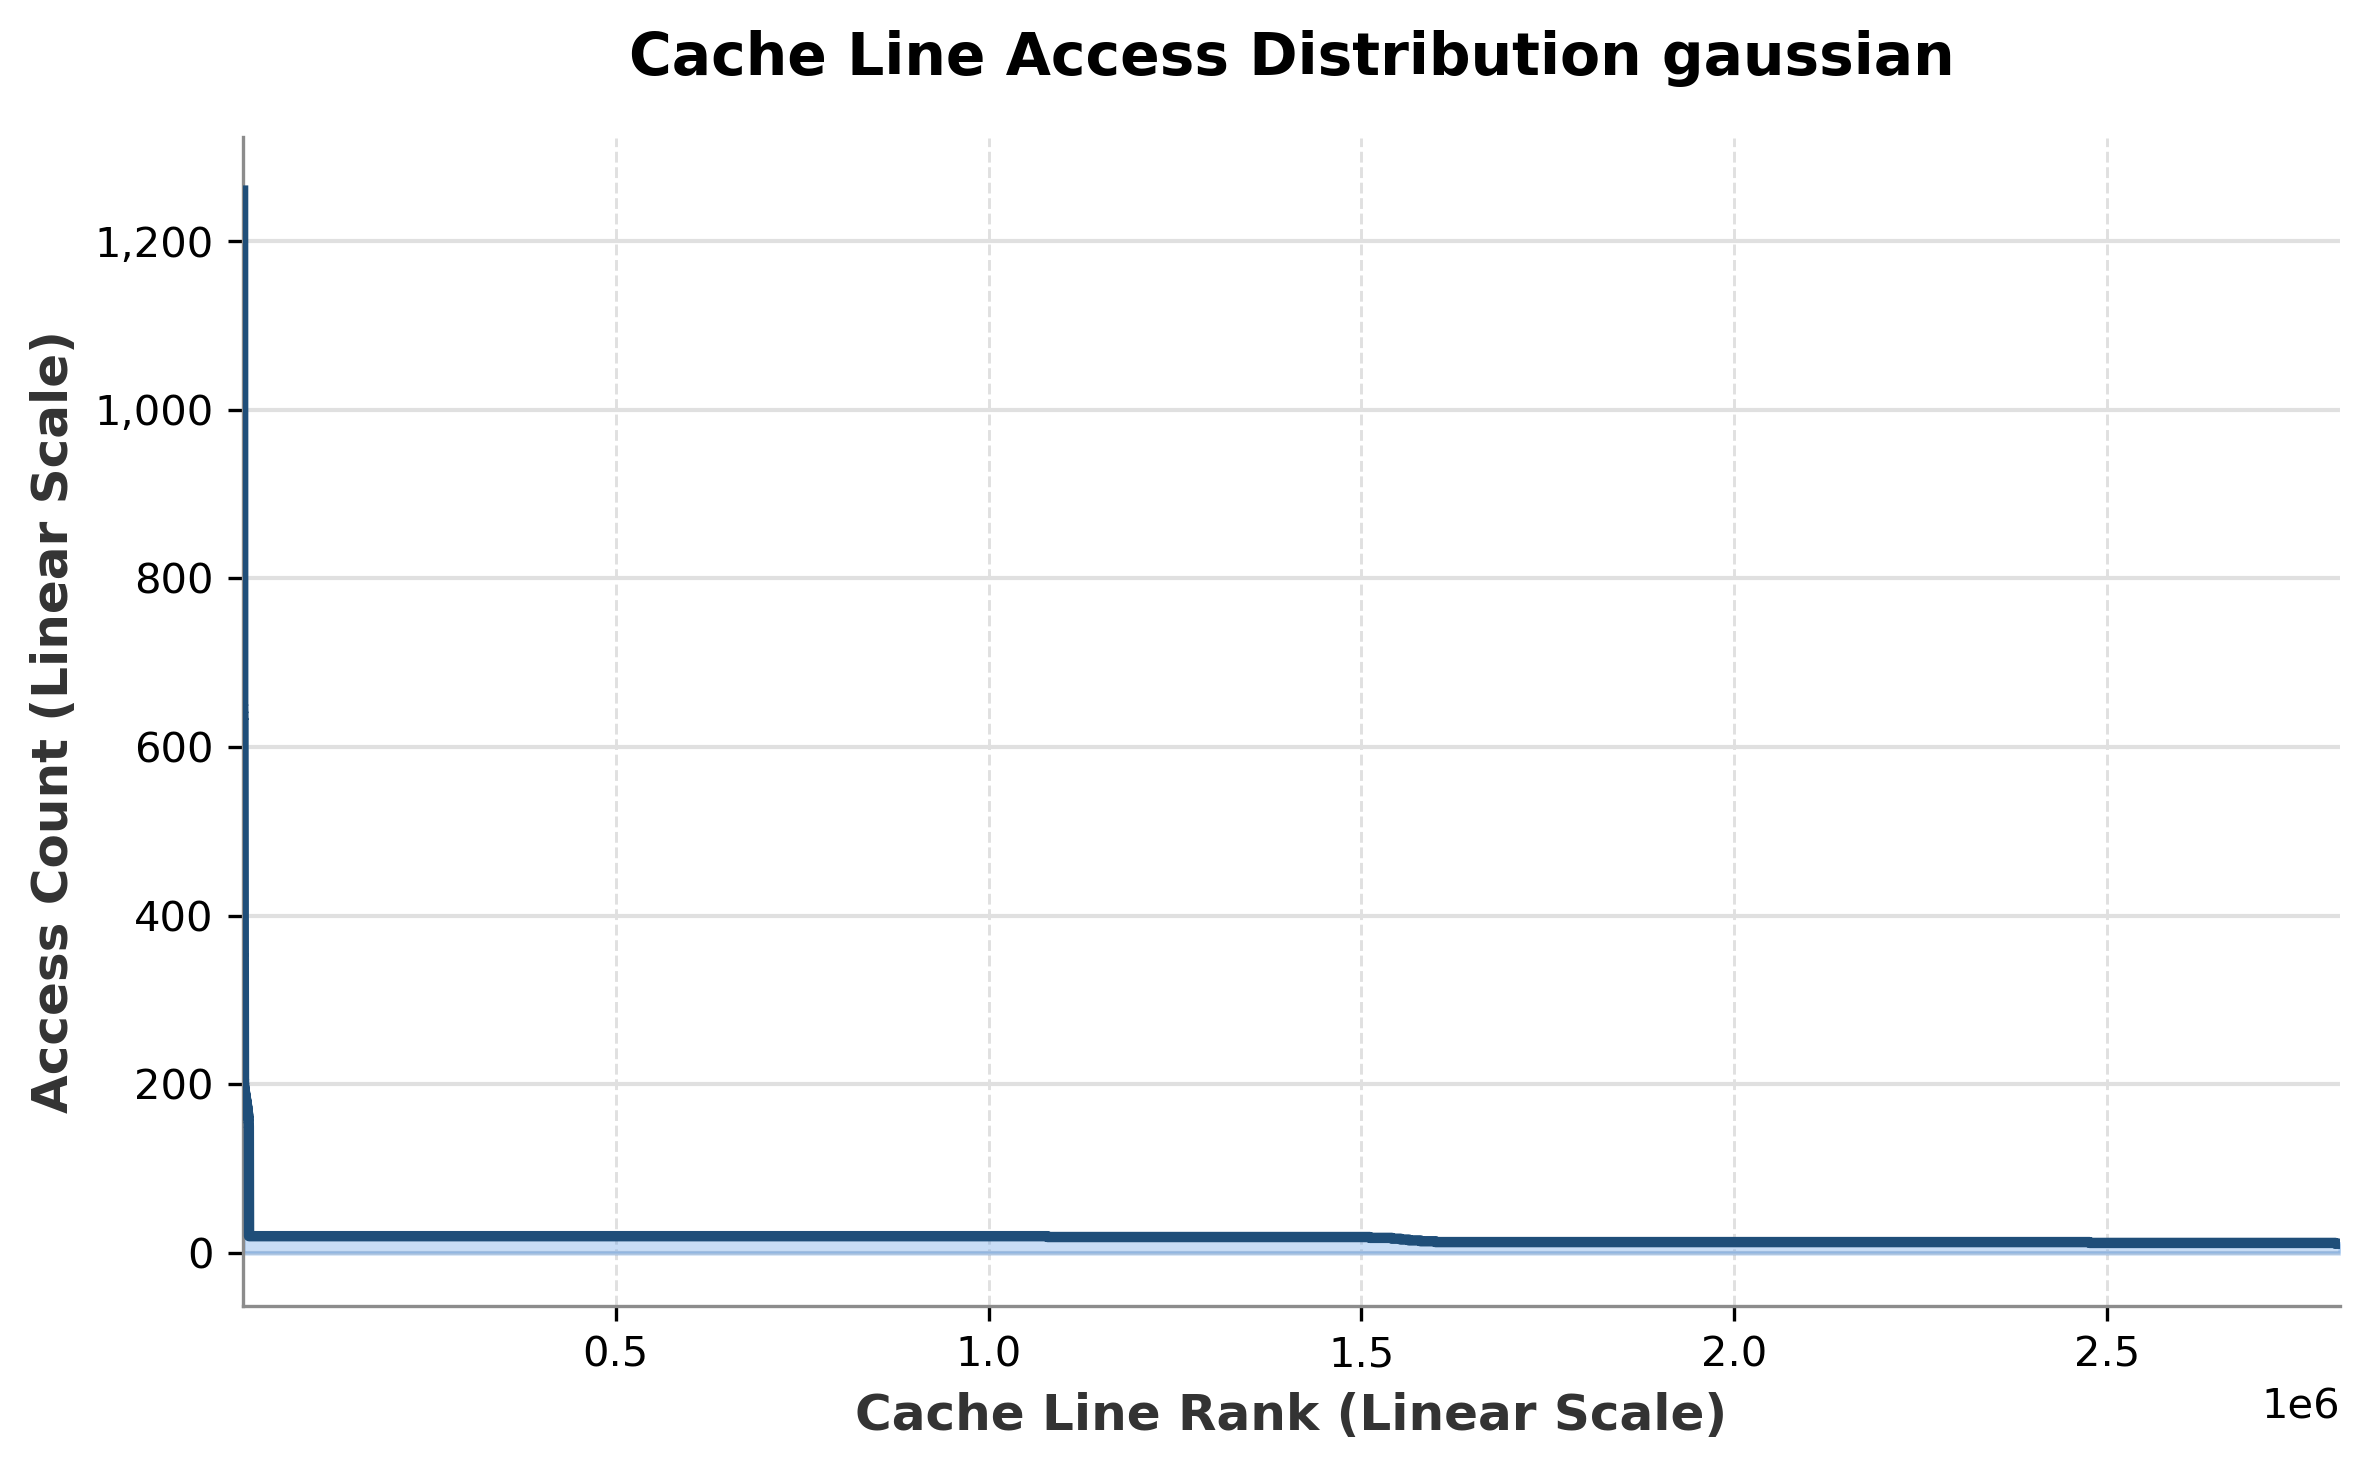

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/gaussian_addr_access_count_ratio.png


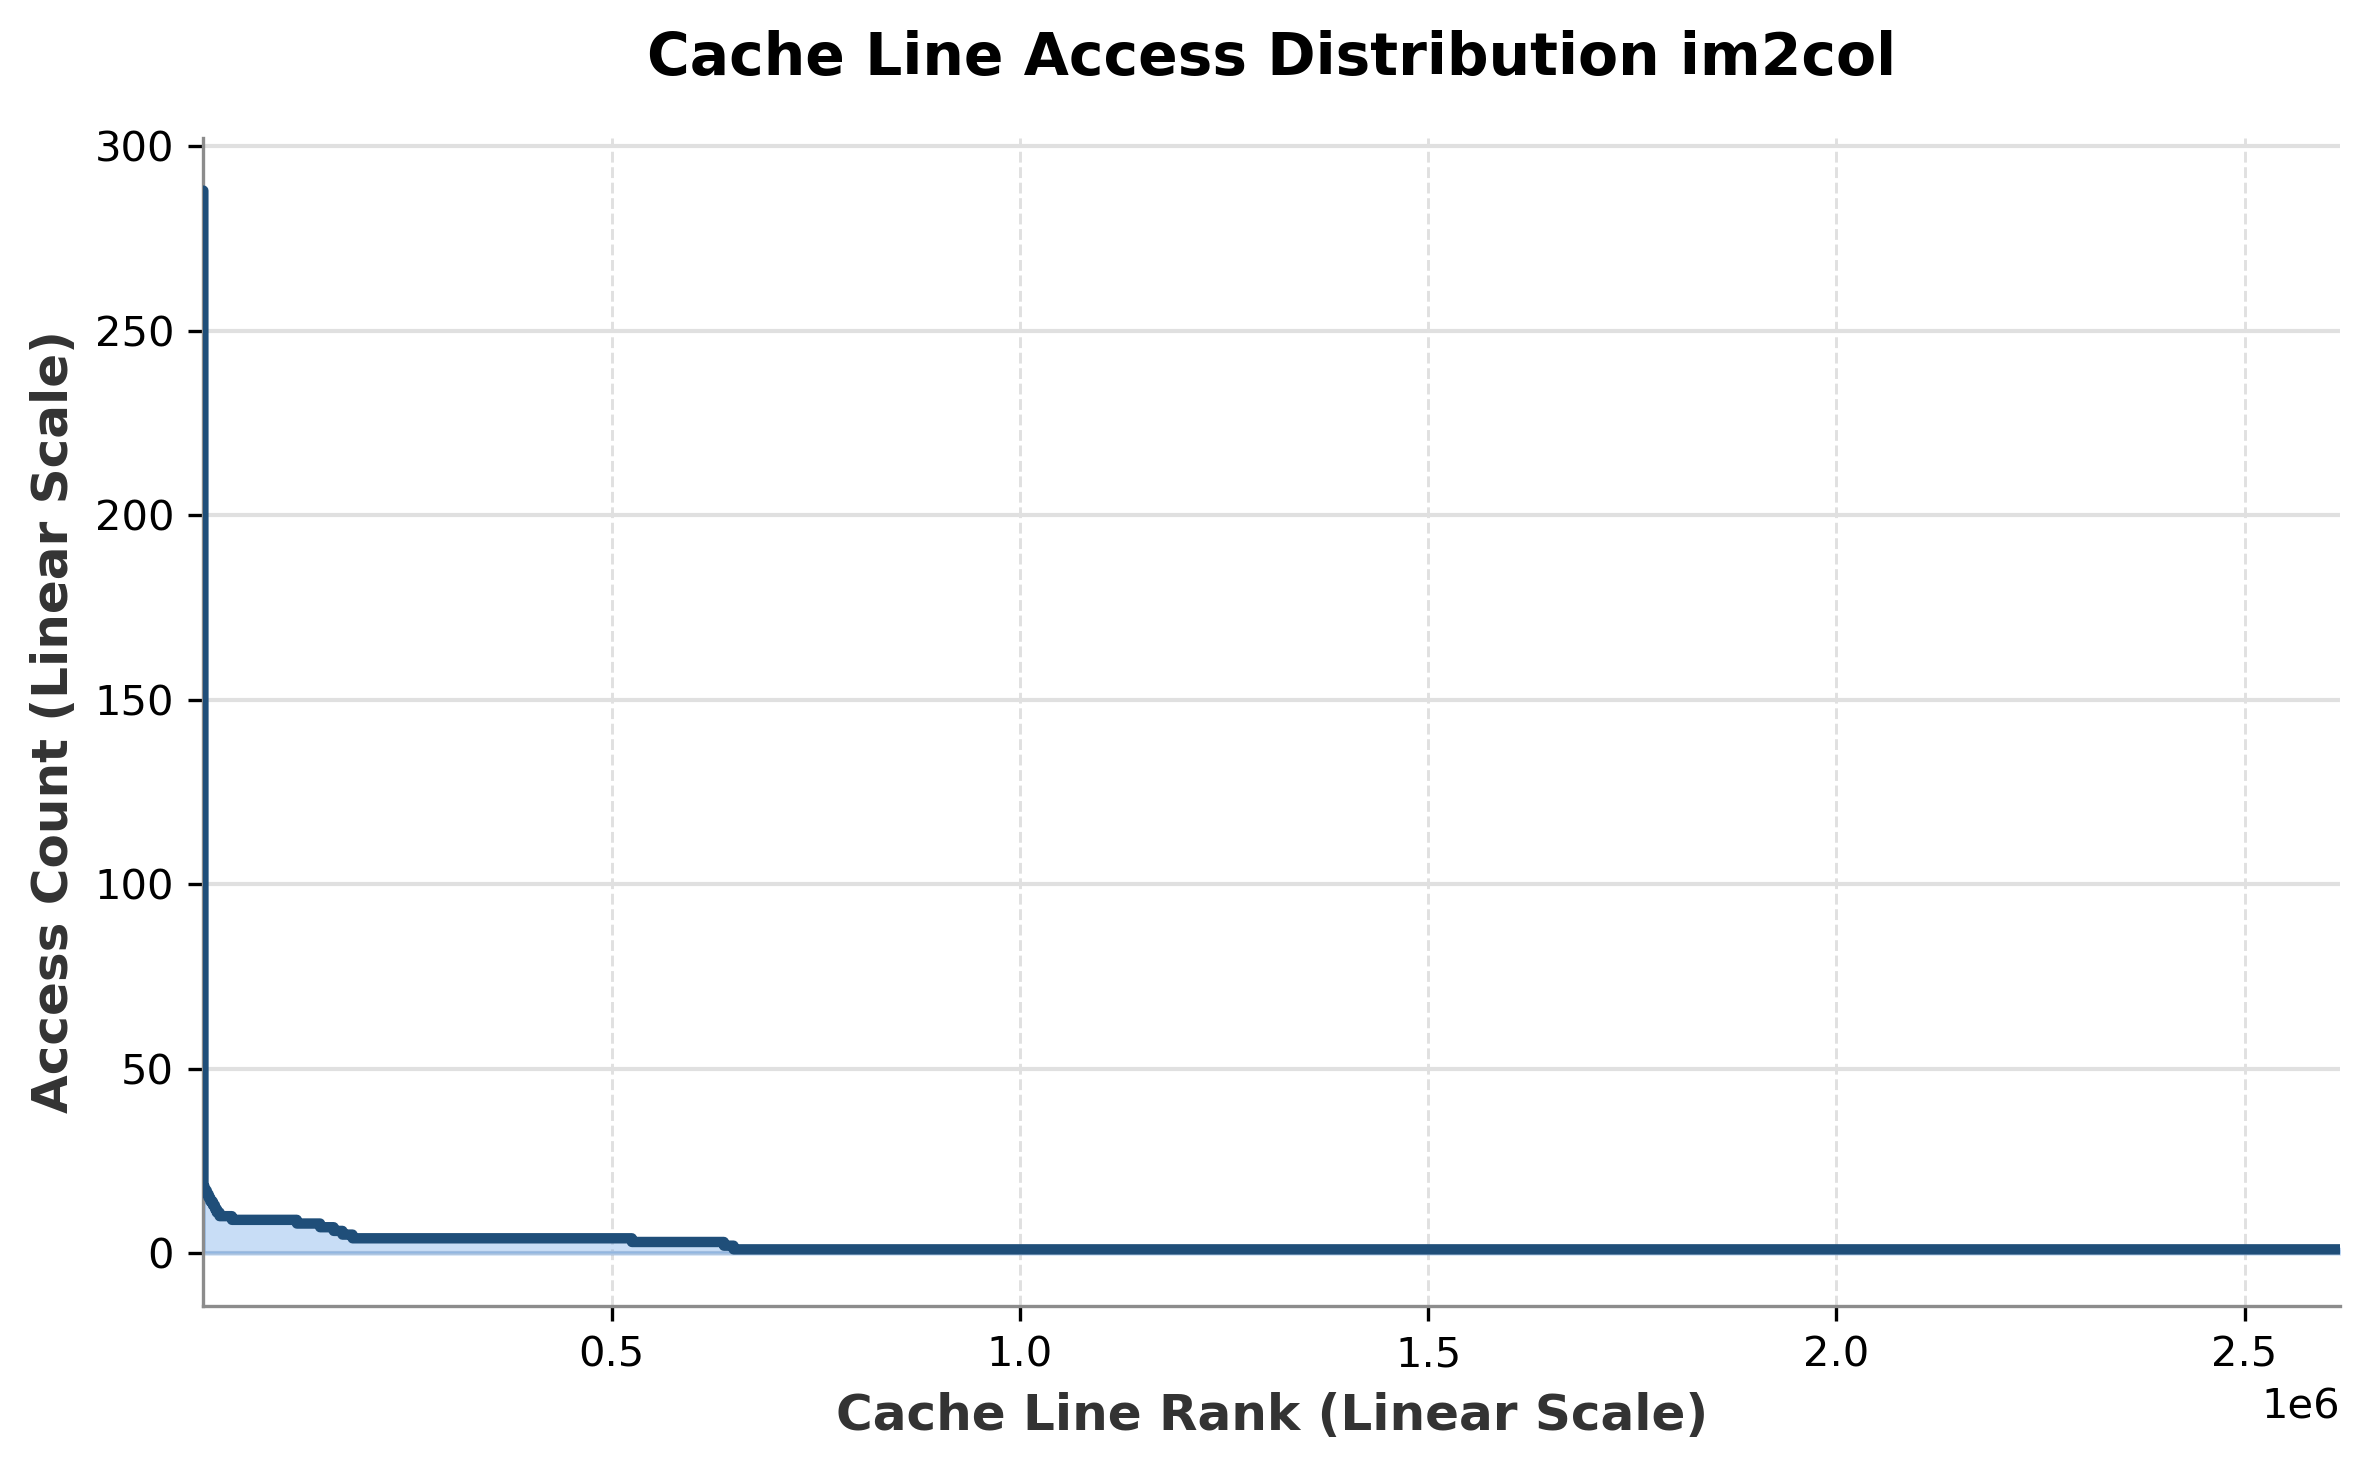

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/im2col_addr_access_count_ratio.png


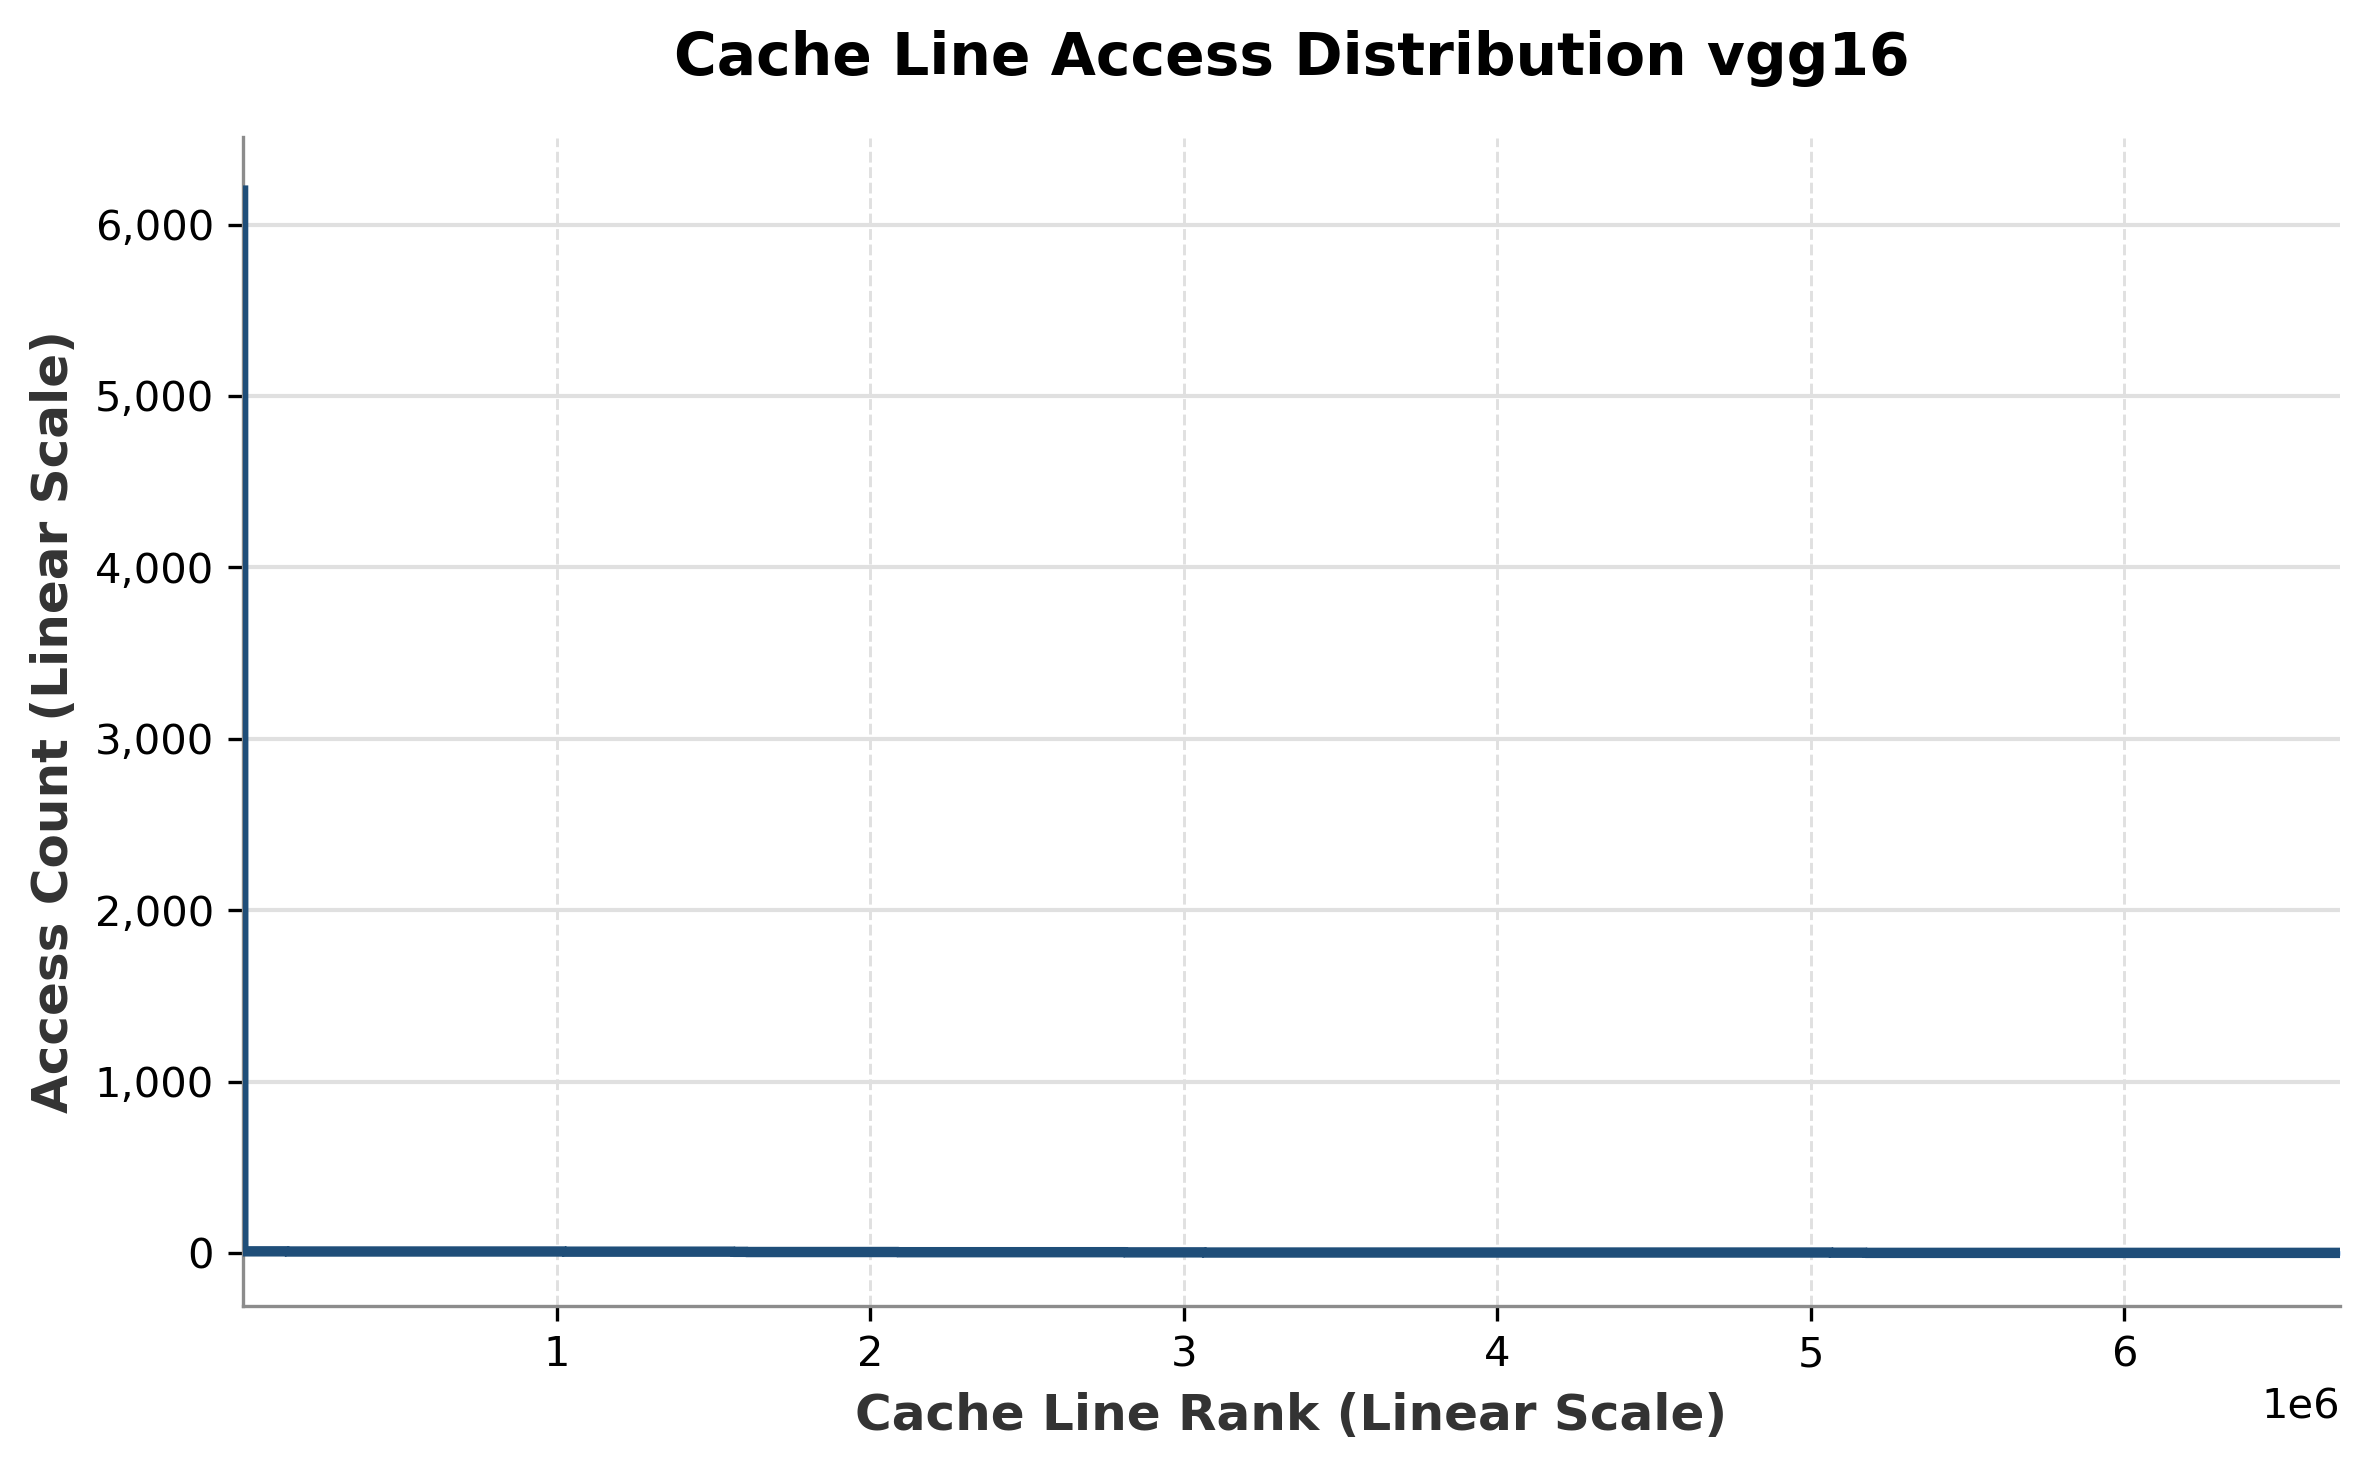

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/vgg16_addr_access_count_ratio.png


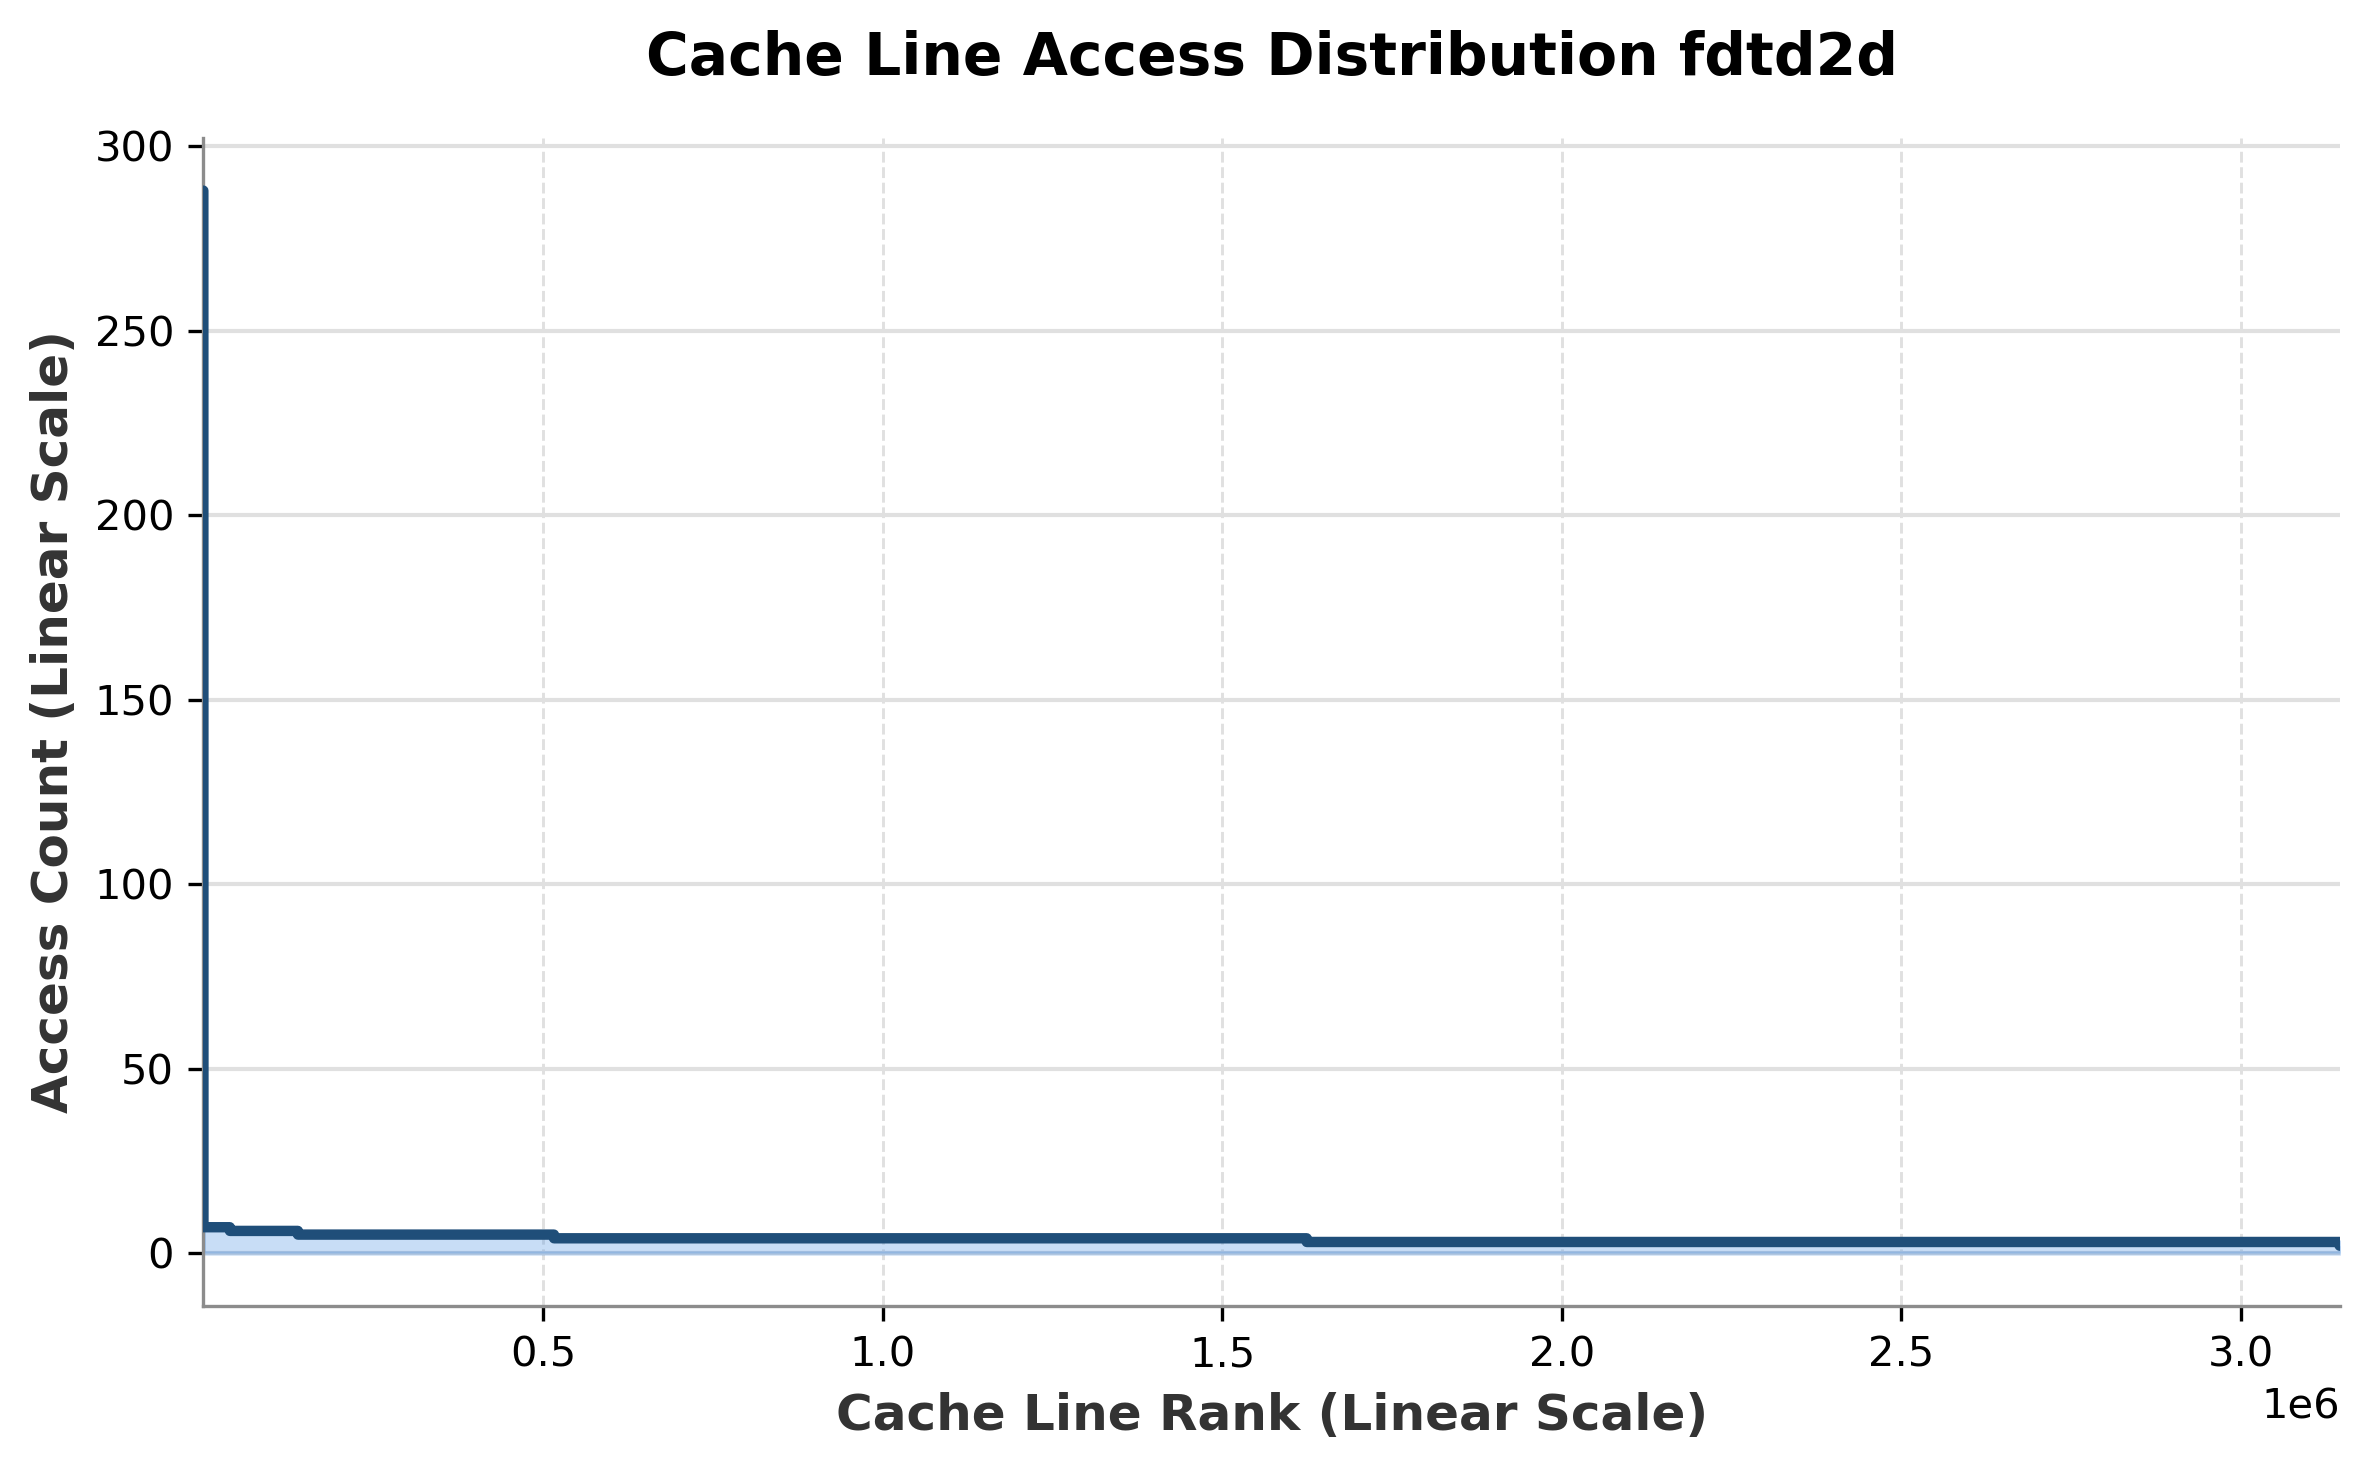

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/fdtd2d_addr_access_count_ratio.png


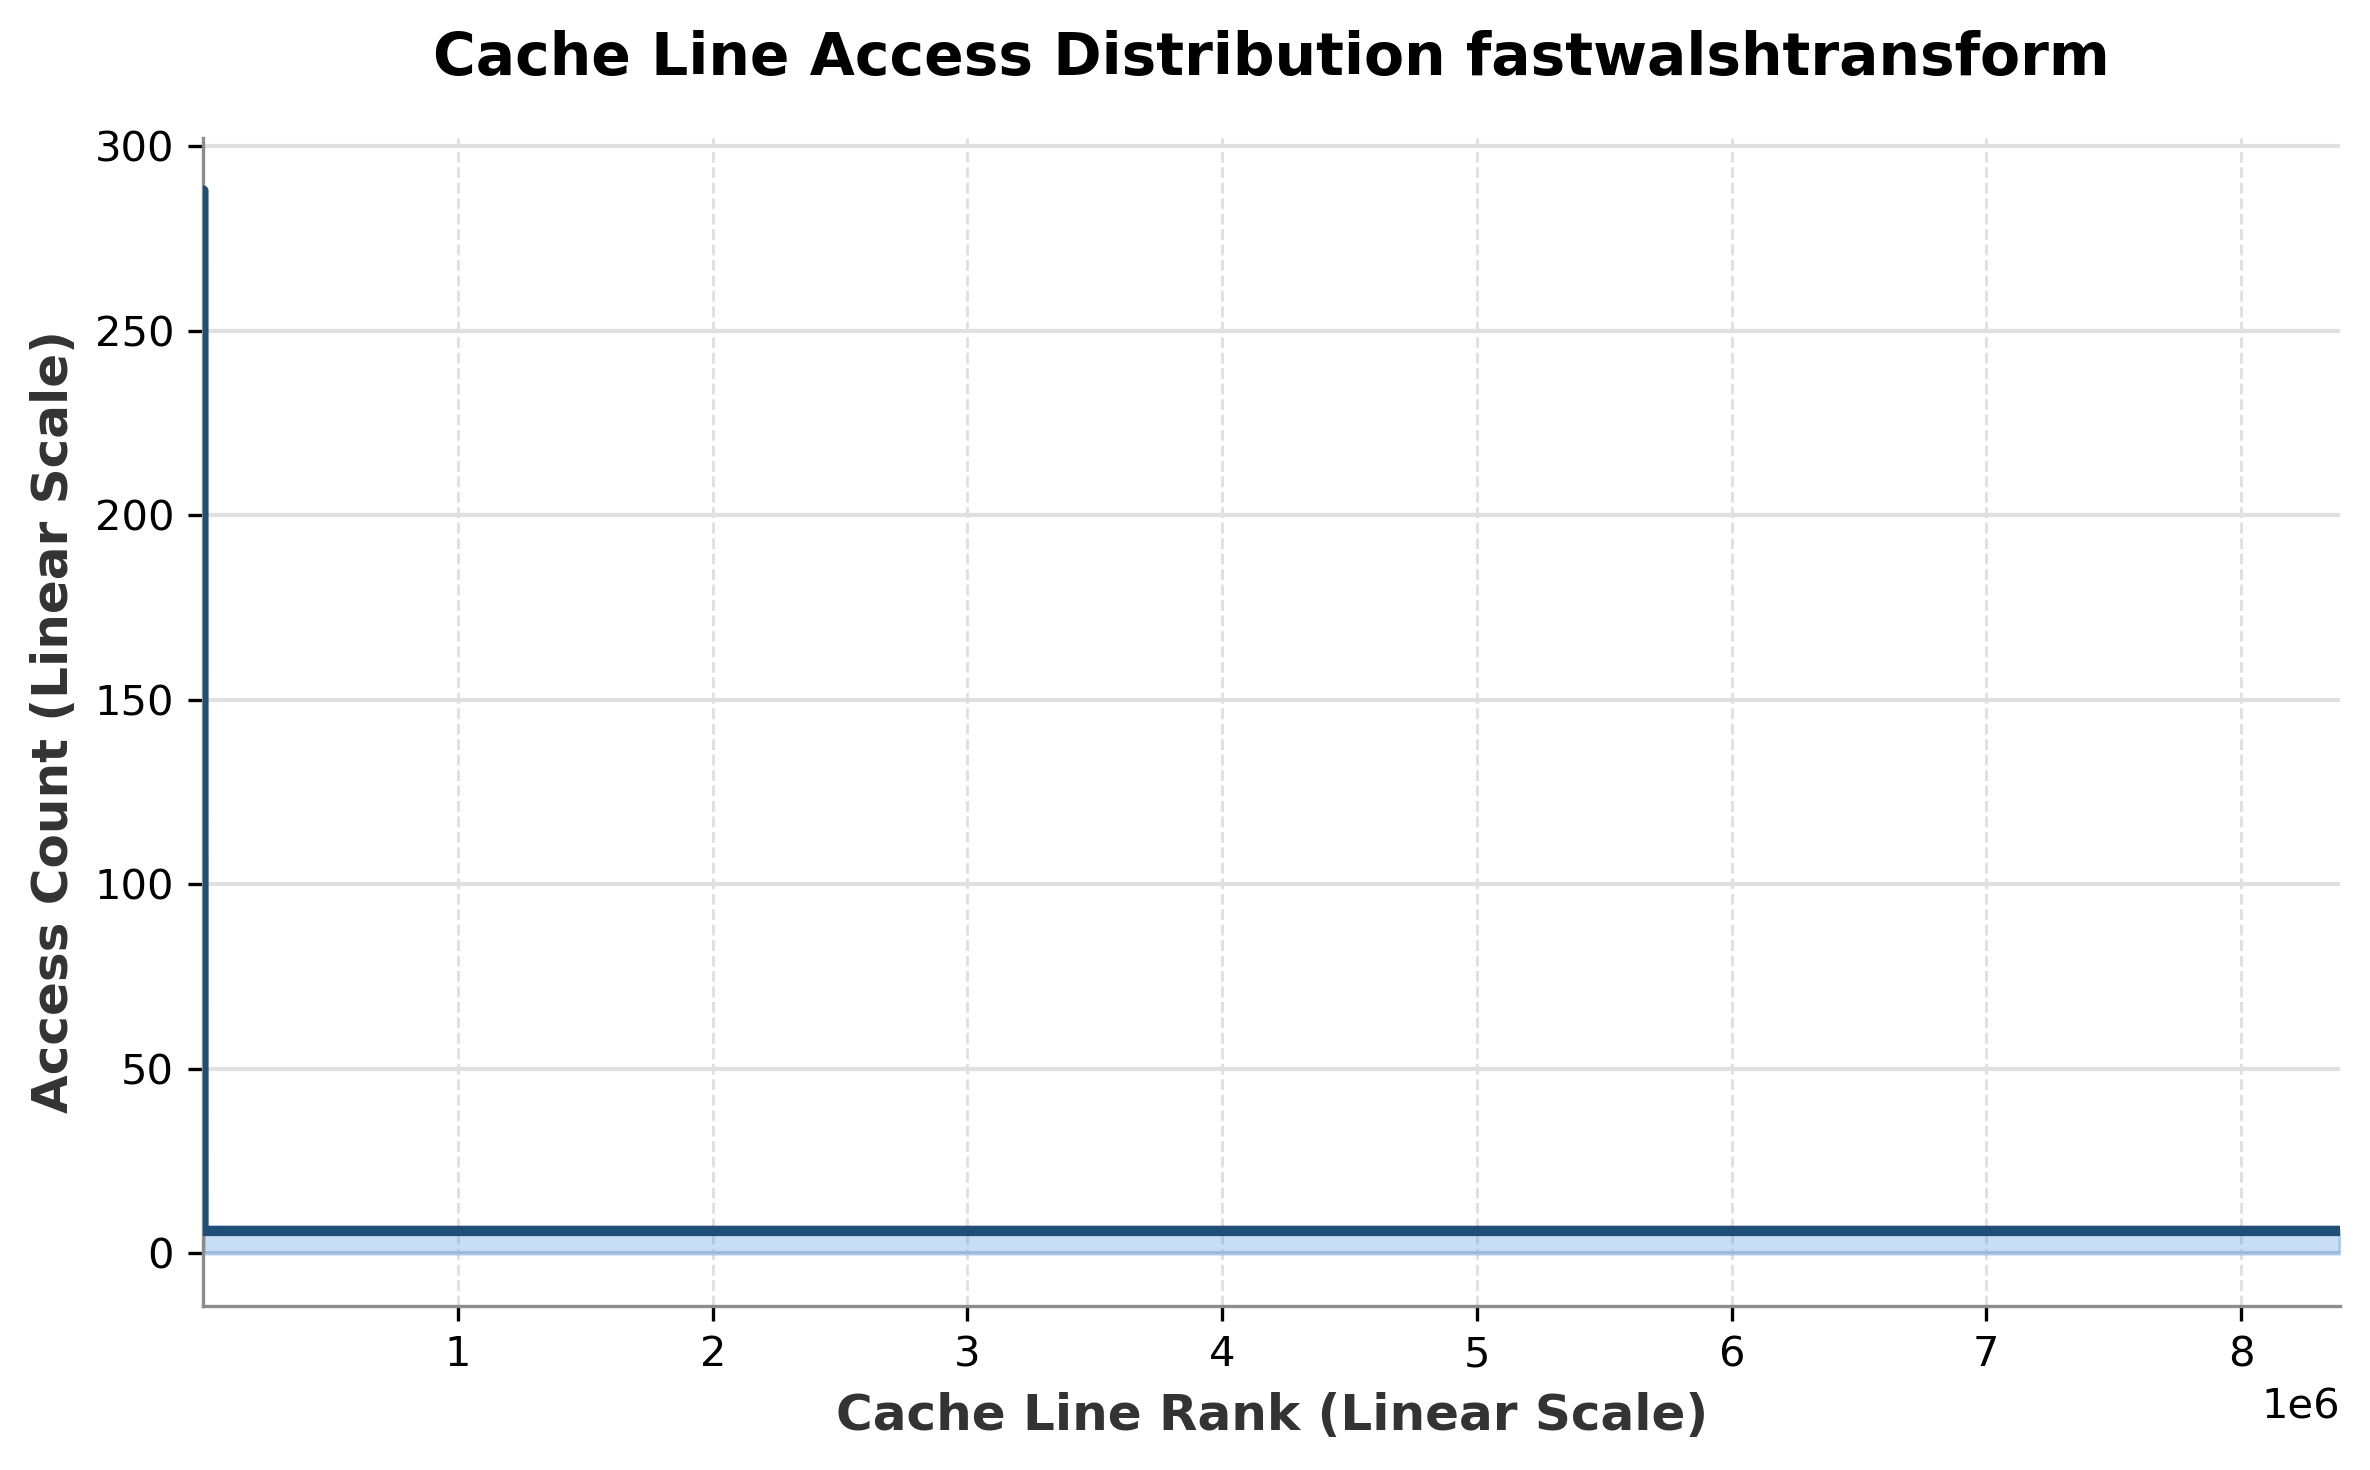

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/fastwalshtransform_addr_access_count_ratio.png


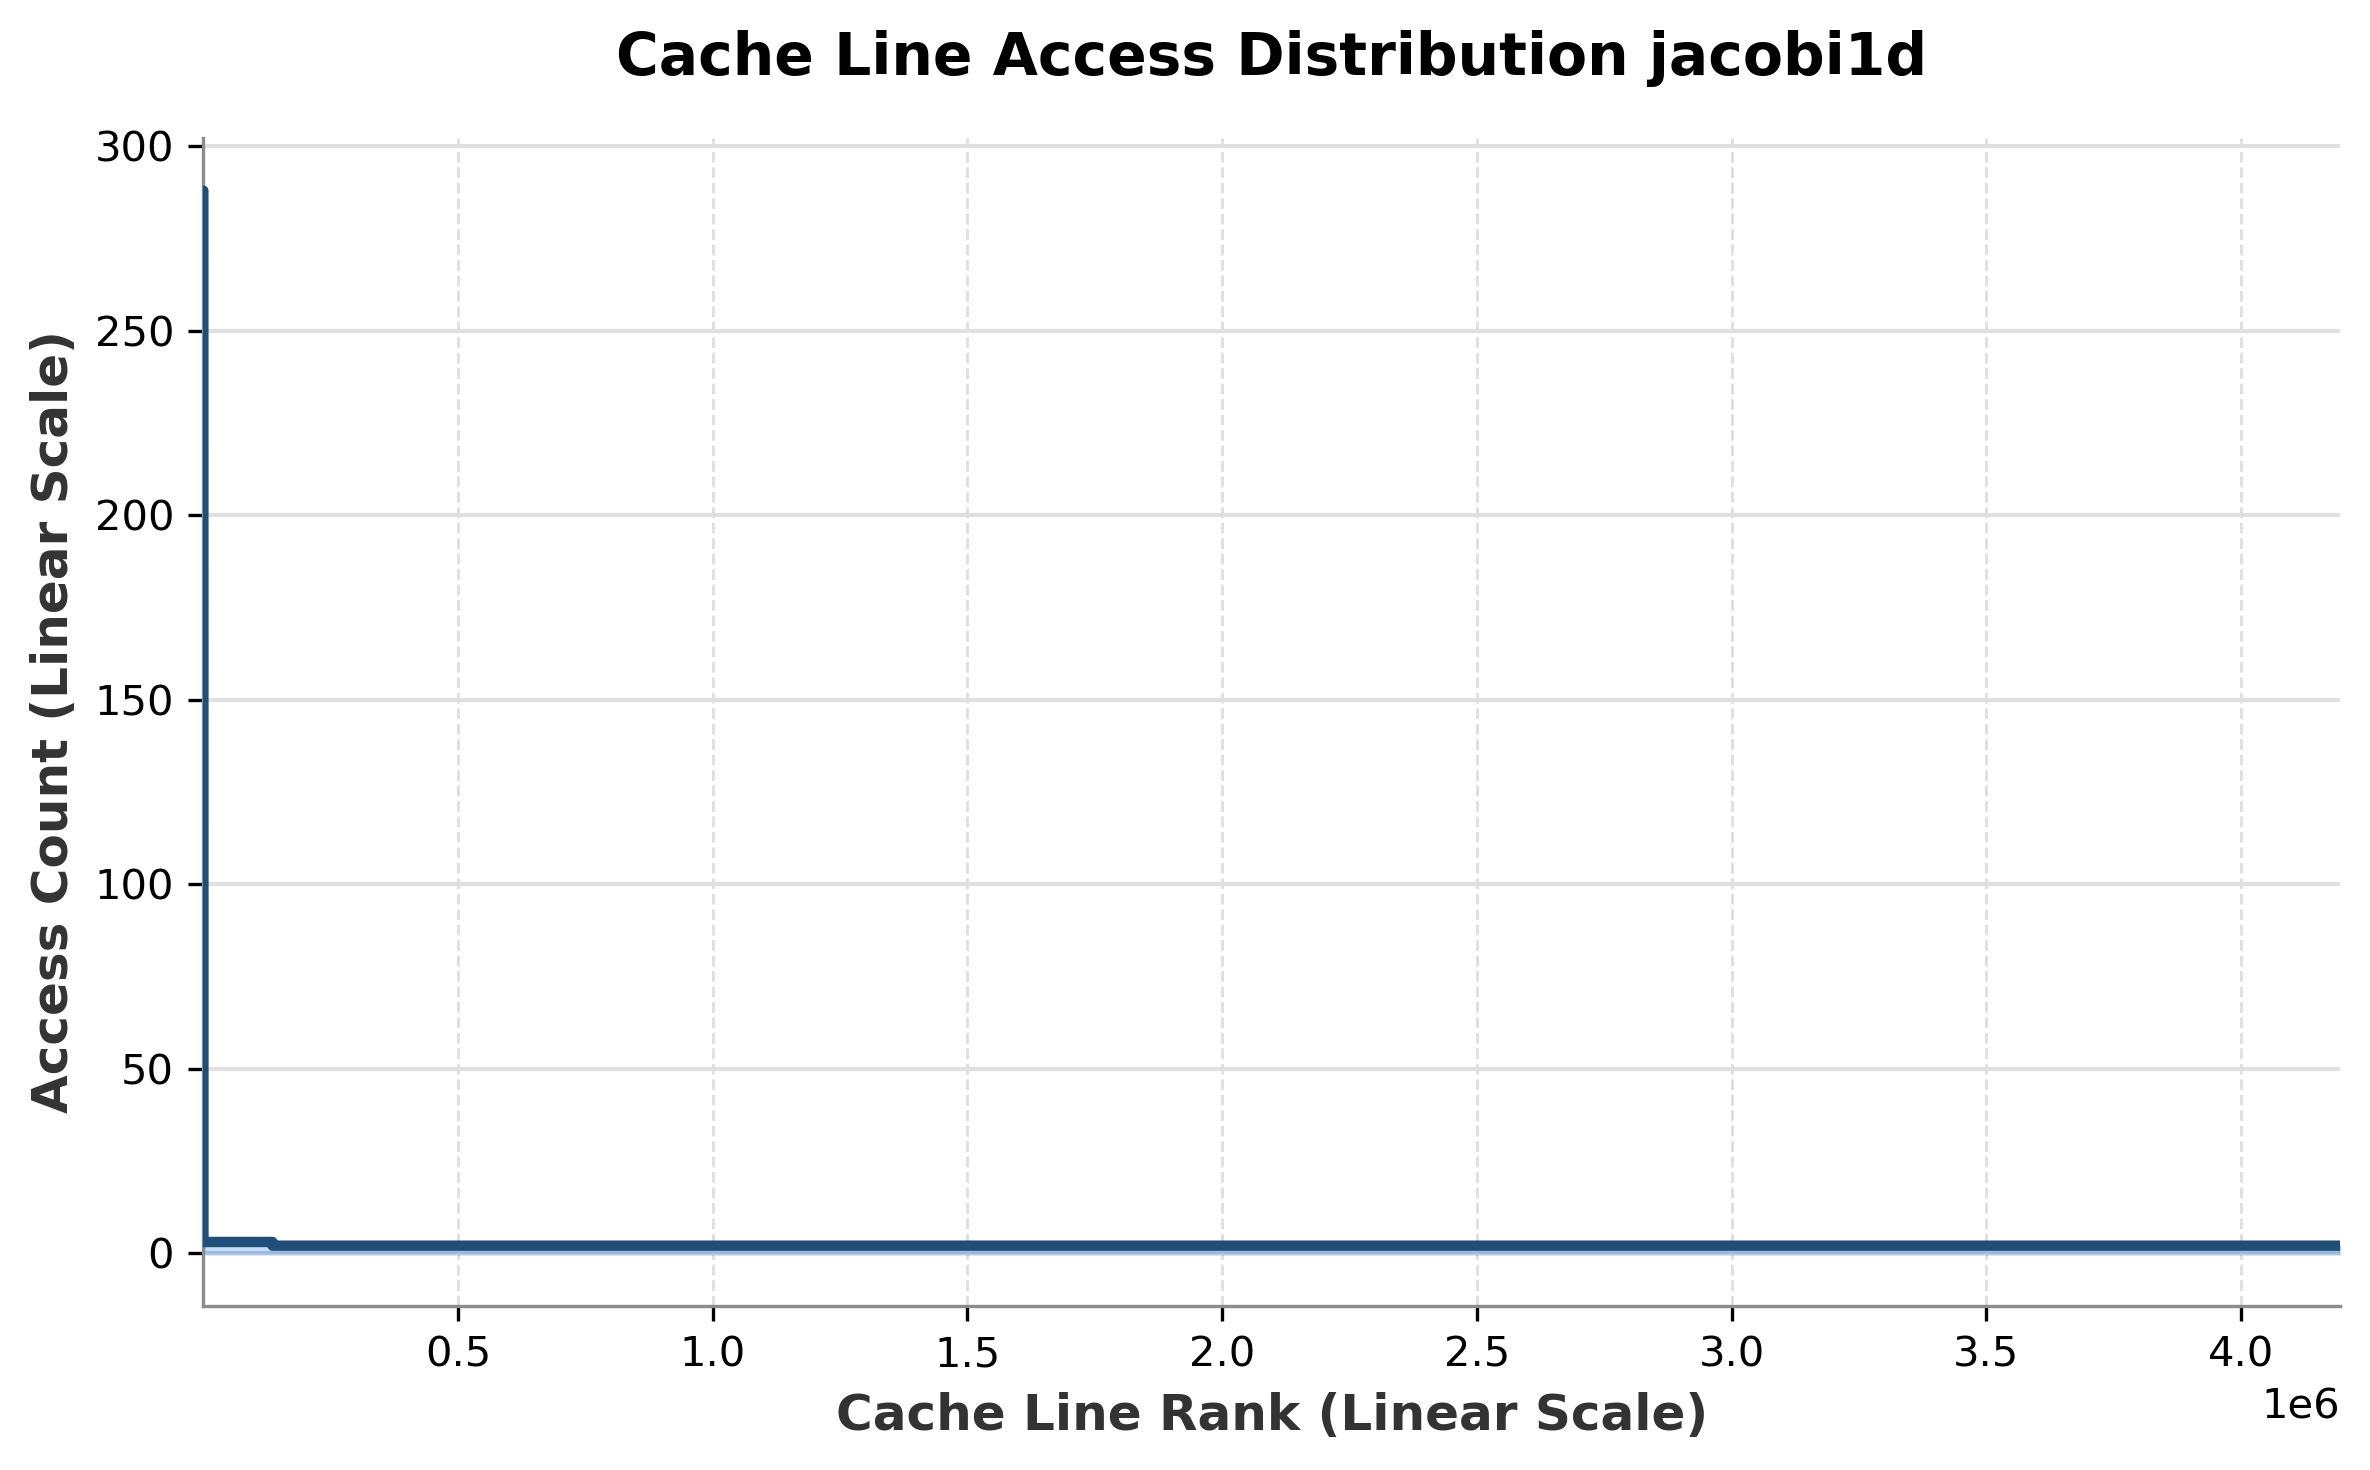

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/jacobi1d_addr_access_count_ratio.png


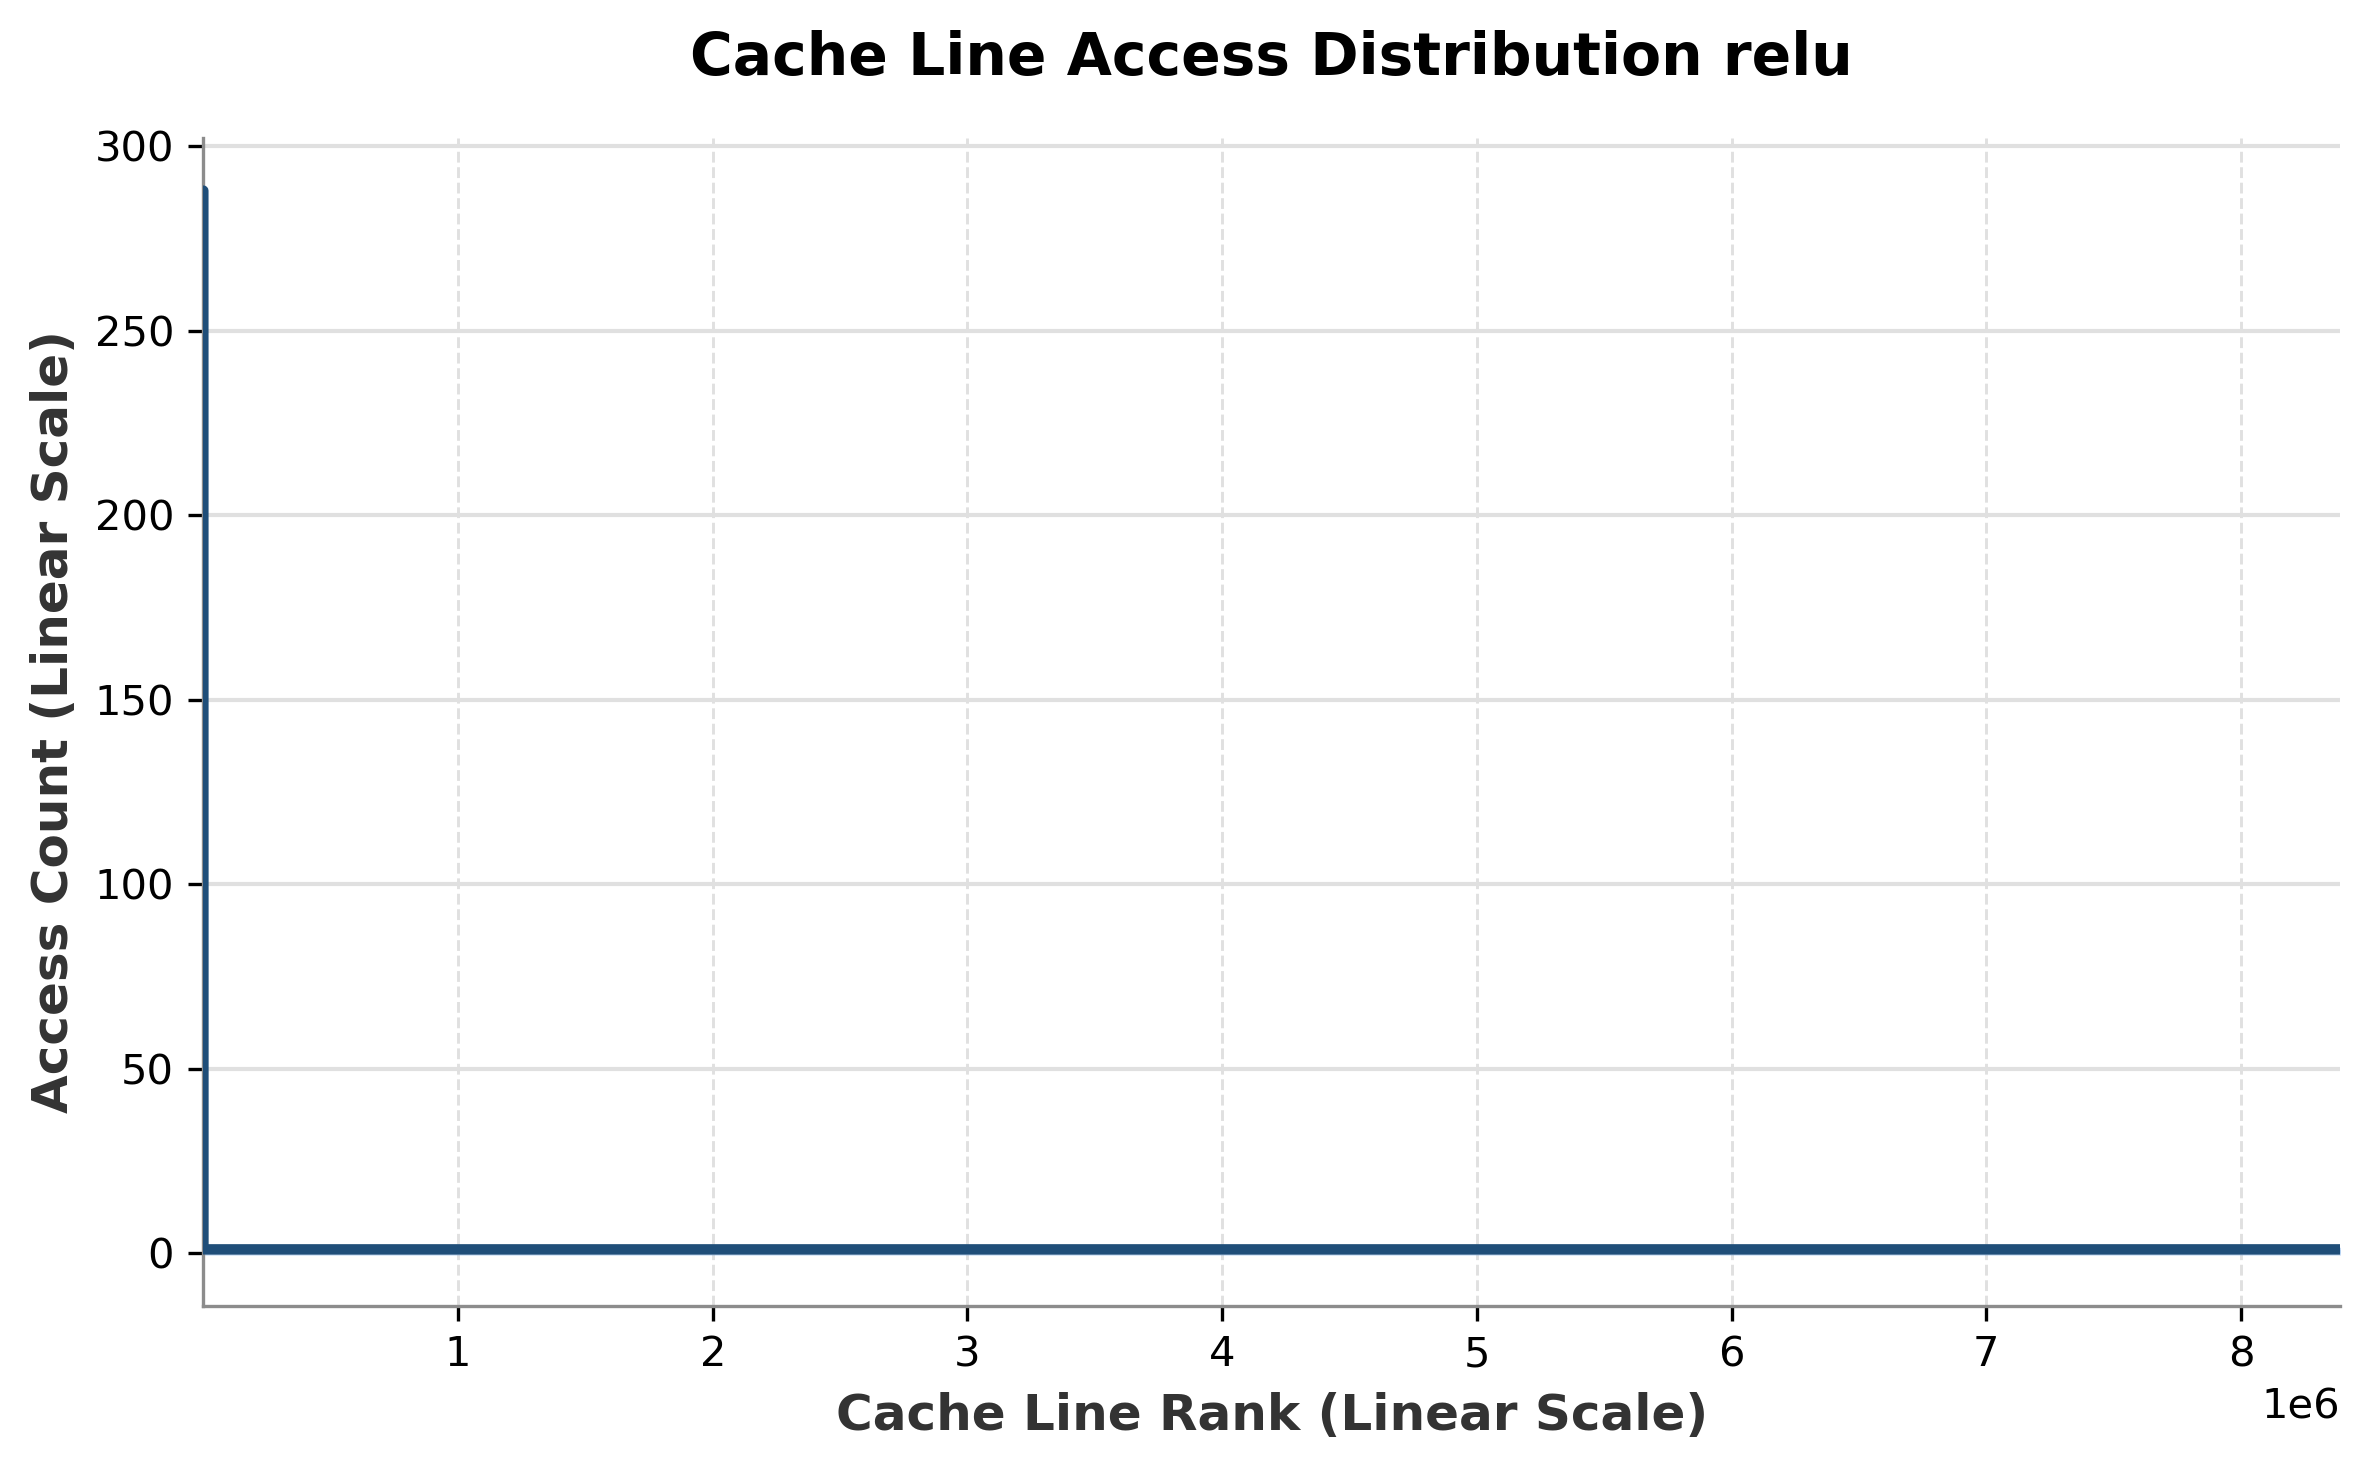

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/relu_addr_access_count_ratio.png


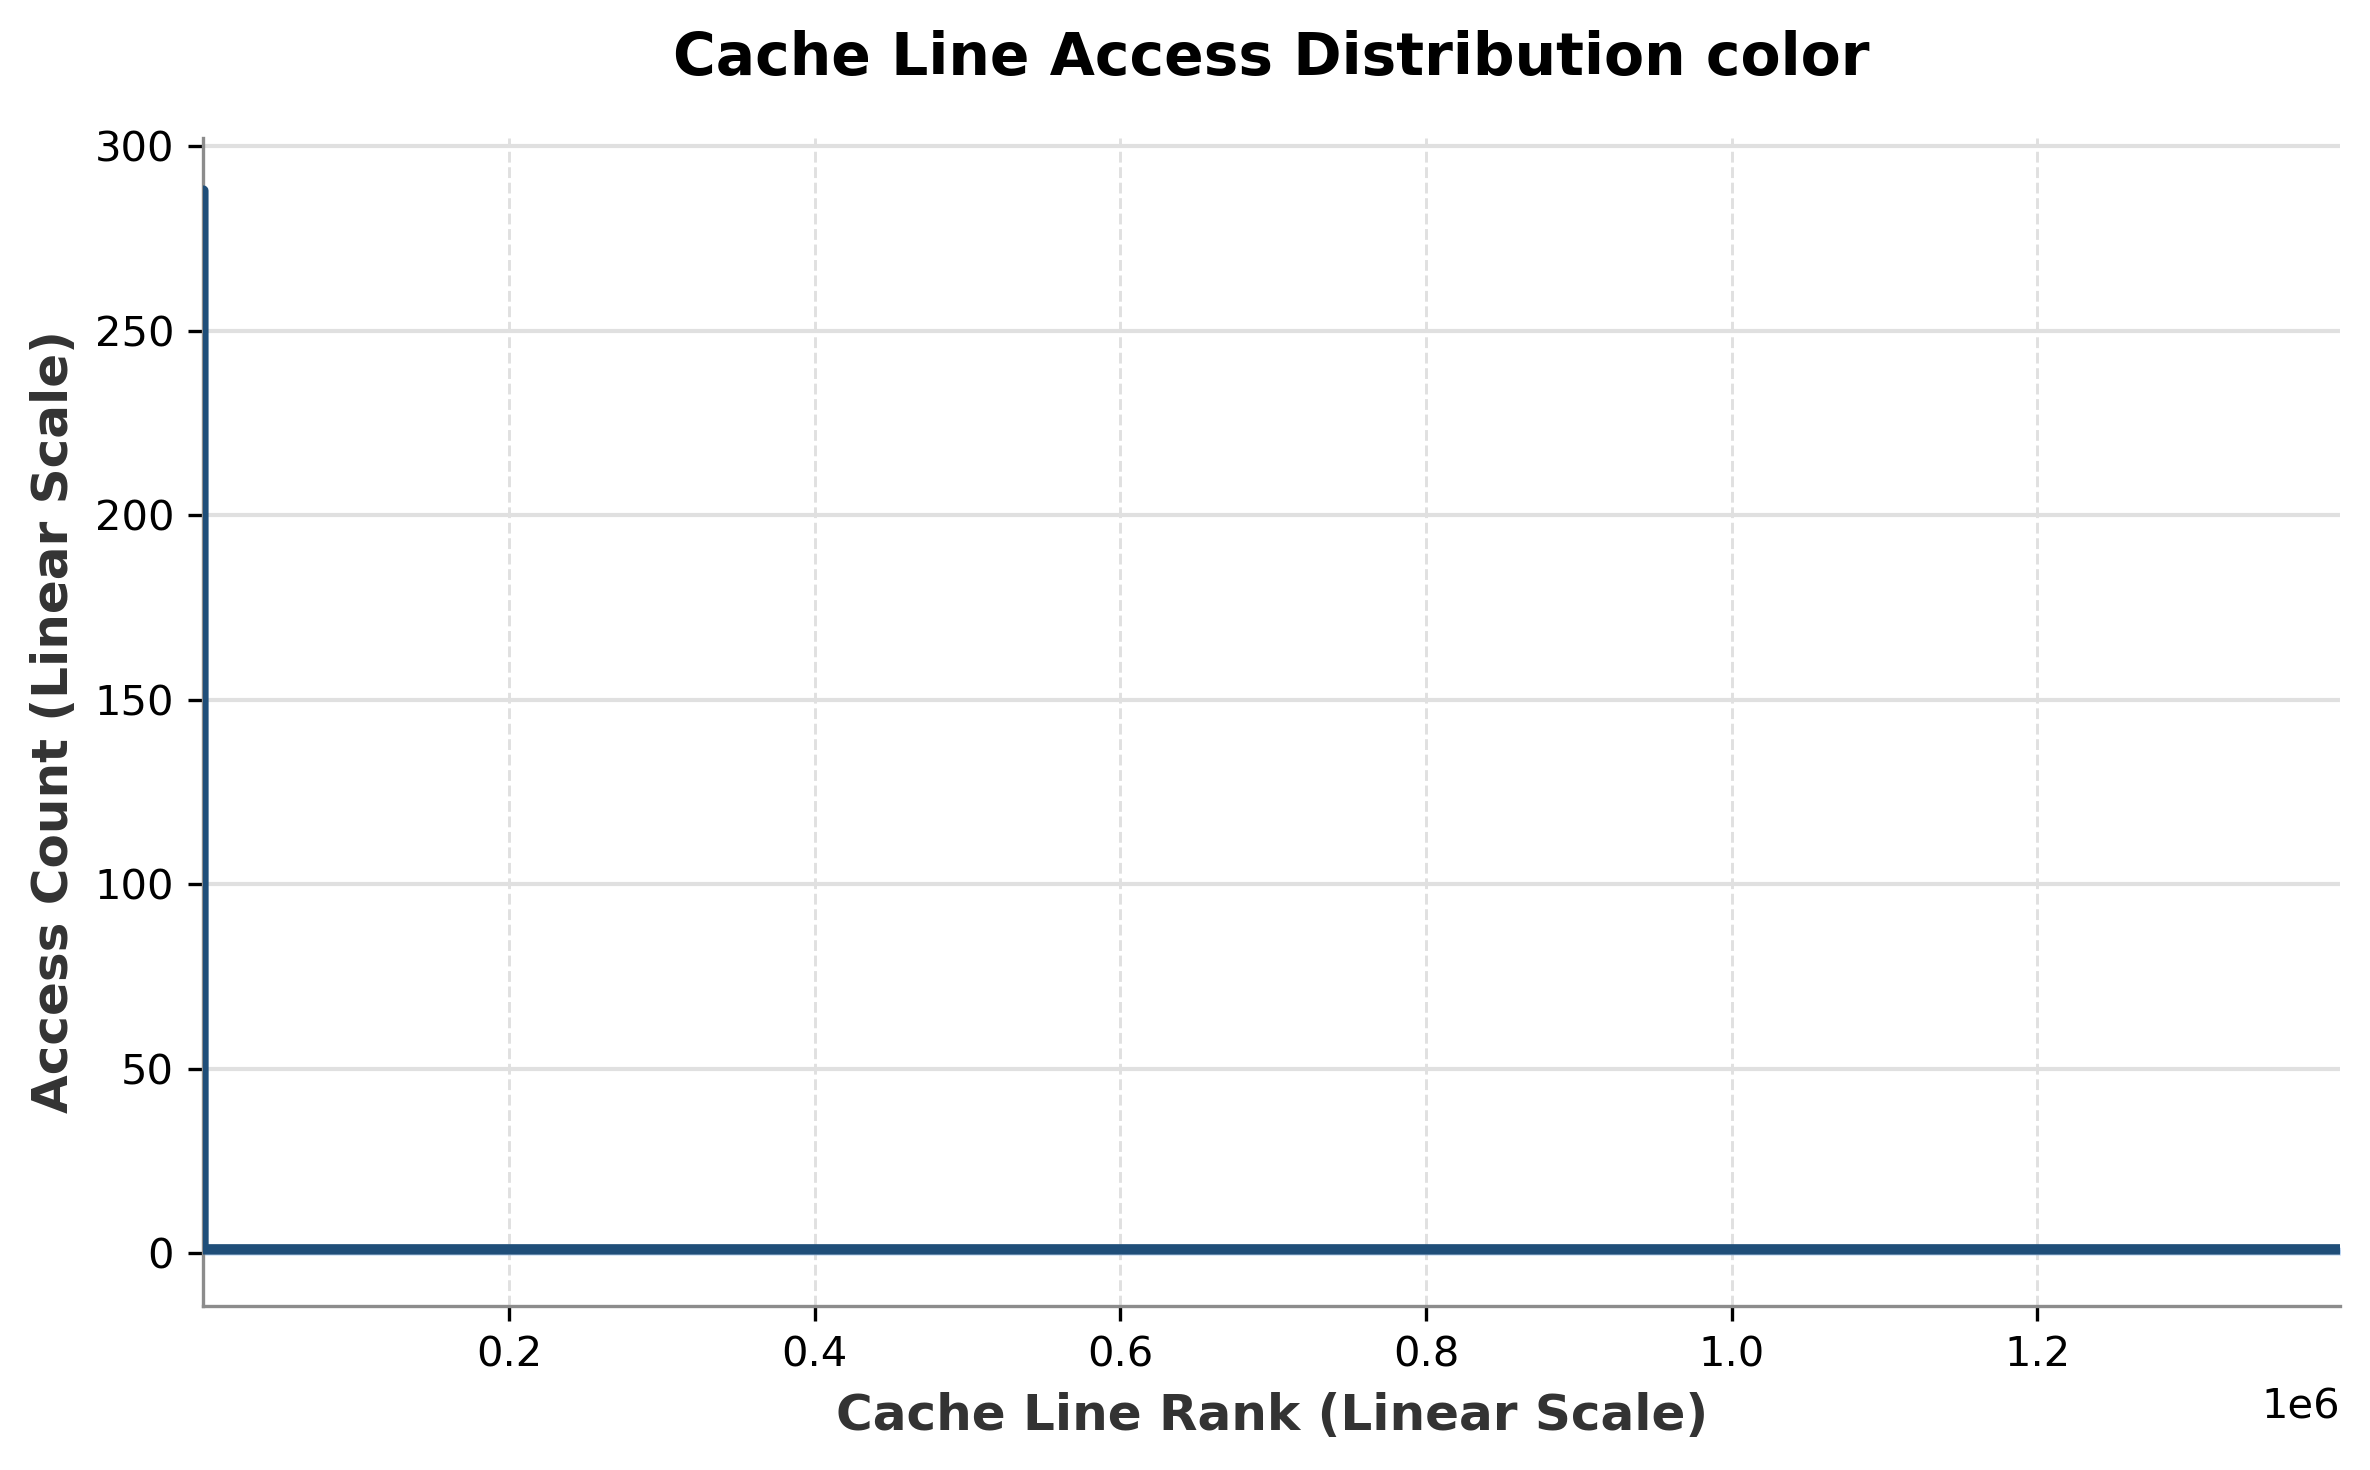

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/color_addr_access_count_ratio.png


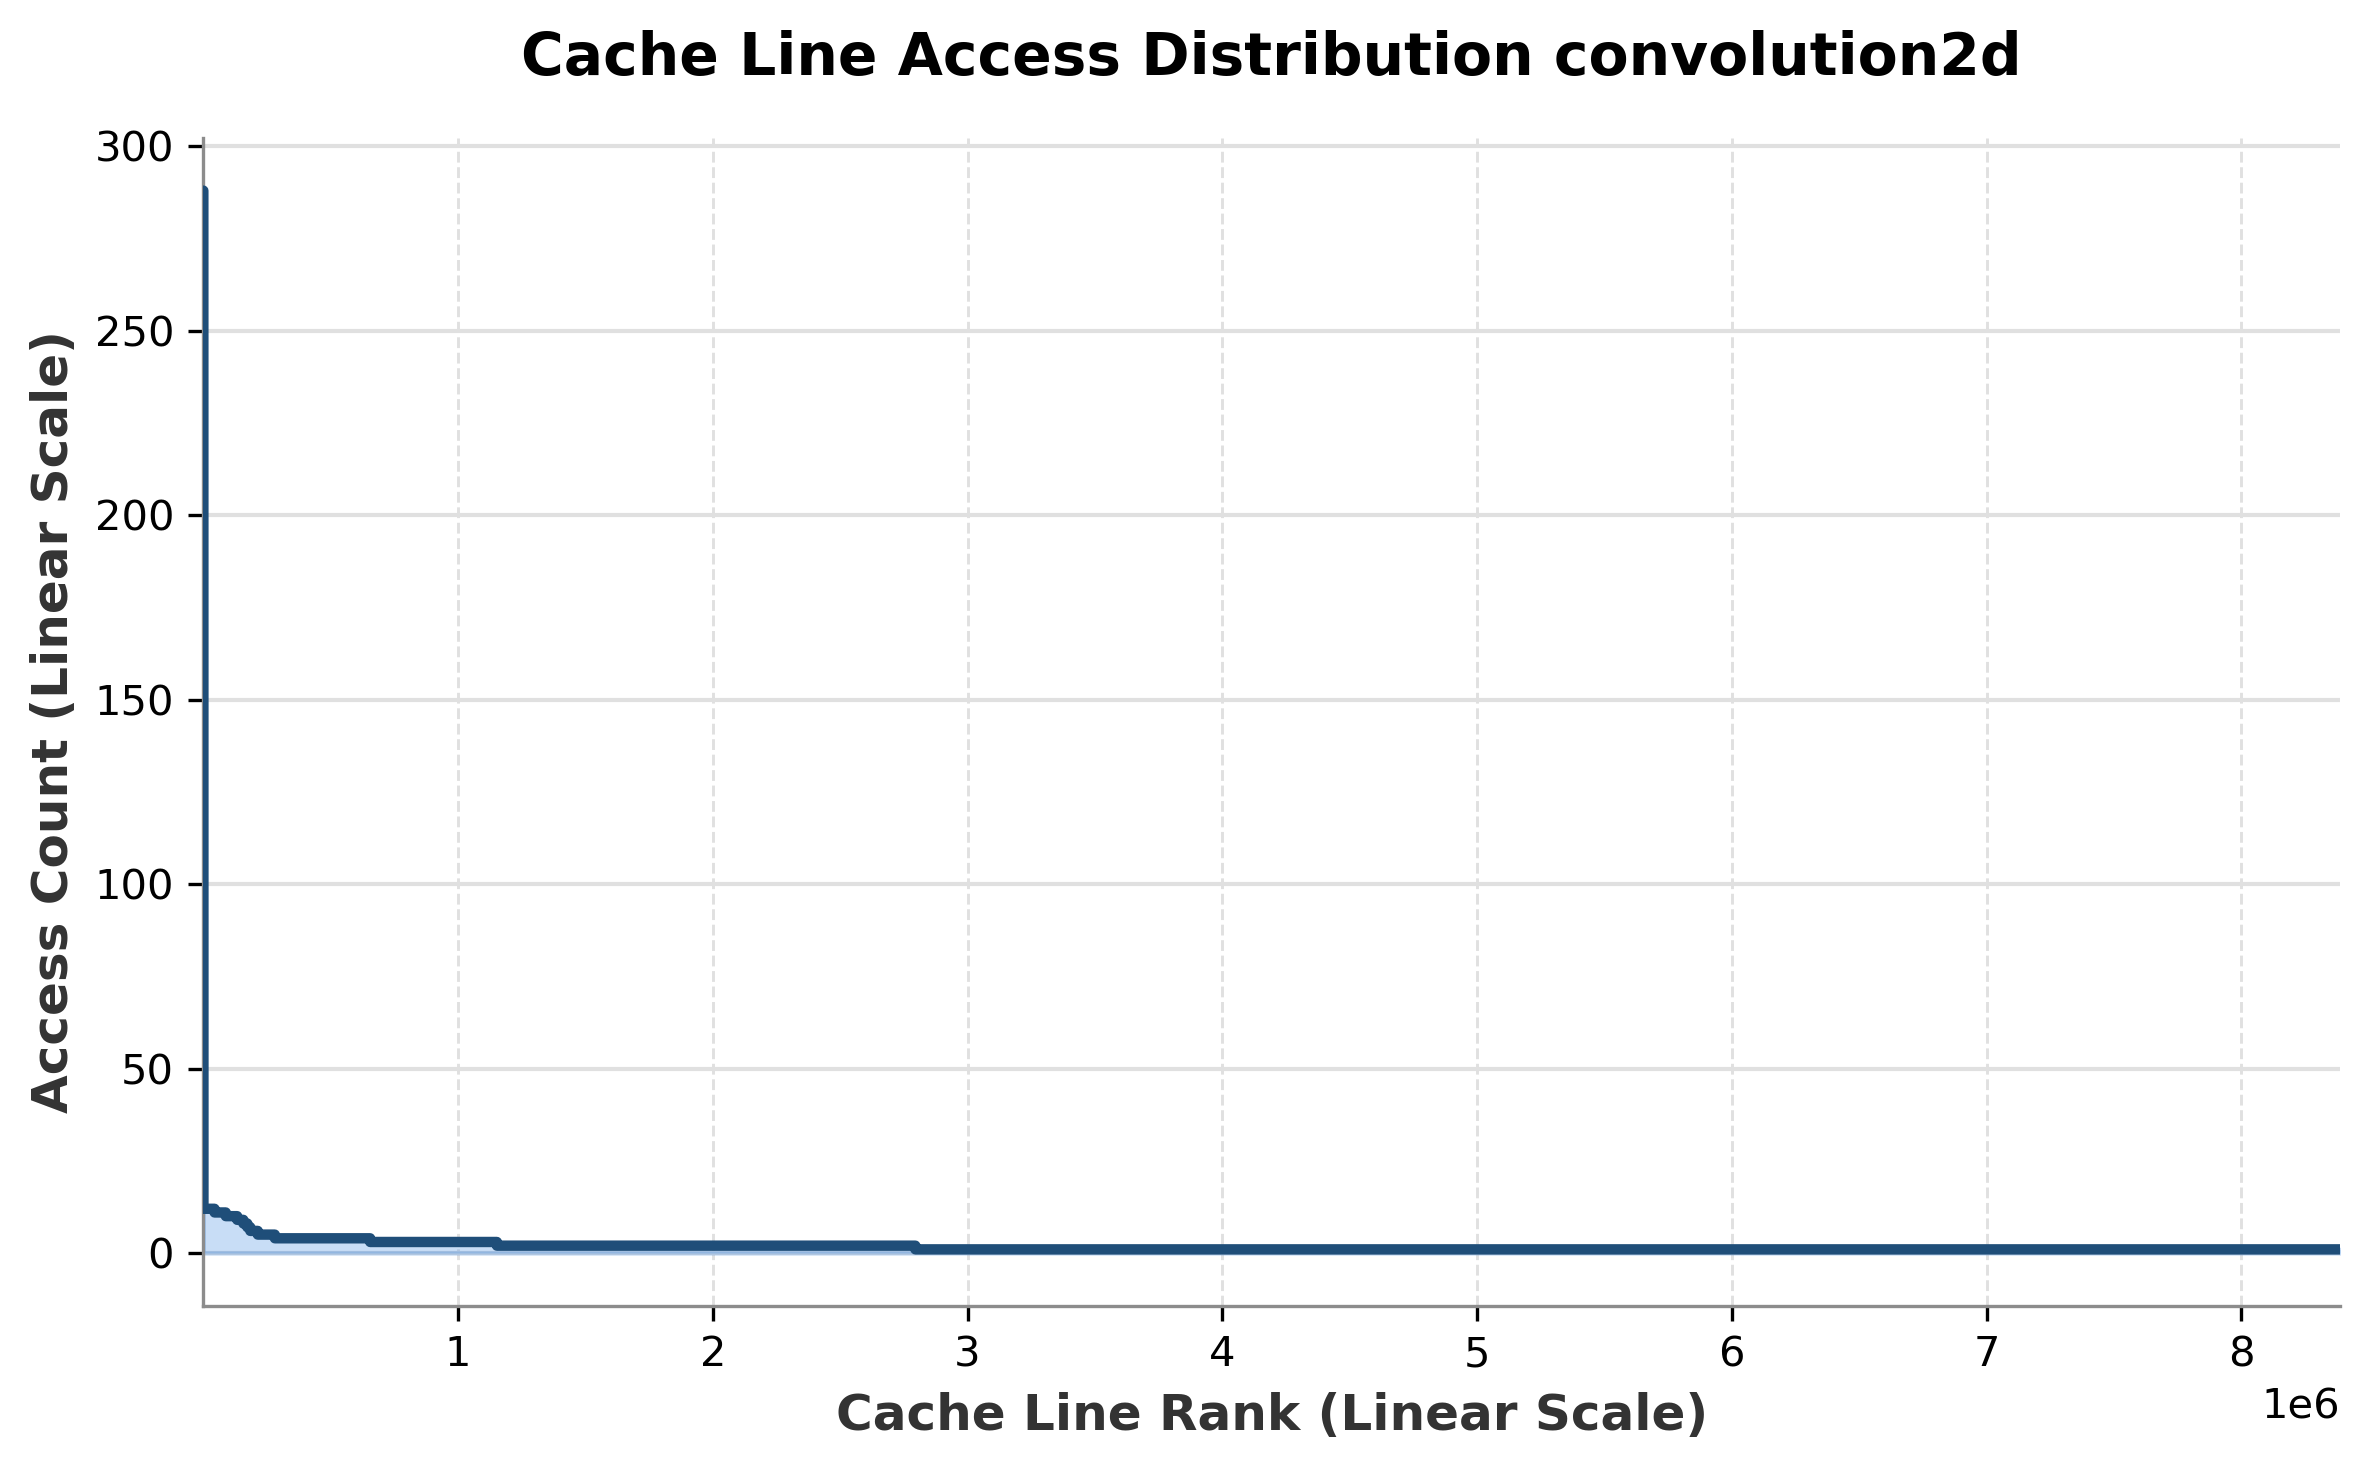

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/convolution2d_addr_access_count_ratio.png


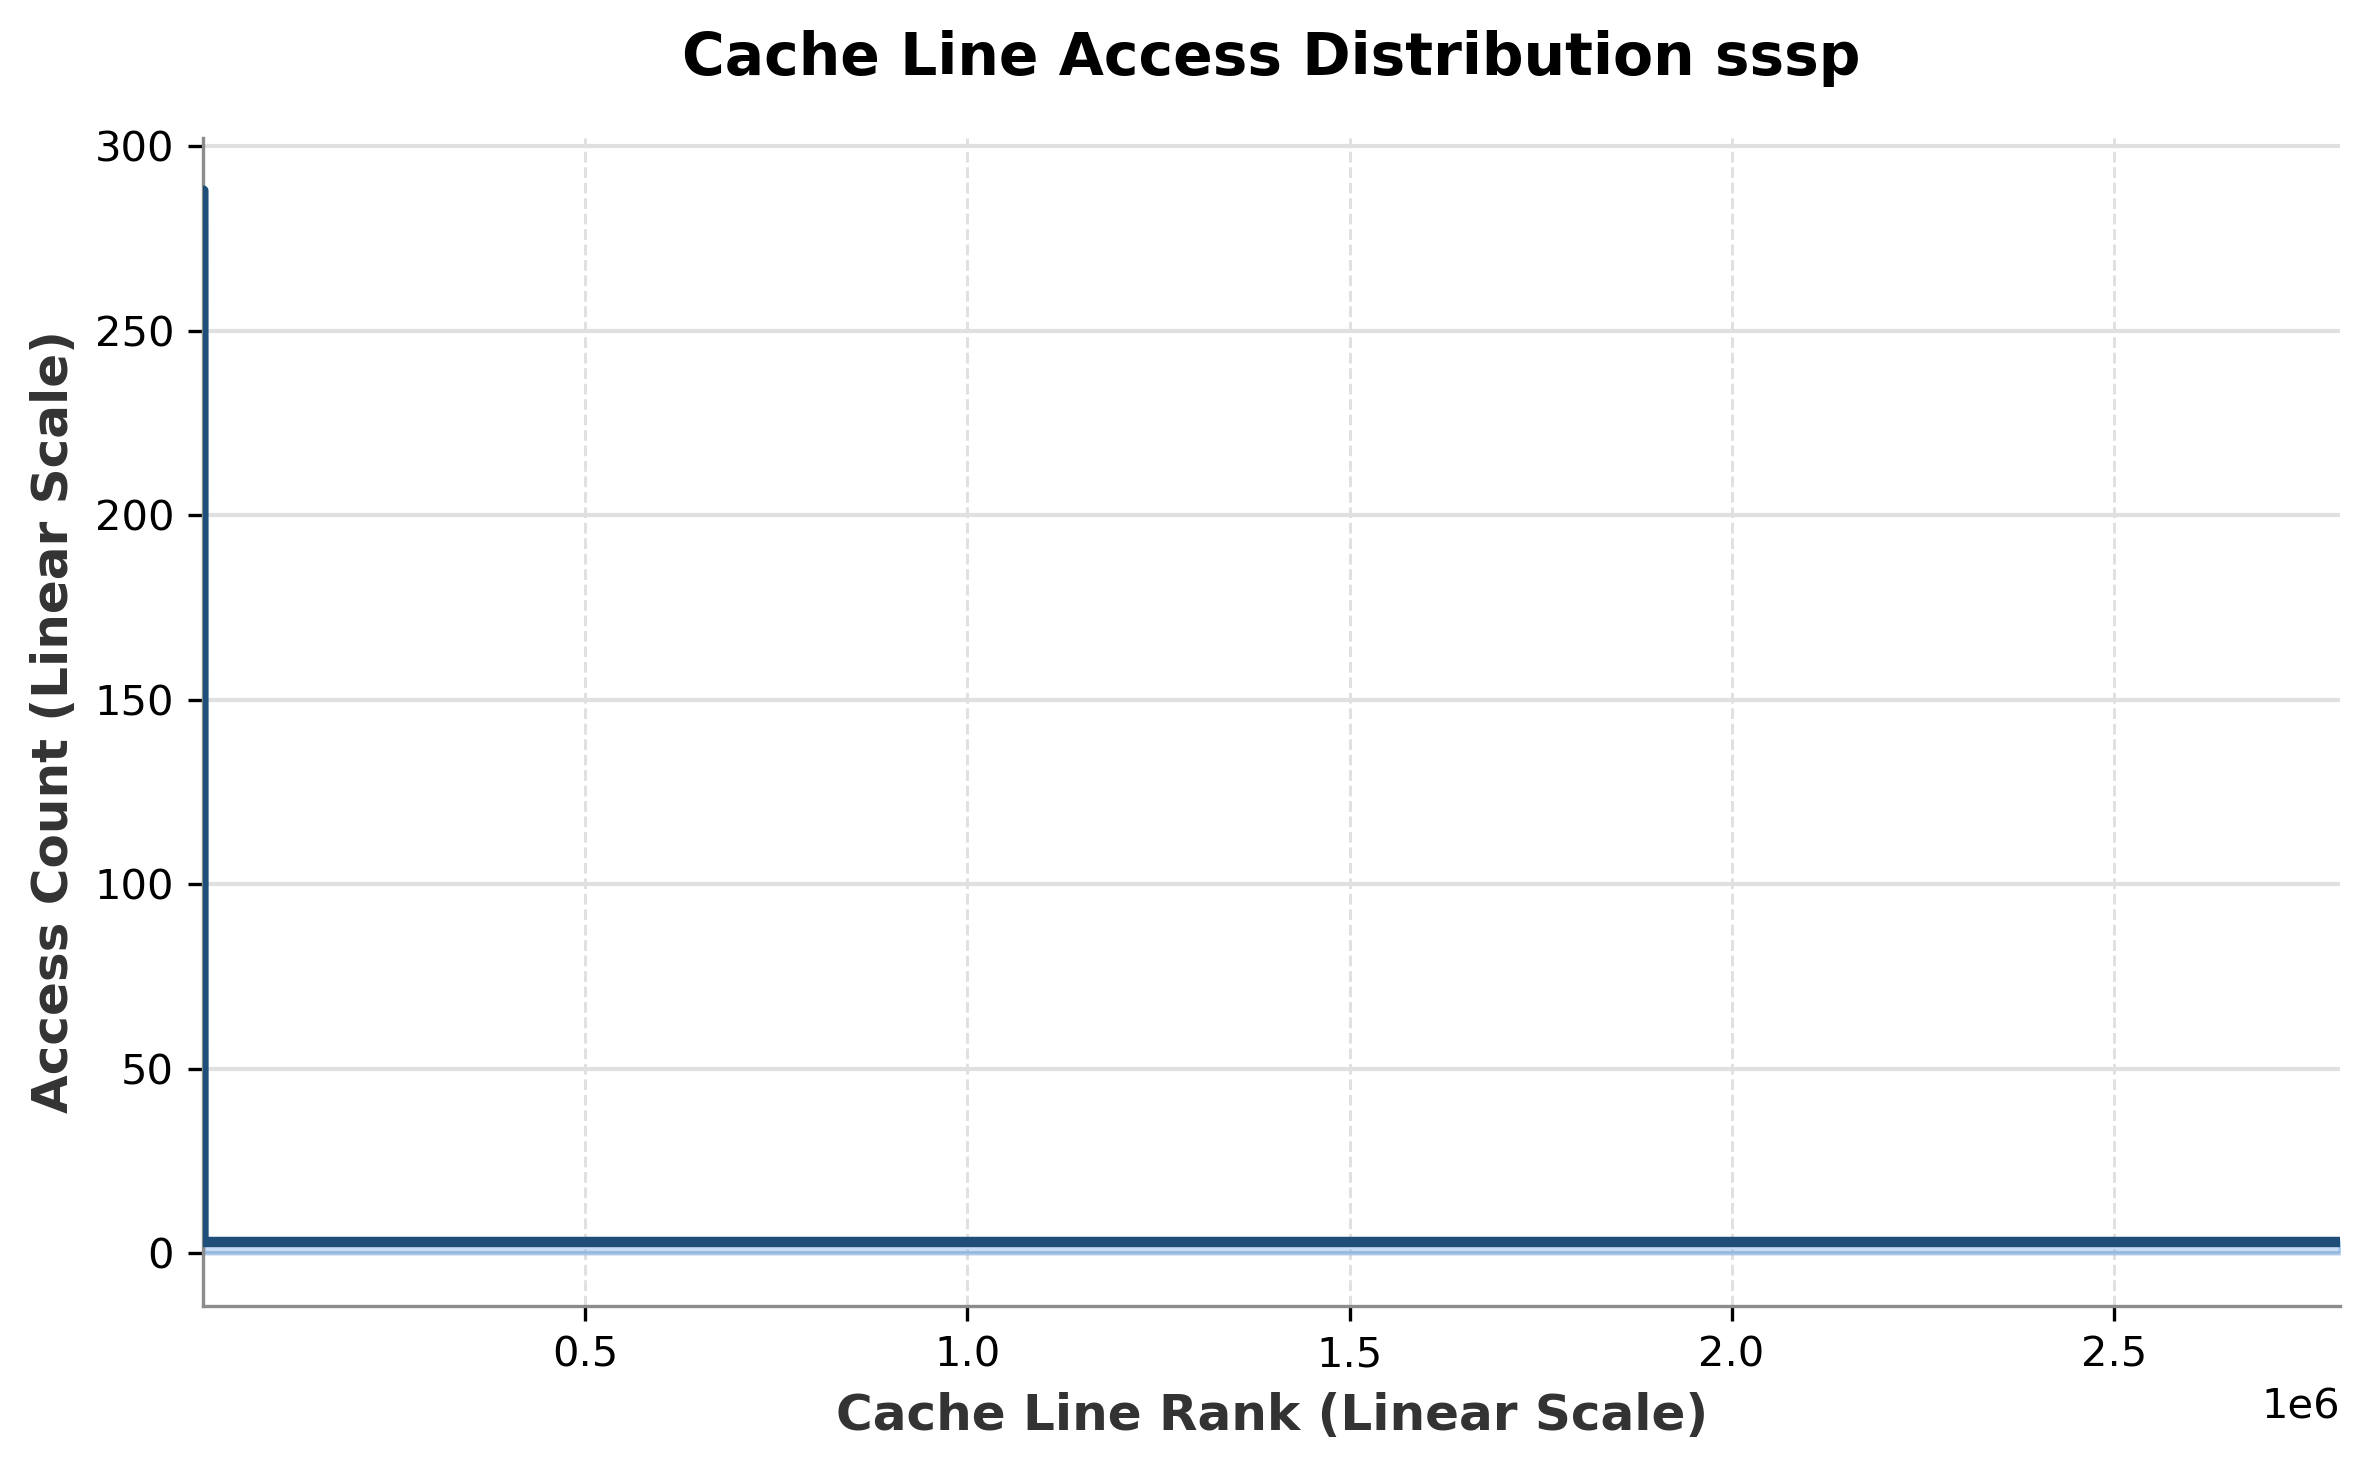

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/sssp_addr_access_count_ratio.png


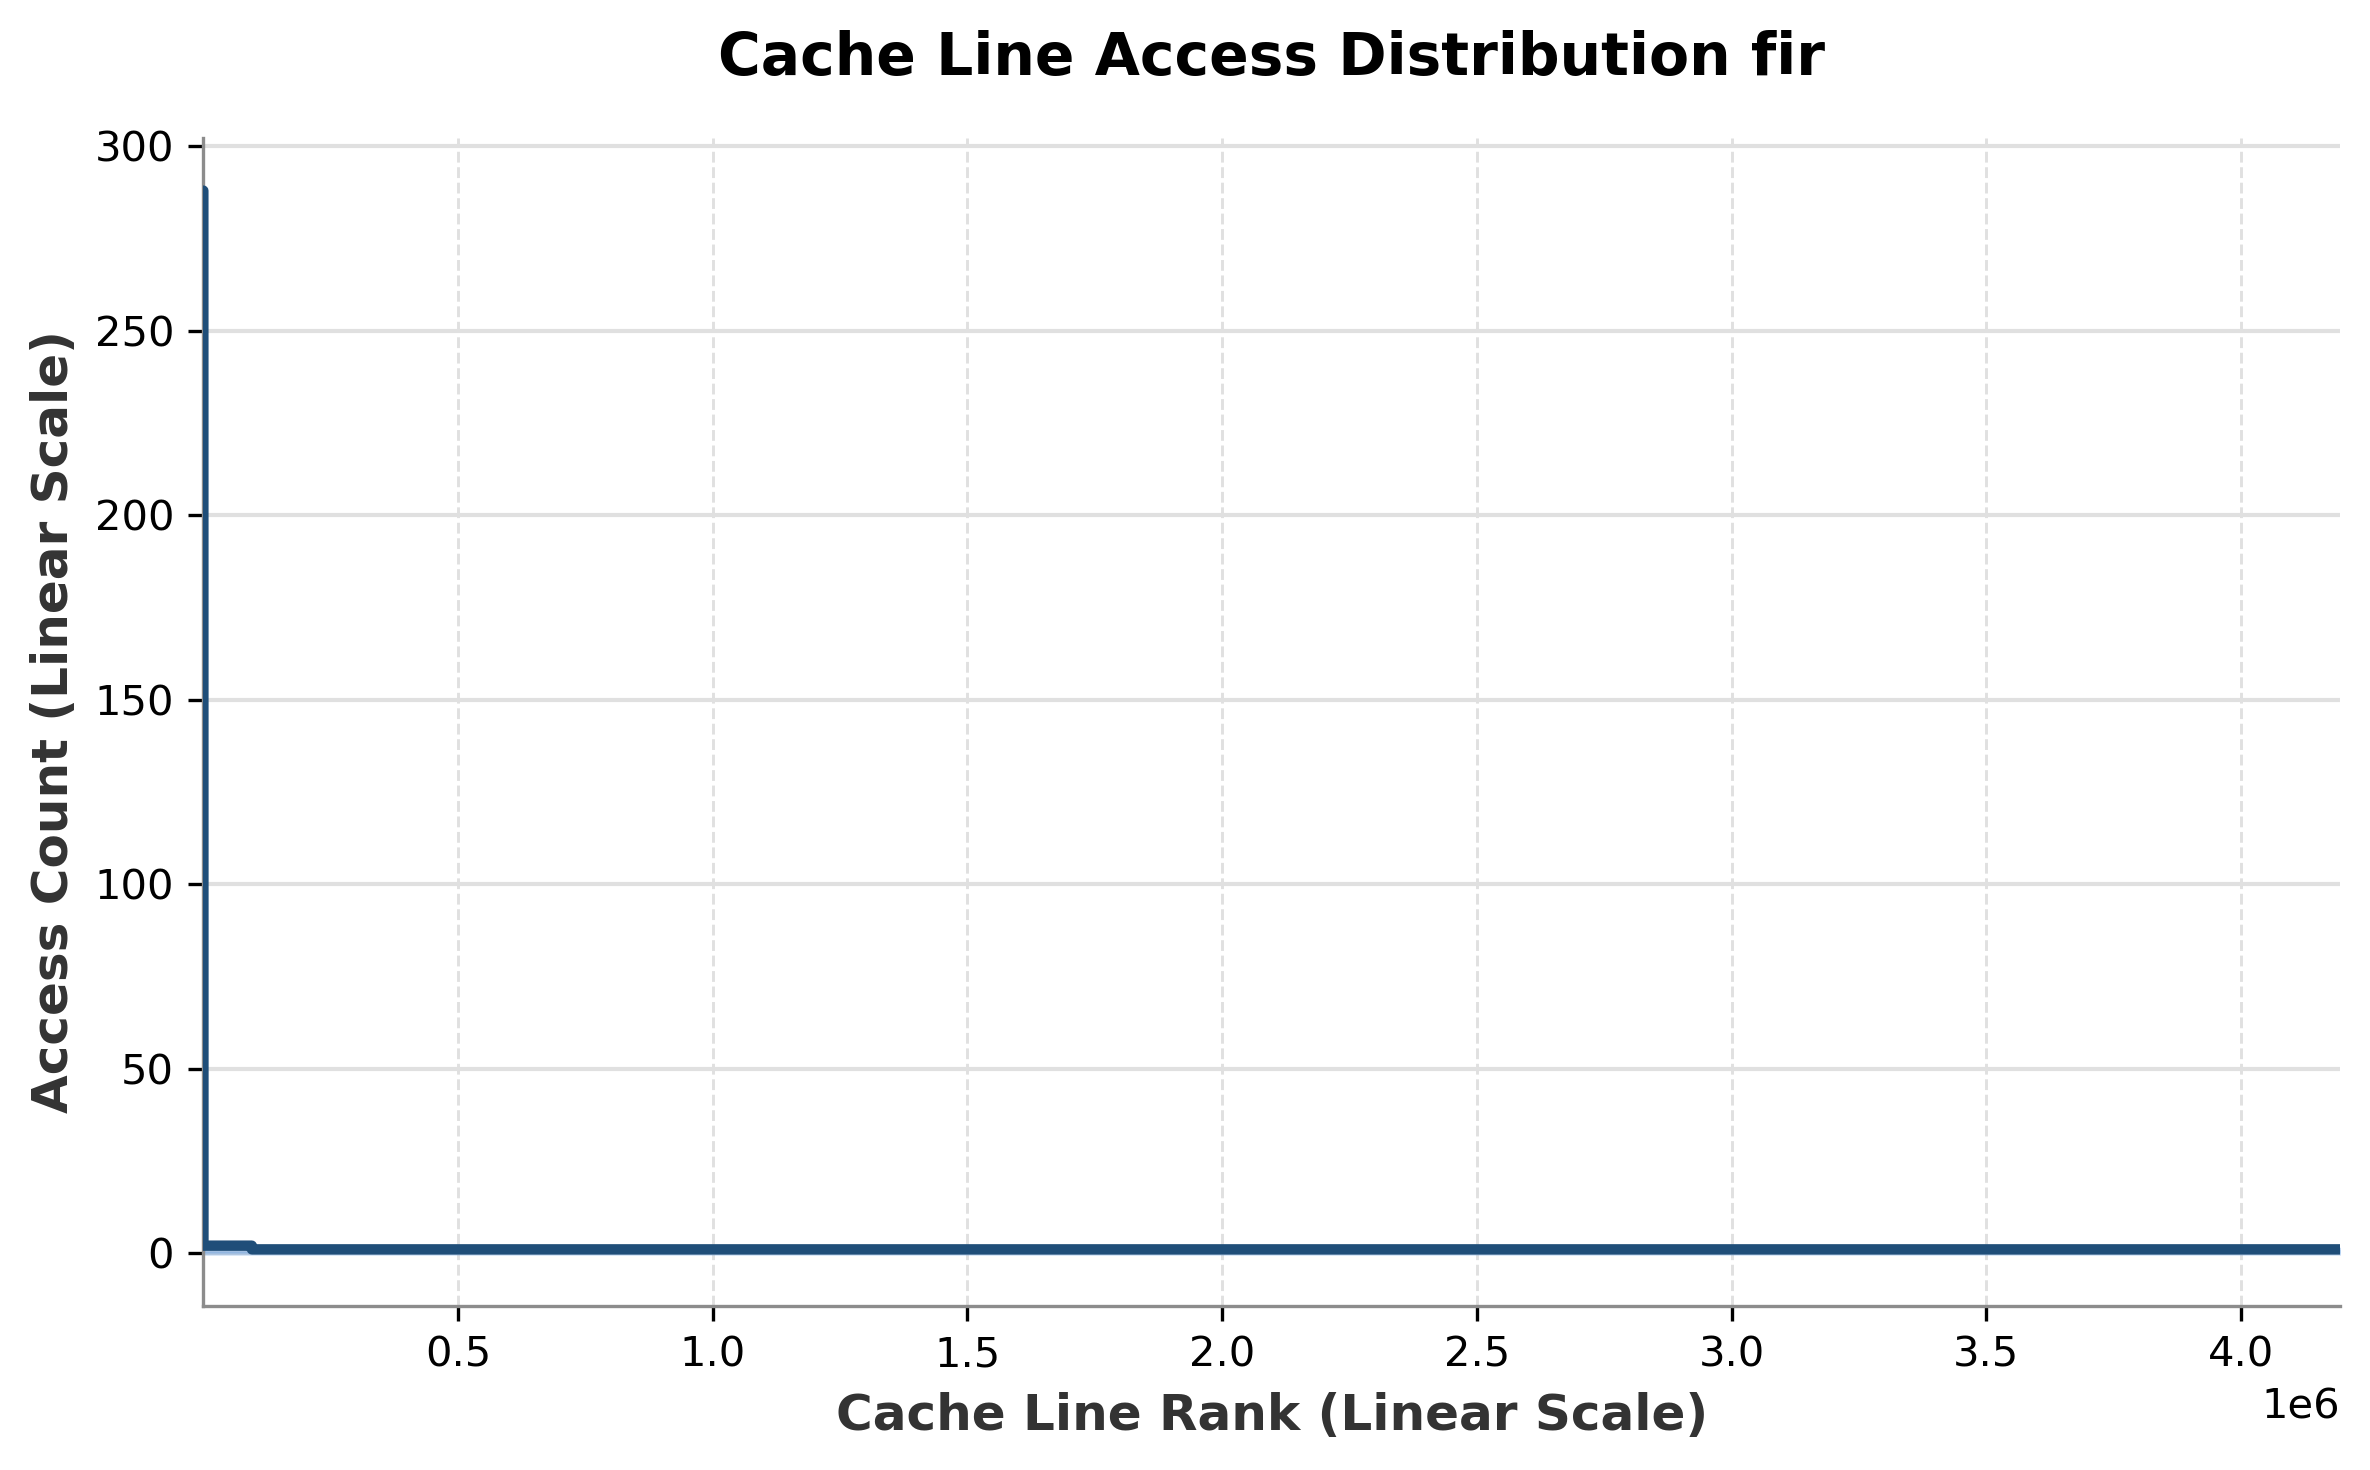

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/fir_addr_access_count_ratio.png


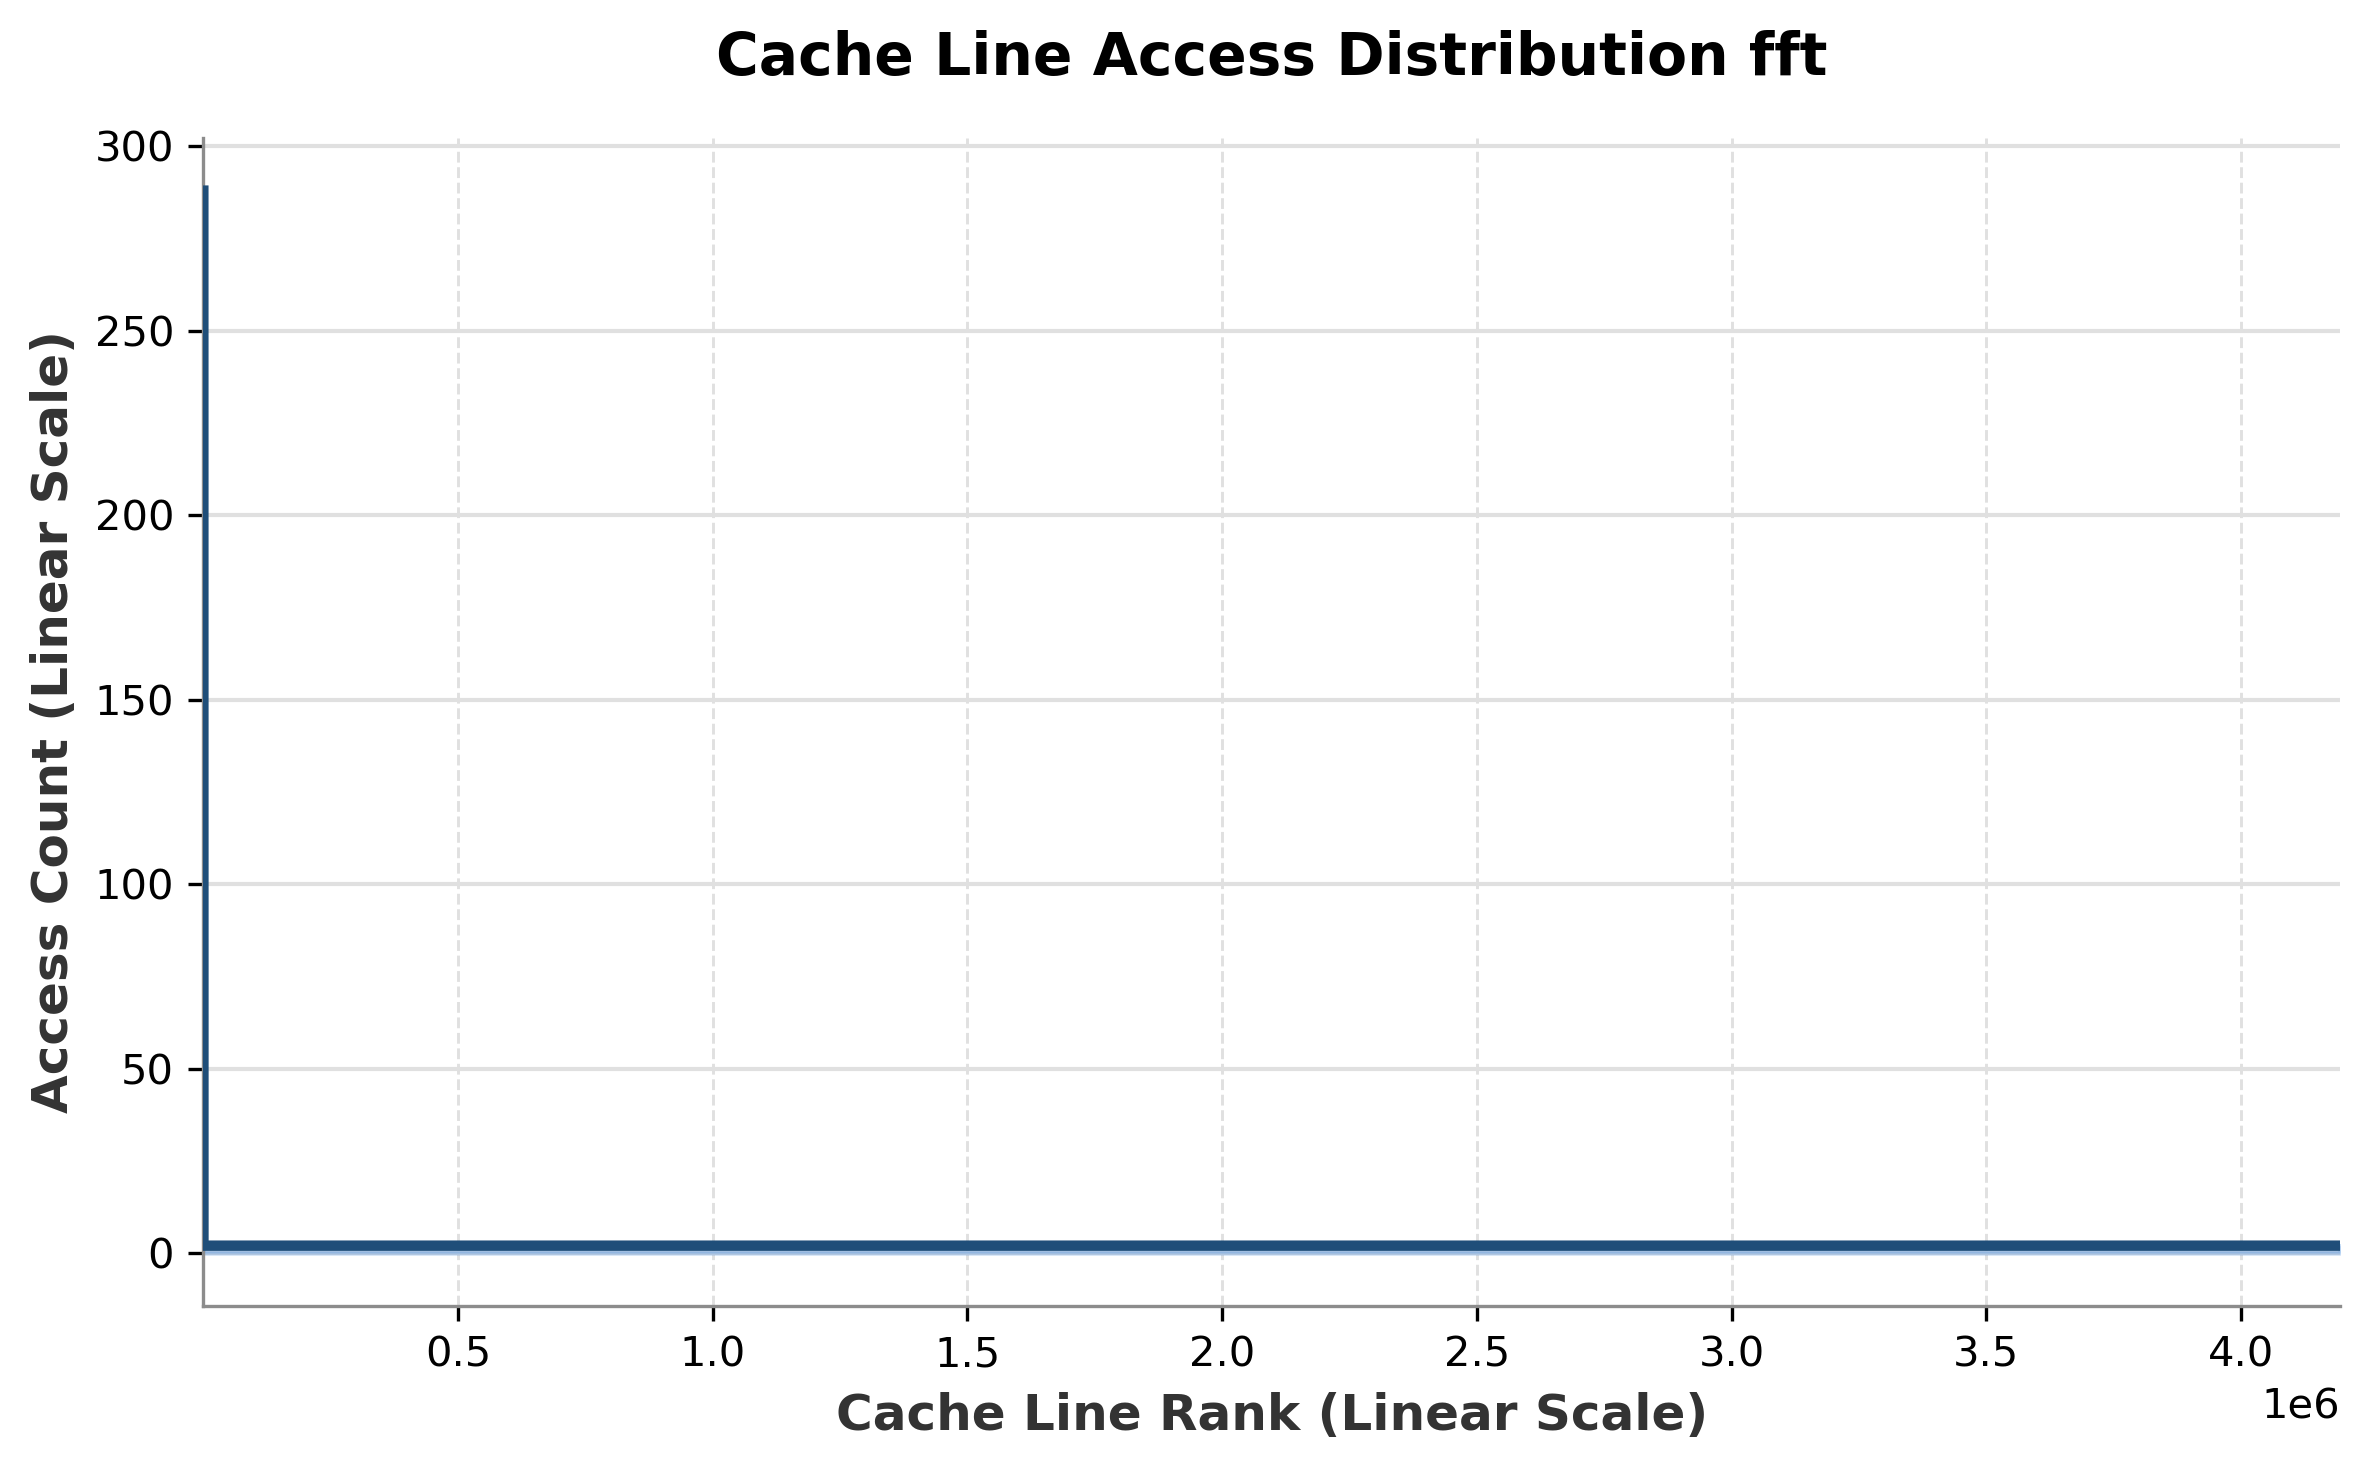

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/fft_addr_access_count_ratio.png


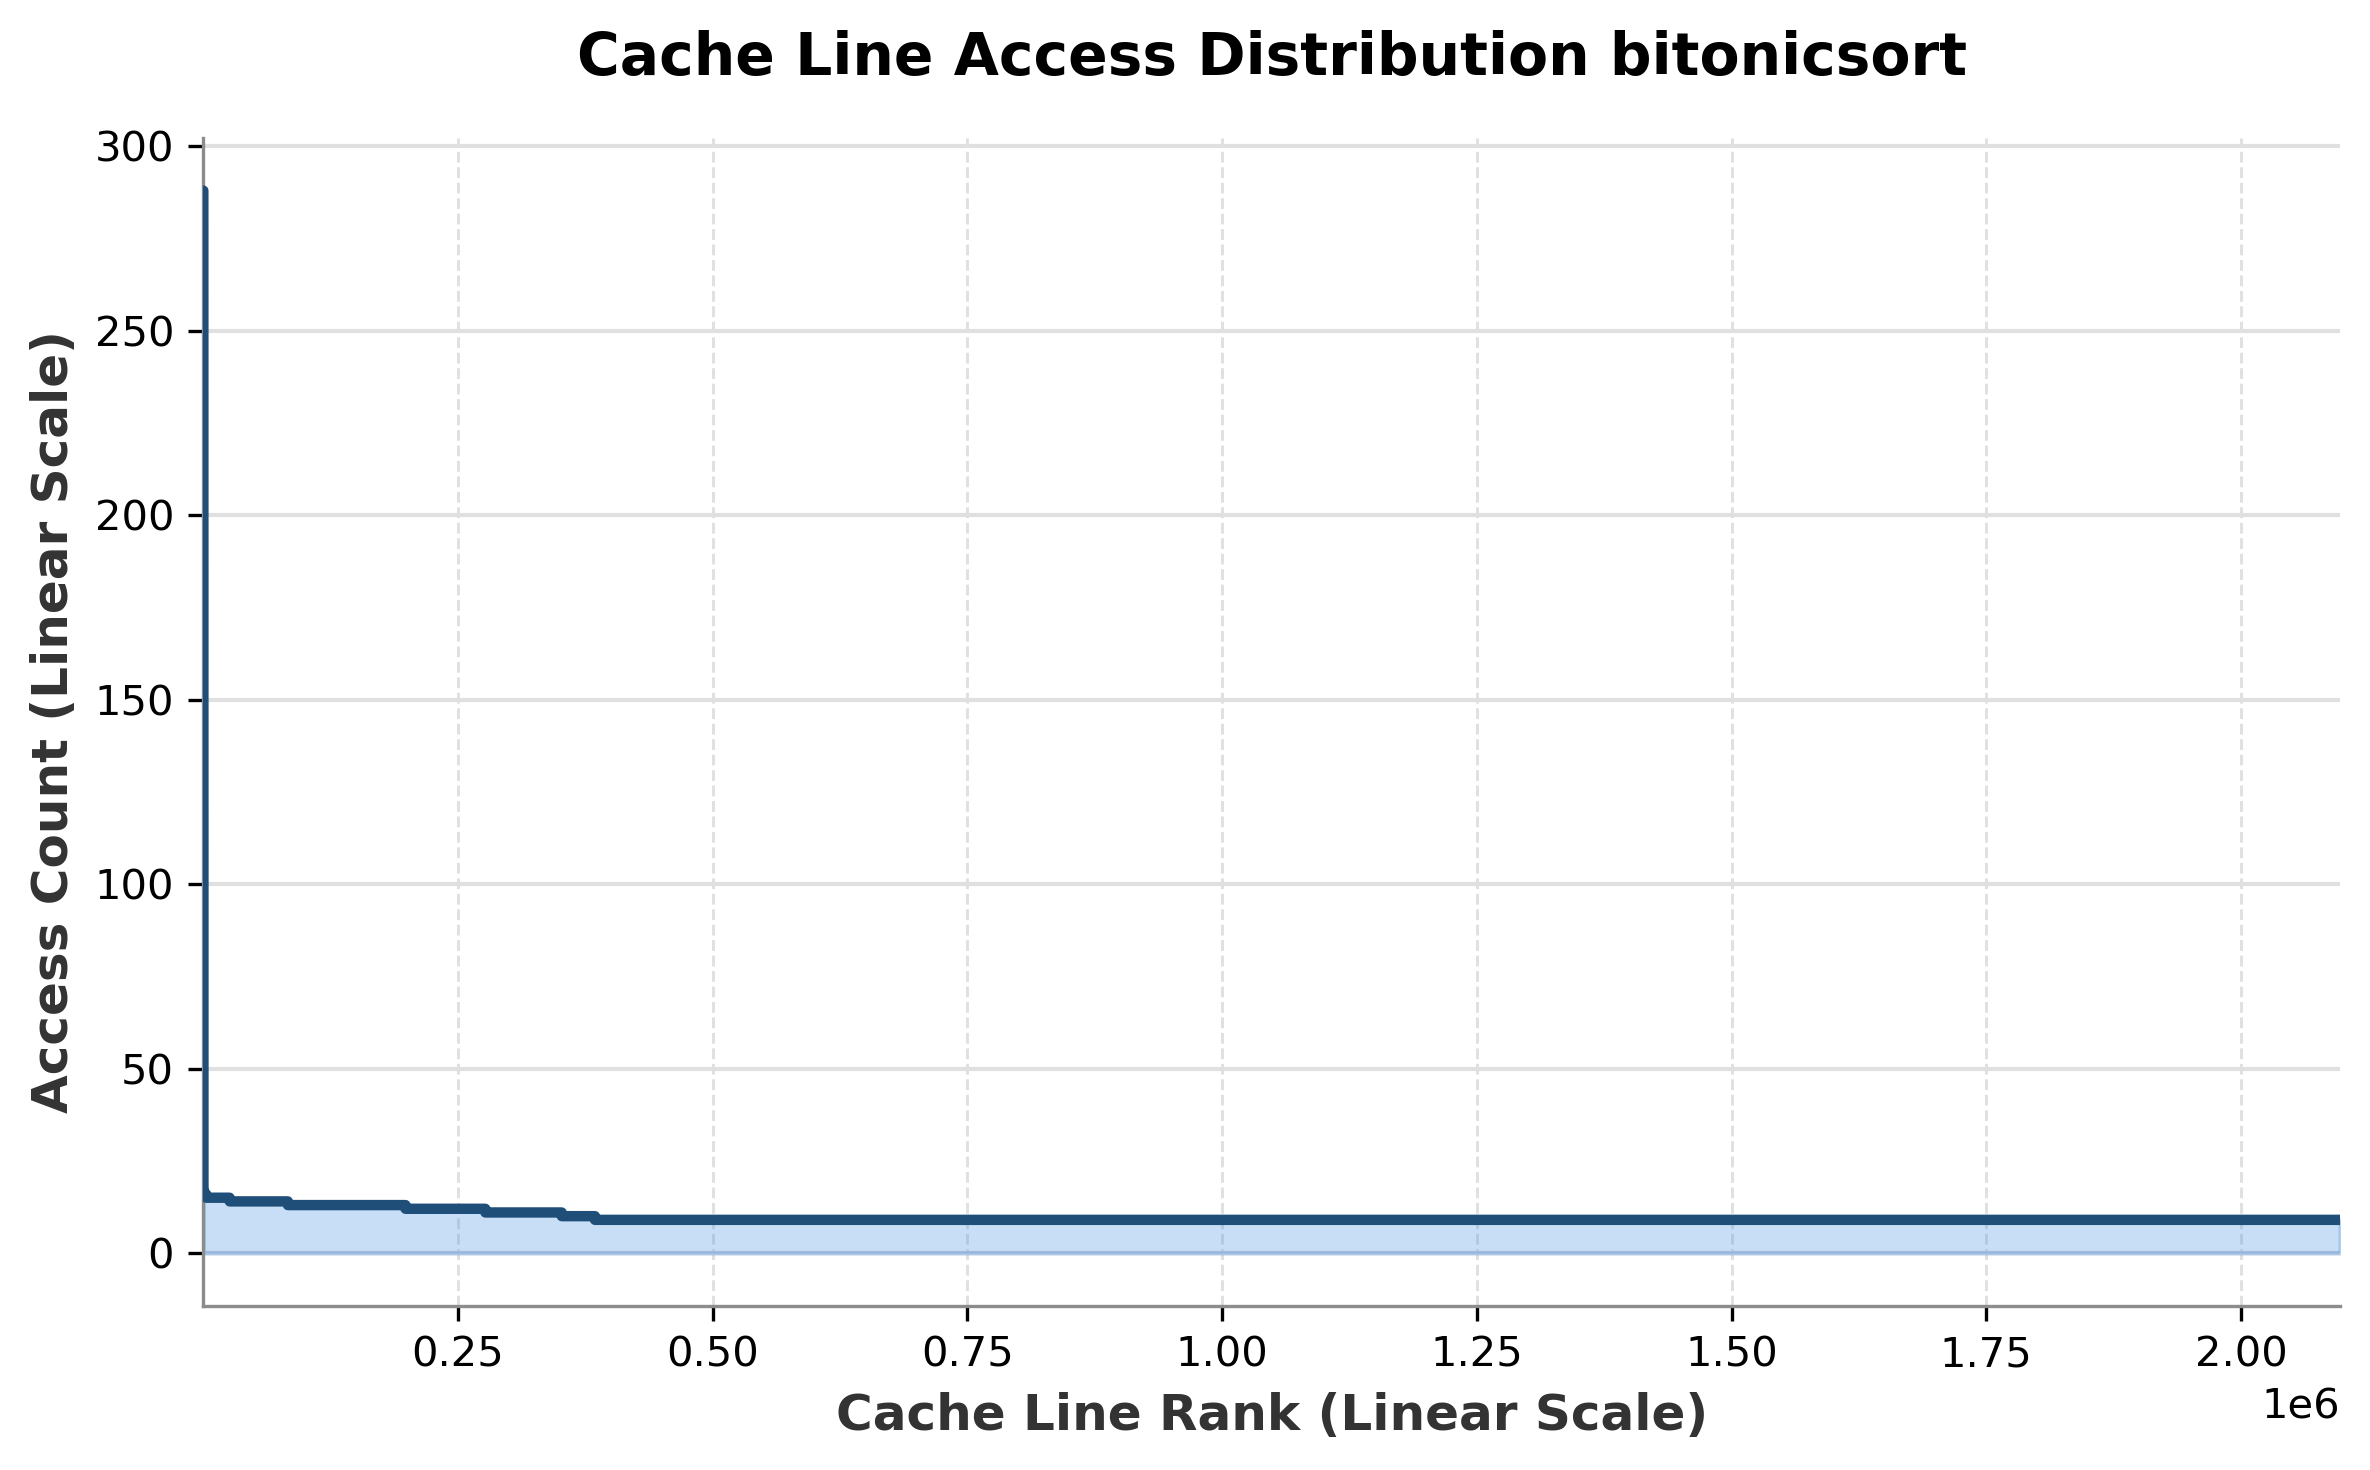

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/bitonicsort_addr_access_count_ratio.png


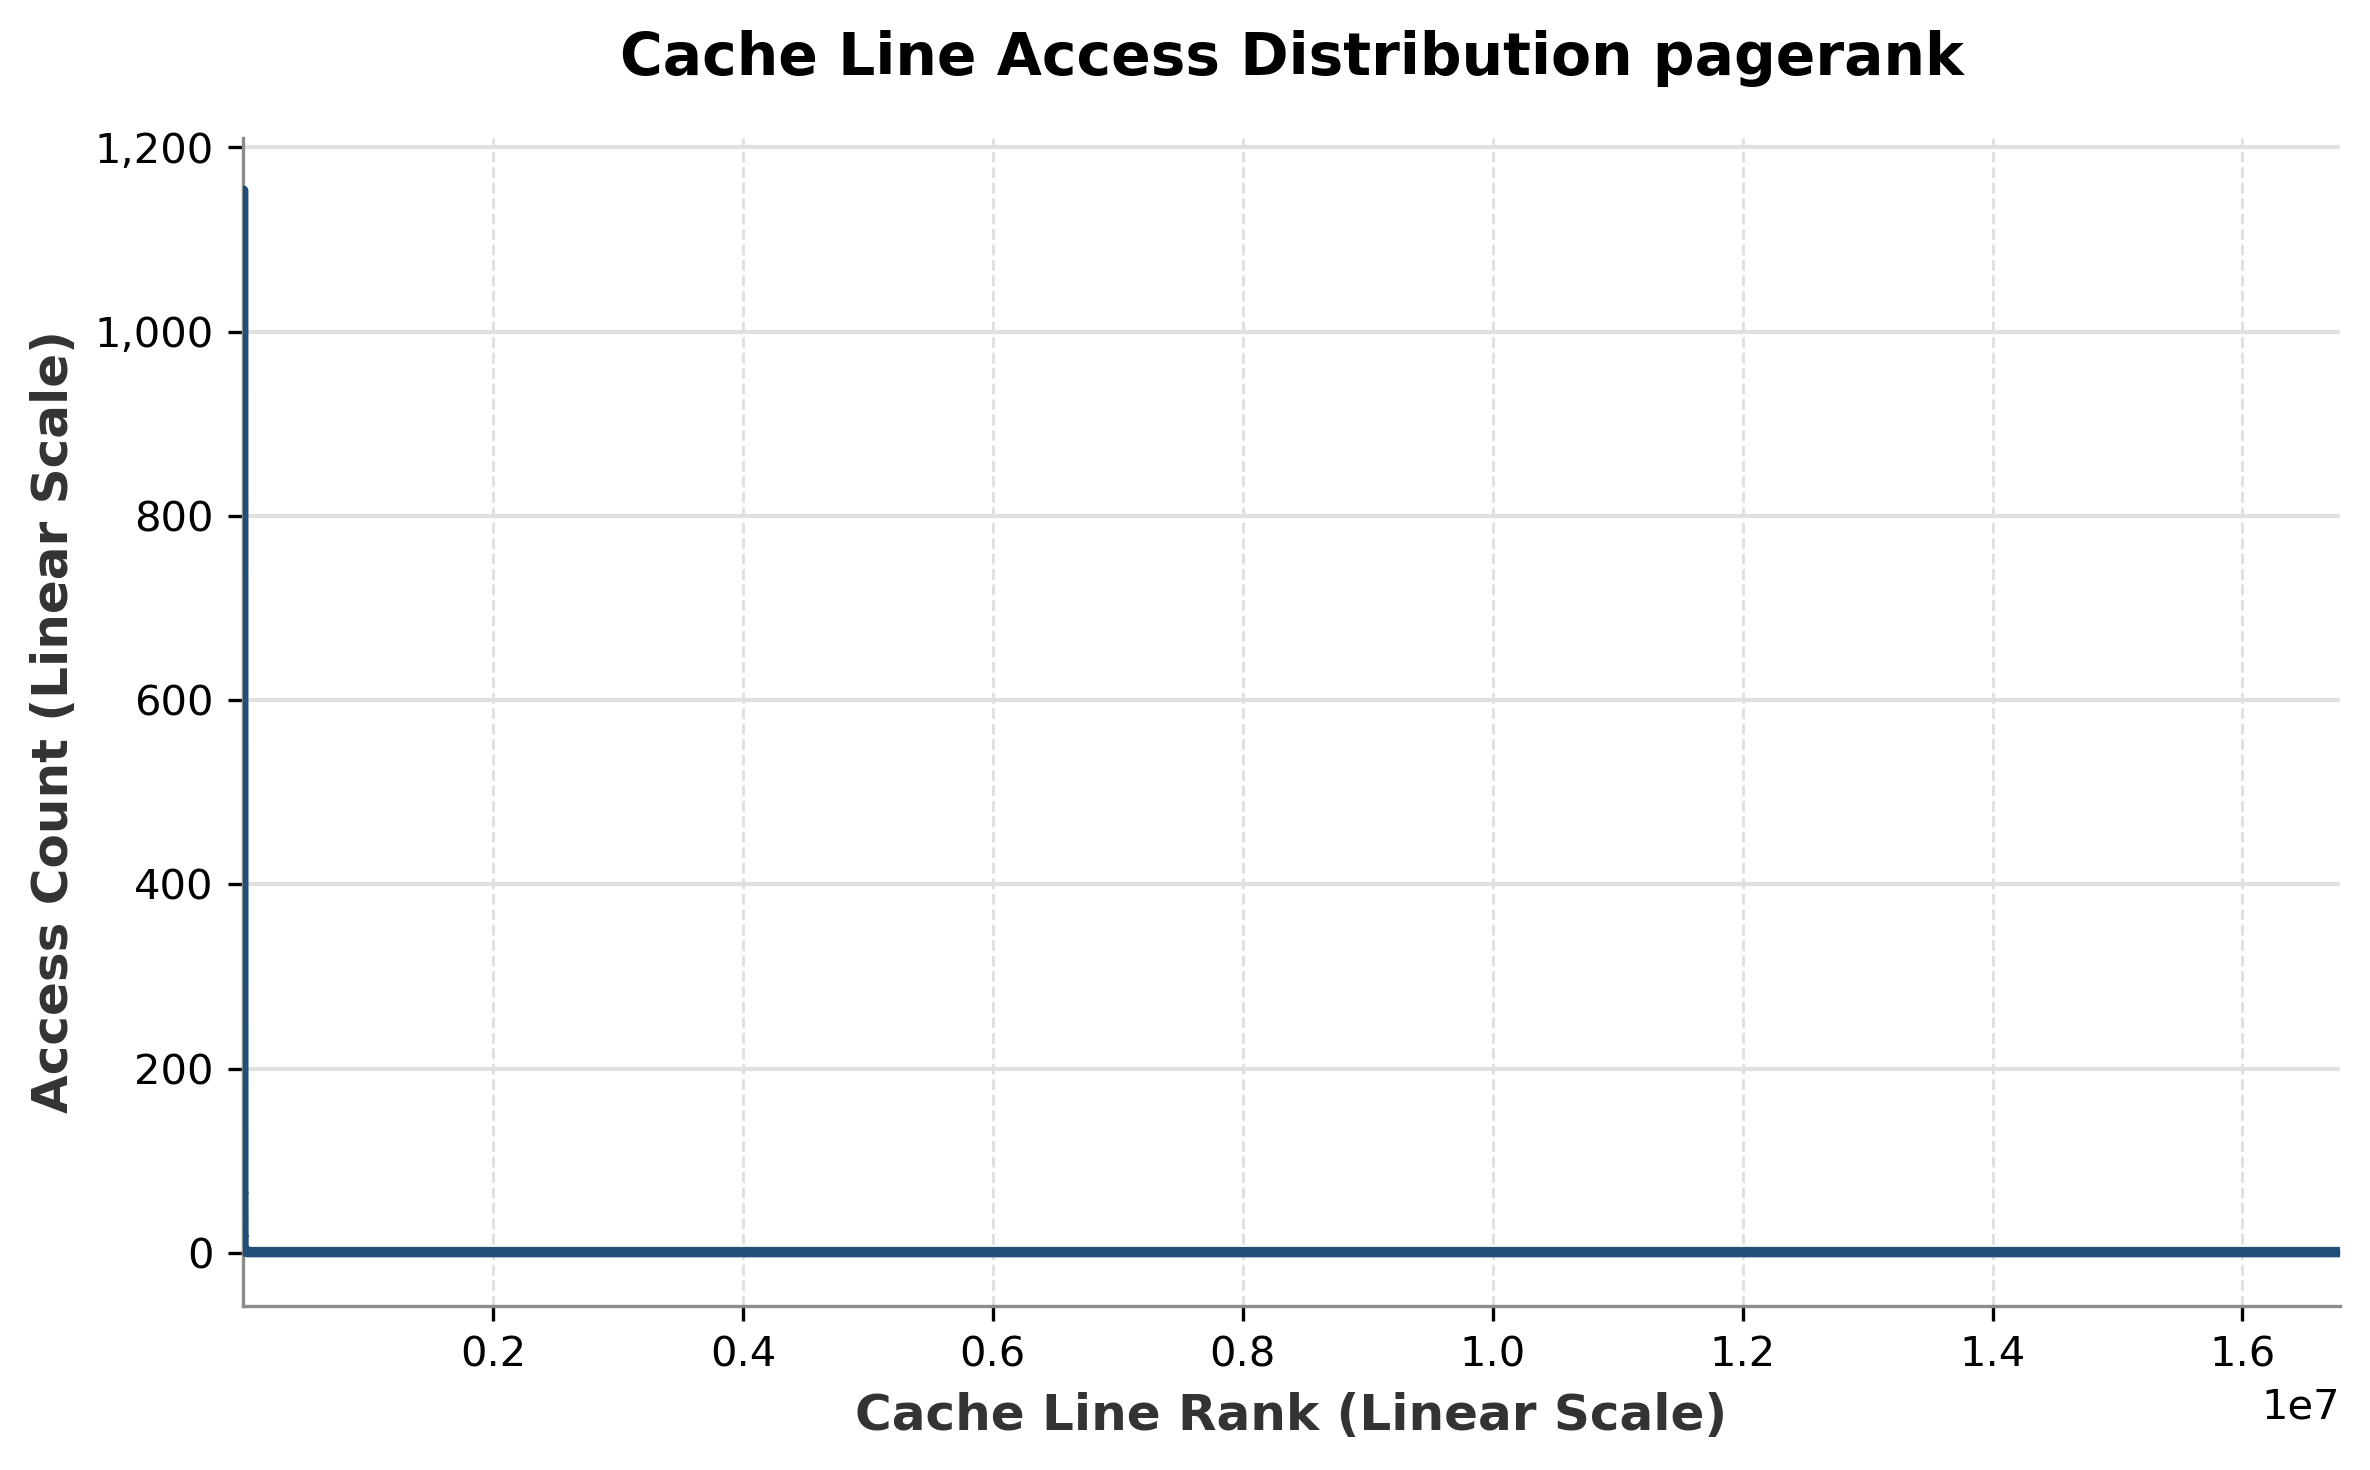

Save fig at: /home/ehdgus7279/mgvm/scripts/access-count-addrs/pagerank_addr_access_count_ratio.png


: 

In [ ]:
result_dir = f"/home/ehdgus7279/mgvm/scripts/access-count-addrs"

for benchmark in benchmarks:
    trace_file = f"{expanded_dir}/{benchmark}_mesh_6x6_memory_trace.csv"

    if not os.path.exists(trace_file):
        print(f"No {trace_file}, skip")
        continue

    df = pd.read_csv(trace_file, skipinitialspace=True)

    df = df.groupby('addr').agg({
        'access_count': 'sum'
    }).reset_index()

    df = df.sort_values(by='access_count', ascending=False)

    plot_hotspot_distribution(df, result_dir=result_dir, benchmark=benchmark)
